# ステージ7: ゲノム座位からの解析（eptA oligo metatranscriptome）

ステージ6（`6_pathway.ipynb`）の続き。**DEG がゲノム上のどこにあるか**を見る。

## 最終成果物

| ファイル | 中身 |
|---|---|
| `genome_browser_prototype.html` / `_en.html` | 全 9,675 遺伝子にホバーを付けた IGV 風ブラウザ（セル1・2） |
| `genome_static_A.png` / `_B.png` | 同じ内容の静的版。notebook 内で読む用（セル3） |

## 見ているもの

**3遺伝子以上 連続して同じ方向に動く DEG の座位** —
**(A) 343 区間 1,662 遺伝子 / (B) 298 区間 1,344 遺伝子**。

**(A) 全株プール**と**(B) 株ごと独立**は主従をつけず、どちらも出す（CLAUDE.md §7）。

## セル1: ゲノム座位から見た DEG — ゲノムブラウザを書き出す

ステージ6 図13 の genome map と `4_reads.ipynb` セル15-10-5 の「連続座位に影をつける」を一つにまとめ、
**全 9,675 遺伝子にホバーを付けた単一 HTML** を書き出す。

| 段 | 中身 |
|---|---|
| 上段 | **log2 FC。分子 KO / 分母 WT**（apeglm 収縮後。**疑似カウントは足していない**ので `log2((KO+1)/(WT+1))` ではない） |
| 下段 | **`log10(正規化カウント + 1)`** を 上向き = WT / 下向き = KO に背中合わせ（**+1 はこちらだけ**） |
| 帯 | **3遺伝子以上 連続して DEG が並ぶ区間**（赤 = 上昇 / 青 = 低下） |

クリックで **scheme (A)/(B)**、**株ごとに改行 / 1段に全部**、**帯の定義（連続 DEG / 同方向のみ）** を切り替える。
**y 軸は A/B 共通**なので、切り替えても点の位置がそのまま比較できる。

★ 手書き HTML なのは `pandoc` も `ggiraph` も無いため（CLAUDE.md §10）。HTML はブラウザが文字を描くので日本語が使える。

In [191]:
# ══════════════════════════════════════════════════════════════════
# セル1: ゲノム座位から見た DEG — IGV 風ゲノムブラウザを書き出す
# ══════════════════════════════════════════════════════════════════
# ステージ7 の最初のセル。ステージ6 図13 の genome map と
# 4_reads.ipynb セル15-10-5 の「連続座位に影をつける」を一つにまとめ、
# 全 9,675 遺伝子にホバーを付けた単一 HTML を書き出す。
#
# 何を描くか
#   上段 … log2 FC の散布。DEG は赤。y 軸の範囲外は下端に △
#          ★ 分子 KO / 分母 WT。DESeq2 の
#            lfcShrink(dds, coef = 'group_KO_vs_WT', type = 'apeglm') の値で、
#            疑似カウントは足していない。log2((KO+1)/(WT+1)) ではなく、
#            正規化カウントに当てた負の二項 GLM の係数（の apeglm 事後モード）
#   下段 … y=0 を基点に 上向き = WT / 下向き = KO の正規化カウントを
#          log10(count + 1) で背中合わせの棒に。DEG は赤で塗る
#          ★ +1 はこちらだけ。0 を log 軸に乗せるためのもの
#   帯   … 3遺伝子以上 連続して DEG が並ぶ区間（赤 = 上昇 / 青 = 低下）
#   ホバー… locus_tag / Preferred_name / product / K番号 / KEGG pathway /
#          KEGG module / EC / PFAM / COG / CAZy と、(A)(B) 両方の LFC・padj・カウント
#
# クリックで切り替えられるもの
#   scheme   (A) 全株プール  /  (B) 株ごと          … y 軸は A/B 共通にして点の位置を比較できる
#   並べ方   株ごとに改行     /  1段に全部
#   帯の定義 連続 DEG        /  同方向のみ          … 符号が変わると区間を切る
#
# ★ なぜ手書き HTML なのか（ステージ6 セル15 と同じ理由）
#   pandoc が無いので htmlwidgets::saveWidget(selfcontained=TRUE) が使えず、
#   ggiraph も未導入（CLAUDE.md §10）。9,675 点にホバーを付けるため canvas に自前で描く。
#   HTML はブラウザが文字を描くので日本語が使える（PNG の mbcsToSbcs 問題が無い）
#
# ★ このセルは単体で実行できる（ライブラリ・パス・res の読み込みを含む）

# ── (1) ライブラリ ────────────────────────────────────────────────
# ★ jsonlite 2.0.0 は metatx-lib-4.4 側にある（CLAUDE.md §10）
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
library(dplyr)
library(tidyr)
library(stringr)
suppressMessages(library(jsonlite))
cat(sprintf("R %s / jsonlite %s / dplyr %s\n",
            getRversion(), packageVersion('jsonlite'), packageVersion('dplyr')))

# ── (2) パス ──────────────────────────────────────────────────────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_de      = file.path(path, 'DESeq2')
path_pw      = file.path(path, 'pathway')
dir_gb       = file.path(path, 'genome')          # ステージ7 の出力先
if (!dir.exists(dir_gb)) dir.create(dir_gb, recursive = TRUE)

f_deA = file.path(path_de, 'A_de.csv')   # (A) 全株プール
f_deB = file.path(path_de, 'B_de.csv')   # (B) 株ごと
for (x in c(f_deA, f_deB))
    cat(sprintf('%-24s %s\n', basename(x), ifelse(file.exists(x), 'OK', '!! 無い')))

# ── (3) res を作る（ステージ6 セル3 と同じ）──────────────────────
# ── ステージ5 の結果を読む ─────────────────────────────────────
# (A) と (B) を1つの表にまとめる。ステージ6 はこの表だけで進む
deA = read.csv(f_deA, stringsAsFactors = FALSE)
deB = read.csv(f_deB, stringsAsFactors = FALSE)

# B_de.csv には既に LFC_A / padj_A / stat_A / AvsB が入っている（5_2 セル11）。
# (A) にしか無い pME008 の10遺伝子を足して、全 9,795 遺伝子の表にする
res = deA %>%
    dplyr::select(gene_id, strain, product, marker, biotype, mappability,
                  contig, strand, start, end,
                  Preferred_name, KEGG_ko, KEGG_Pathway, COG_category,
                  PFAMs, EC, CAZy, Description,
                  baseMean, LFC_A = LFC_shrunk, padj_A = padj, stat_A = stat_Wald,
                  normA_WT = norm_WT_mean, normA_KO = norm_KO_mean,
                  normA_diff = norm_diff) %>%
    left_join(deB %>% dplyr::select(gene_id, LFC_B, padj_pooled, padj_bystrain,
                                    stat_B, normB_WT = normB_WT_mean,
                                    normB_KO = normB_KO_mean, normB_diff, AvsB),
              by = 'gene_id') %>%
    mutate(sigA = !is.na(padj_A)      & padj_A      < 0.05,
           sigB = !is.na(padj_pooled) & padj_pooled < 0.05)

# ── (4) ブラウザ用のデータを作る ─────────────────────────────────
suppressMessages(library(jsonlite)); library(stringr); options(width=210)

# ★ module の出典を 6_pathway.ipynb セル7-6 と完全に統一する。
#
#   当初は emapper の注釈ファイルから引いていたが、2つ問題があった:
#   (1) 列番号の取り違え。emapper は 13=KEGG_Pathway / 14=KEGG_Module なのに
#       13 を KEGG_Module と名づけていたため、module 行に pathway の ko/map
#       番号が入り pathway 行と完全に重複していた（M 番号 0 本 / 2,396 本中）。
#   (2) 14列目に直した後も、eggNOG の KEGG スナップショットが古く
#       M009xx / M01xxx を1つも持たない（実測: セル7-6 の 248 module のうち
#       M009xx 35 個・M01xxx 28 個が emapper 側に存在しない）。
#       セル7-6 の目玉である CPS グリカンの M00922 / M01011 / M01029 /
#       M01030 / M01031 が丸ごと落ち、ホバーに絶対出てこなかった。
#
#   そこでセル7-6 と同じ経路で引く:
#       res$KEGG_ko（K番号）→ KEGG 公式の module-K 対応 → M番号
#   被覆は 14.8% → 12.2% と下がるが、ノートブックの解析結果と一致する。
#
# ★ 版はセル7-6 と同じ日付で固定する。KEGG は毎日更新されるため。
#   取得済みファイルを読むだけにして、ここでは KEGG API を叩かない
MOD_VER = '261028'
f_mod_keg  = file.path(path, sprintf('ref/ko00002_%s.keg', MOD_VER))
f_mod_link = file.path(path, sprintf('ref/module_ko_%s.tsv', MOD_VER))
stopifnot(file.exists(f_mod_keg), file.exists(f_mod_link))

# ko00002.keg の D 行から M番号を拾う（セル7-6 と同じ読み方）
mod_ids = character(0)
for (l in readLines(f_mod_keg, warn = FALSE)) {
    if (startsWith(l, 'D')) {
        m = str_match(l, '^D\\s+(M[0-9]+)\\s')
        if (!is.na(m[1])) mod_ids = c(mod_ids, m[2])
    }
}
mod_ids = unique(mod_ids)

# M番号 → K番号。階層に載っている module だけに絞る（セル7-6 の inner_join と同じ）
mod_ko = read.delim(f_mod_link, stringsAsFactors = FALSE) %>%
         transmute(M = sub('^md:', '', module), K = sub('^ko:', '', ko)) %>%
         filter(M %in% mod_ids) %>% distinct()

# 遺伝子ごとに M番号をカンマで並べる（ホバーの pathway 行と同じ見た目にする）
mod_gene = res %>% filter(!is.na(KEGG_ko), KEGG_ko != '-', KEGG_ko != '') %>%
    dplyr::select(gene_id, KEGG_ko) %>%
    tidyr::separate_rows(KEGG_ko, sep = ',') %>%
    transmute(gene_id, K = str_trim(sub('^ko:', '', KEGG_ko))) %>%
    filter(K != '') %>%
    inner_join(mod_ko, by = 'K', relationship = 'many-to-many') %>%
    distinct(gene_id, M) %>% arrange(gene_id, M) %>%
    group_by(gene_id) %>%
    summarise(KEGG_Module = paste(M, collapse = ','), .groups = 'drop')
cat(sprintf("■ KEGG module（MOD_VER %s / セル7-6 と同一経路）: 階層の module %d 種 / M-K 対応 %d 行 / %d 遺伝子に付与\n",
    MOD_VER, length(mod_ids), nrow(mod_ko), nrow(mod_gene)))

# ★ (A) か (B) のどちらかで検定された遺伝子の和集合を対象にする
#   （A のみ 37 / B のみ 46 本ある）
#   ★ ただし「描くかどうか」を決めるのは padj ではなく LFC の有無。実測では
#     (A) は 9,675 本すべてに LFC があり、(B) だけ 10 本（pME008 の CDS 全部）が
#     NA になる。(B) は株ごとに独立に回すのでプラスミドがモデルに入らないため。
#     LFC はあるが padj が NA の遺伝子（(A) 46 / (B) 27。実測で全件 Cook 距離の
#     外れ値）は灰色のまま描かれる
g = res %>% filter(!marker, biotype=='CDS', !is.na(padj_A) | !is.na(padj_pooled)) %>%
    left_join(mod_gene, by='gene_id') %>%
    mutate(across(c(Preferred_name,KEGG_ko,KEGG_Pathway,KEGG_Module,EC,PFAMs,COG_category,CAZy),
                  ~ifelse(is.na(.)|.=='-', '', .)),
           mid = (start+end)/2,
           degA = as.integer(!is.na(padj_A) & padj_A < 0.05),
           degB = as.integer(!is.na(padj_pooled) & padj_pooled < 0.05)) %>%
    arrange(strain, contig, mid)
cat(sprintf("■ 対象: %d 遺伝子（A 検定済 %d / B 検定済 %d）\n", nrow(g),
            sum(!is.na(g$padj_A)), sum(!is.na(g$padj_pooled))))

strains4 = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')
panel_ord = c(strains4, 'pME008')

# ── 連続 DEG 座位（スキームごと）──────────────────────────────
# pure = FALSE: DEG が連続していれば方向が混ざっていても1区間（従来）
# pure = TRUE : 上昇 DEG と低下 DEG が隣り合うとそこで区間を切る
mkruns = function(sc, pure = FALSE) {
  g %>% group_by(strain, contig) %>%
    mutate(deg = if (sc=='A') degA else degB,
           lf  = if (sc=='A') LFC_A else LFC_B,
           # key は 0（非 DEG）/ +1（上昇 DEG）/ -1（低下 DEG）の3値。
           # pure なら符号が変わった時点で cumsum が進むので区間が切れる
           key = deg * (if (pure) sign(ifelse(is.na(lf), 0, lf)) else 1L),
           grp = cumsum(key != lag(key, default = 0L))) %>%
    filter(deg == 1) %>% group_by(strain, contig, grp) %>%
    summarise(n = dplyr::n(), x0 = min(start), x1 = max(end),
              up = sum(lf > 0, na.rm=TRUE), dn = sum(lf < 0, na.rm=TRUE),
              g0 = first(gene_id), g1 = last(gene_id), .groups='drop') %>%
    filter(n >= 3) %>% mutate(dir = ifelse(up >= dn, 'up', 'dn'))
}
runsA  = mkruns('A');             runsB  = mkruns('B')
runsAd = mkruns('A', pure = TRUE); runsBd = mkruns('B', pure = TRUE)
cat(sprintf("■ 連続 DEG 座位（方向混在可）: (A) %d / (B) %d\n", nrow(runsA), nrow(runsB)))
cat(sprintf("■ 連続 DEG 座位（同方向のみ）: (A) %d / (B) %d\n", nrow(runsAd), nrow(runsBd)))
for (nm in c('runsA','runsB','runsAd','runsBd')) {
  r = get(nm)
  cat(sprintf("   %-6s n>=3 %4d 箇所 / 上昇 %3d・低下 %3d / 最大 %2d 遺伝子\n",
      nm, nrow(r), sum(r$dir=='up'), sum(r$dir=='dn'), max(r$n)))
}

# ── eptA マーカー（両スキームぶん）────────────────────────────
ept = res %>% filter(marker) %>%
    transmute(strain, contig, mid = round((start+end)/2), gene_id, strand, start, end,
              kind = sub('^.*_(deleted|retained|3p|5p)$','\\1',gene_id),
              len = end-start+1,
              lfA = round(LFC_A,2), pjA = signif(padj_A,2),
              wA = round(normA_WT), oA = round(normA_KO),
              lfB = round(LFC_B,2), pjB = signif(padj_pooled,2),
              wB = round(normB_WT), oB = round(normB_KO)) %>%
    mutate(locus = sub('_(deleted|retained|3p|5p)$','',gene_id)) %>%
    arrange(strain, contig, locus, ifelse(strand=='-', -start, start)) %>%
    dplyr::select(-locus, -start, -end)

ctg = g %>% group_by(strain, contig) %>%
    summarise(n = dplyr::n(), len = max(end), .groups='drop') %>%
    arrange(match(strain, panel_ord), desc(len))

nn = function(x) ifelse(is.na(x), NA, x)
mkpanel = function(s, c0) {
    d = g %>% filter(strain == s, contig == c0)
    rA  = runsA  %>% filter(strain==s, contig==c0); rB  = runsB  %>% filter(strain==s, contig==c0)
    rAd = runsAd %>% filter(strain==s, contig==c0); rBd = runsBd %>% filter(strain==s, contig==c0)
    mkr = function(r) lapply(seq_len(nrow(r)), function(i)
        list(x0=r$x0[i], x1=r$x1[i], n=r$n[i], up=r$up[i], dn=r$dn[i],
             dir=r$dir[i], g0=r$g0[i], g1=r$g1[i]))
    list(strain=s, contig=c0, len=max(d$end), n=nrow(d), pos=round(d$mid),
         A = list(lfc=round(nn(d$LFC_A),3), deg=d$degA,
                  wt=round(log10(d$normA_WT+1),3), ko=round(log10(d$normA_KO+1),3),
                  runs=mkr(rA), runsd=mkr(rAd)),
         B = list(lfc=round(nn(d$LFC_B),3), deg=d$degB,
                  wt=round(log10(d$normB_WT+1),3), ko=round(log10(d$normB_KO+1),3),
                  runs=mkr(rB), runsd=mkr(rBd)),
         ann = lapply(seq_len(nrow(d)), function(i) {
             o = list(g=d$gene_id[i], pr=substr(d$product[i],1,60))
             if (d$Preferred_name[i]!='') o$nm = d$Preferred_name[i]
             if (d$KEGG_ko[i]      !='') o$k  = gsub('ko:','',d$KEGG_ko[i])
             if (d$KEGG_Pathway[i] !='') o$pw = d$KEGG_Pathway[i]
             if (d$KEGG_Module[i]  !='') o$md = d$KEGG_Module[i]
             if (d$EC[i]           !='') o$ec = d$EC[i]
             if (d$PFAMs[i]        !='') o$pf = d$PFAMs[i]
             if (d$COG_category[i] !='') o$cg = d$COG_category[i]
             if (d$CAZy[i]         !='') o$cz = d$CAZy[i]
             o$lfA=round(nn(d$LFC_A[i]),2); o$pjA=signif(nn(d$padj_A[i]),2)
             o$wA=round(nn(d$normA_WT[i])); o$oA=round(nn(d$normA_KO[i]))
             o$lfB=round(nn(d$LFC_B[i]),2); o$pjB=signif(nn(d$padj_pooled[i]),2)
             o$wB=round(nn(d$normB_WT[i])); o$oB=round(nn(d$normB_KO[i])); o }),
         ept = { e = ept %>% filter(strain==s, contig==c0)
                 lapply(seq_len(nrow(e)), function(j) as.list(e[j,-(1:2)])) })
}
panels = lapply(seq_len(nrow(ctg)), function(i) mkpanel(ctg$strain[i], ctg$contig[i]))

maxLfc = max(abs(c(g$LFC_A, g$LFC_B)), na.rm=TRUE)
maxCnt = max(log10(c(g$normA_WT,g$normA_KO,g$normB_WT,g$normB_KO)+1), na.rm=TRUE)
# ── (5) JSON に書き出す ──────────────────────────────────────────
# ★ digits = NA が必須。jsonlite::toJSON の digits 既定は 4 で、しかも
#   「有効数字」ではなく「小数点以下4桁」に丸めるので、上で signif() を使って
#   決めた精度がここで上書きされ p 値が壊れる（CLAUDE.md §6-8）。
#   既定のままだと padj 19,267 個のうち 391 個が 0 に、17,390 個が
#   1e-4 の整数倍になっていた（実測: 1.45e-05 → 0）。
#   ややこしいのは 3.82e-06 は残るのに 1.23e-05 が 0 になる点で、
#   「極小の値は無事、1e-5〜1e-3 だけ壊れる」という気づきにくい形で出る
f_json = file.path(dir_gb, 'genome_browser_data.json')
write(toJSON(list(panels = panels, meta = list(nGene = nrow(g),
        nRunA = nrow(runsA),  nRunB = nrow(runsB),
        nRunAd = nrow(runsAd), nRunBd = nrow(runsBd), strains = panel_ord,
        maxLfc = round(maxLfc, 2), maxCnt = round(maxCnt, 2))),
      auto_unbox = TRUE, null = 'null', na = 'null', digits = NA), f_json)
cat(sprintf("\n■ %s（%.1f MB）/ パネル %d / y 軸 ±%.0f・count 0〜%.0f\n",
    basename(f_json), file.size(f_json)/1e6, length(panels),
    ceiling(maxLfc), ceiling(maxCnt)))

# ── (6) テンプレート ─────────────────────────────────────────────
# ★ R の raw string r"---( ... )---" で入れる。中に " も ' も ${} も
#   バックティックも入るので、通常の文字列だとエスケープだらけになる
#   （ステージ6 セル15 と同じ方式）
tpl = r"---(<!doctype html><html lang="ja" data-theme="light"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>ゲノムブラウザ: DEG とゲノム上の位置（試作）</title>
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;500;600&family=IBM+Plex+Mono:wght@400;500&family=Source+Serif+4:opsz,wght@8..60,600&display=swap">
<style>
:root{--paper:#faf9f7;--surface:#fff;--ink:#15150f;--ink-2:#55544d;--ink-3:#8a897f;
 --rule:#e3e1d8;--rule-soft:#efeee8;--axis:#c2c0b4;--deg:#e34948;--bg-pt:#7d93ab;
 --up:#e34948;--dn:#2a78d6;--ept:#7b3fa0;--hl:#111;
 --ff-body:"IBM Plex Sans",system-ui,sans-serif;--ff-mono:"IBM Plex Mono",ui-monospace,Menlo,monospace;
 --ff-display:"Source Serif 4",Georgia,serif;color-scheme:light;}
/* ★ 背景は白に固定する。OS のダークモードに追従させない
   （canvas の色を CSS 変数から読んでいるので、追従させると図の色だけが
     切り替わって紙に出したときと見え方が変わる） */
*{box-sizing:border-box}
body{background:var(--paper);color:var(--ink);font-family:var(--ff-body);font-size:14px;margin:0;padding:22px 18px 40px}
header{border-bottom:1px solid var(--rule);padding-bottom:14px;margin-bottom:14px;max-width:1400px}
.eyebrow{font-family:var(--ff-mono);font-size:11px;letter-spacing:.09em;text-transform:uppercase;color:var(--ink-3)}
h1{font-family:var(--ff-display);font-weight:600;font-size:clamp(21px,3.6vw,28px);margin:6px 0 8px}
.sub{color:var(--ink-2);max-width:76ch;margin:0 0 6px}
.meta{font-family:var(--ff-mono);font-size:11.5px;color:var(--ink-3);display:flex;flex-wrap:wrap;gap:4px 16px}
.legend{display:flex;flex-wrap:wrap;gap:9px 20px;align-items:center;font-size:12.5px;color:var(--ink-2);margin:10px 0 4px}
.lg{display:flex;align-items:center;gap:6px}
.sw{width:11px;height:11px;border-radius:50%;flex:none}
.sw.sq{border-radius:2px;width:13px;height:11px}
.tools{display:flex;gap:9px;align-items:center;flex-wrap:wrap;margin:8px 0 12px;font-size:12.5px}
button.ctl{font:inherit;font-size:12.5px;padding:5px 11px;border-radius:3px;border:1px solid var(--rule);
 background:var(--surface);color:var(--ink);cursor:pointer}
button.sch[aria-pressed="true"],button.lay[aria-pressed="true"],
button.rk[aria-pressed="true"]{border-color:var(--ink);font-weight:600}
.scroll{overflow-x:auto;border:1px solid var(--rule);border-radius:4px;background:var(--surface);padding:0 0 4px}
.rowp{display:flex;align-items:flex-start;gap:0}
.rowp+.rowp{border-top:1px solid var(--rule);margin-top:4px}   /* ★ 株ごとの段の区切り */
.slab{font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);padding:3px 0 0 6px}
.pan{border-right:1px solid var(--rule-soft);padding:0 7px 2px;overflow:hidden}
/* ★ パネルは overflow:hidden。ヘッダの文字が幅を超えて隣のパネルに重なるのを防ぐ */
.pan:last-child{border-right:0}
/* ★ ヘッダは固定高さ。折り返すと canvas の上端がパネルごとにずれ、
   副 contig だけ y 軸が合わなくなる（実測で起きた） */
.ph{height:50px;overflow:hidden;padding:6px 0 3px;border-bottom:1px solid var(--rule-soft)}
.ph b,.ph span{display:block;white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.ph b{font-size:11.5px;font-weight:600;line-height:1.3}
.ph span{font-family:var(--ff-mono);font-size:9.5px;color:var(--ink-3);line-height:1.25}
.yax{width:82px;flex:none;position:sticky;left:0;z-index:3;background:var(--surface);
 border-right:1px solid var(--rule);padding-top:50px}
.yax div{font-family:var(--ff-mono);font-size:9.5px;color:var(--ink-3);text-align:right;padding-right:5px}
/* ★ 軸タイトル。目盛りの数字とぶつかっていたので目盛りの左へ逃がし、
   vertical-rl + rotate(180deg) で下から上に読む向きにする */
.yax .yttl{font-size:10.5px;font-weight:600;color:var(--ink-2);letter-spacing:.3px;
 position:absolute;left:1px;top:0;padding:0;text-align:center;
 writing-mode:vertical-rl;transform:rotate(180deg)}
canvas{display:block;cursor:crosshair}
/* ★ ホバー中の CDS を強調するための重ね描き用 canvas。
   本体を描き直さずにここだけ消して描くので、ホバーのコストはほぼゼロ */
.cv{position:relative}
.cv canvas.ov{position:absolute;left:0;top:0;pointer-events:none}
.xax{font-family:var(--ff-mono);font-size:9px;color:var(--ink-3);padding:1px 0 0;overflow:hidden}
.tip{position:fixed;z-index:60;pointer-events:none;opacity:0;transition:opacity .08s;
 background:var(--surface);border:1px solid var(--rule);border-radius:4px;padding:9px 11px;
 box-shadow:0 6px 22px rgba(0,0,0,.18);max-width:380px;font-size:12px;line-height:1.45}
.tip.on{opacity:1}
.tip h4{margin:0 0 1px;font-size:12.5px;font-family:var(--ff-mono);font-weight:600}
.tip .nm{font-size:12px;font-weight:600;color:var(--ink)}
.tip .pr{color:var(--ink-2);font-size:11.5px;margin:1px 0 5px}
.tip table{border-collapse:collapse;width:100%;font-size:11px}
.tip th{text-align:left;color:var(--ink-3);font-weight:400;padding:1px 7px 1px 0;white-space:nowrap;vertical-align:top}
.tip td{font-family:var(--ff-mono);padding:1px 0;overflow-wrap:anywhere}
.tip .deg{color:var(--deg);font-weight:600}
.notes{display:grid;grid-template-columns:repeat(auto-fit,minmax(280px,1fr));gap:13px;margin-top:16px;max-width:1400px}
.note{border-left:2px solid var(--rule);padding:2px 0 2px 12px}
.note h3{margin:0 0 3px;font-size:12.5px;font-weight:600}
.note p{margin:0;font-size:12.5px;color:var(--ink-2)}
.note code{font-family:var(--ff-mono);font-size:11.5px}
footer{font-size:11.5px;color:var(--ink-3);border-top:1px solid var(--rule);padding-top:13px;margin-top:16px;max-width:1400px}
footer p{margin:0 0 5px}

/* ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）── */
.srch{position:relative;display:flex;gap:4px;align-items:center}
.srch input{font:inherit;font-size:12.5px;padding:5px 9px;border-radius:3px;
 border:1px solid var(--rule);background:var(--surface);color:var(--ink);width:230px}
.srch button.ctl{padding:5px 8px;line-height:1}
.srch .hits{position:absolute;top:32px;left:0;z-index:40;background:var(--surface);
 border:1px solid var(--rule);border-radius:3px;box-shadow:0 4px 16px rgba(0,0,0,.16);
 max-height:280px;overflow-y:auto;min-width:420px;display:none}
.srch .hits.on{display:block}
.srch .hit{padding:4px 9px;font-size:11.5px;cursor:pointer;display:flex;gap:9px;white-space:nowrap}
.srch .hit:hover{background:var(--rule)}
.srch .hit.cur{background:var(--rule);font-weight:600}
.srch .hit b{font-family:var(--ff-mono);font-size:11px}
.srch .hit span{color:var(--ink-3)}
</style></head><body>
<header>
 <div class="eyebrow">eptA oligo-colonization gnotobiotic metatranscriptome — genome browser (試作)</div>
 <h1>DEG はゲノム上のどこにあるか</h1>
 <p class="sub"><b>scheme A / B はボタンで切り替えます（同じ表示範囲のまま）。</b>
 <b>上段 = log2 fold change。分子 KO / 分母 WT、apeglm 収縮後</b>（疑似カウントは足していません。<code>log2((KO+1)/(WT+1))</code> ではなく、正規化カウントに当てた負の二項 GLM の係数です）。
 <b>下段 = log10(正規化カウント + 1)</b> を <b>上向き = WT、下向き = KO</b> に背中合わせで描いたもの（<b>+1 はこちらだけ</b>）。<b>DEG（padj&lt;0.05）はすべて赤。</b>
 <b>3遺伝子以上連続して DEG が並ぶ座位</b>に色の帯を敷いてあります（赤 = 上昇が多数 / 青 = 低下が多数）。
 <b>全 <span id="ng"></span> 遺伝子にカーソルを合わせると注釈が出ます。</b></p>
 <div class="meta"><span>横にドラッグで拡大 / ダブルクリックで戻す</span><span id="dt"></span></div>
 <div class="legend">
  <span class="lg"><span class="sw" style="background:var(--deg)"></span>DEG（padj &lt; 0.05）</span>
  <span class="lg"><span class="sw" style="background:var(--bg-pt)"></span>それ以外の CDS</span>
  <span class="lg"><span class="sw sq" style="background:var(--up);opacity:.18"></span>連続 DEG 座位（上昇が多数）</span>
  <span class="lg"><span class="sw sq" style="background:var(--dn);opacity:.18"></span>連続 DEG 座位（低下が多数）</span>
  <span class="lg"><b style="color:var(--ept)">✳</b> <span>プラスミド（<code>p5482</code> / <code>pME008</code>）</span></span>
  <span class="lg"><span style="color:var(--ept);font-size:15px;line-height:1">&#9660;</span>
    <span><b style="color:var(--ept)">eptA</b> の遺伝子型マーカー（■ = 範囲内 / ▲ = y 軸の範囲外）</span></span>
 </div>
 <div class="tools">
  <span style="font-weight:600">scheme:</span>
  <button class="ctl sch" id="scA" data-s="A">(A) 全株プール</button>
  <button class="ctl sch" id="scB" data-s="B">(B) 株ごと</button>
  <span style="font-weight:600;margin-left:8px">並べ方:</span>
  <button class="ctl lay" data-l="rows">株ごとに改行</button>
  <button class="ctl lay" data-l="one">1段に全部</button>
  <span style="font-weight:600;margin-left:8px">帯の定義:</span>
  <button class="ctl rk" data-r="runs" title="DEG が3個以上連続していれば、上昇と低下が混ざっていても1区間とする">連続 DEG</button>
  <button class="ctl rk" data-r="runsd" title="同じ方向（すべて上昇 または すべて低下）の DEG が3個以上連続する区間だけを帯にする">★ 同方向のみ</button>
  <button class="ctl" id="rst">すべての拡大を戻す</button>
  <label><input type="checkbox" id="shw" checked> 帯を表示</label>
  <label><input type="checkbox" id="sbg" checked> DEG 以外の CDS も表示</label>
  <span class="srch">
   <input type="search" id="q" placeholder="locus_tag / 遺伝子名 / product / K番号 など" autocomplete="off" spellcheck="false">
   <button class="ctl" id="qp" title="前の候補">&#9650;</button>
   <button class="ctl" id="qn" title="次の候補（Enter）">&#9660;</button>
   <span style="color:var(--ink-3)" id="qc"></span>
   <div class="hits" id="qh"></div>
  </span>
  <span style="color:var(--ink-3)">該当座位: <b id="nr"></b> 箇所</span>
 </div>
</header>
<div class="scroll"><div id="row"></div></div>
<div class="notes" id="notes"></div>
<footer id="foot"></footer>
<div class="tip" id="tip" role="status" aria-live="polite"></div>
<script id="igdata" type="application/json">__DATA__</script>
<script>
(function(){
const D=JSON.parse(document.getElementById('igdata').textContent);
const P=D.panels, M=D.meta;
// ★ 状態の宣言はここ。下の setNr() より後ろに置くと
//   「Cannot access 'SCH' before initialization」で全体が止まる（実測）
let showRun=true, showBg=true, SCH='A';   // 表示中のスキーム
let RUNK='runs';                          // 帯の定義 runs=方向混在可 / runsd=同方向のみ
const S=p=>p[SCH];                        // そのスキームの lfc / deg / wt / ko / runs
const R=p=>p[SCH][RUNK];                  // 表示中の定義での連続 DEG 座位
document.getElementById('ng').textContent=M.nGene.toLocaleString();
function setNr(){document.getElementById('nr').textContent=M['nRun'+SCH+(RUNK==='runsd'?'d':'')];} setNr();
document.getElementById('dt').textContent=__DATE__;
const esc=s=>String(s).replace(/[&<>"]/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;'}[c]));

// ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）──
// ★ データは JSON にすでに全部入っているので、索引は起動時に JS 側で作る。
//   JSON は 1 バイトも増えない
// ★ 強調表示は既存の markOv() をそのまま使う。ただし markOv はホバー用で
//   mouseleave のたびに消えるので、PIN に覚えておいて描き直す
const QMAX=200, QWIN=40000;   // 候補の上限 / ジャンプ時に見せる窓（bp）
const IDX=[]; P.forEach((p,ci)=>p.ann.forEach((a,j)=>IDX.push({ci:ci, j:j,
   g:a.g, nm:a.nm||'', pr:a.pr||'', strain:p.strain, pos:p.pos[j],
   s:(a.g+' '+(a.nm||'')+' '+(a.pr||'')+' '+(a.k||'')+' '+(a.md||'')+' '+
      (a.ec||'')+' '+(a.pf||'')+' '+(a.cg||'')).toLowerCase()})));
let HITS=[], HI=-1;
const qEl=document.getElementById('q'), qhEl=document.getElementById('qh'),
      qcEl=document.getElementById('qc');
function showPin(){ if(!PIN) return; const k=cvs.find(c=>c.i===PIN.ci); if(k) markOv(k,PIN.j,false); }
function runQ(){
  const t=qEl.value.trim().toLowerCase();
  HITS = t.length<2 ? [] : IDX.filter(r=>r.s.indexOf(t)>=0).slice(0,QMAX);
  HI=-1;
  qcEl.textContent = t.length<2 ? '' : (HITS.length ? HITS.length+' 件'+(HITS.length===QMAX?'以上':'') : '該当なし');
  qhEl.innerHTML = HITS.map(function(r,i){ return
    '<div class="hit" data-i="'+i+'"><b>'+esc(r.g)+'</b>'+
    '<span>'+esc(r.nm ? r.nm+' · '+r.pr : r.pr)+'</span>'+
    '<span style="margin-left:auto">'+esc(r.strain)+' '+(r.pos/1e6).toFixed(3)+' Mb</span></div>'; }).join('');
  qhEl.classList.toggle('on', HITS.length>0);
}
function goHit(i){
  if(!HITS.length) return;
  HI=((i%HITS.length)+HITS.length)%HITS.length;
  const r=HITS[HI], k=cvs.find(c=>c.i===r.ci); if(!k) return;
  const L=k.p.len, W=Math.min(QWIN, L);
  let x0=Math.max(0, r.pos-W/2), x1=Math.min(L, x0+W); x0=Math.max(0, x1-W);
  views[r.ci]={x0:x0, x1:x1};
  PIN={ci:r.ci, j:r.j};
  draw(k);
  k.c.scrollIntoView({behavior:'smooth', block:'nearest', inline:'center'});
  qcEl.textContent = (HI+1)+' / '+HITS.length+' 件目';
  qhEl.querySelectorAll('.hit').forEach(function(e,n){ e.classList.toggle('cur', n===HI); });
}
qEl.addEventListener('input', runQ);
qEl.addEventListener('keydown', function(e){
  if(e.key==='Enter'){ e.preventDefault(); goHit(HI+1); }
  else if(e.key==='Escape'){ qEl.value=''; HITS=[]; HI=-1; PIN=null;
    qcEl.textContent=''; qhEl.classList.remove('on'); clearOv(); }
});
qhEl.addEventListener('click', function(e){
  const d=e.target.closest('.hit'); if(d) goHit(+d.dataset.i); });
document.getElementById('qp').addEventListener('click', function(){ goHit(HI-1); });
document.getElementById('qn').addEventListener('click', function(){ goHit(HI+1); });
// ★ 候補一覧の外をクリックしたら閉じる（入力欄は閉じない）
document.addEventListener('click', function(e){
  if(!e.target.closest('.srch')) qhEl.classList.remove('on'); });

const CSS=k=>getComputedStyle(document.documentElement).getPropertyValue(k).trim();
const H1=190, H2=170, GAP=6, HT=H1+GAP+H2;          // 上段/下段の高さ
const PXMB_ONE=118, PXMB_ROWS=150, MINW=54;  // ★ 1段のときと株ごとのときで 1 Mb あたりの画素を変える
// （小 contig が 30px だとヘッダが何も読めないので最小幅 54px）                            // 1 Mb あたりの画素 / 小 contig の最小幅
const LIM=Math.ceil(M.maxLfc), CMAX=Math.ceil(M.maxCnt);

// ── y 軸（段ごとに置く）────────────────────────────────────────
function yaxEl(){
  const e=document.createElement('div'); e.className='yax';
  e.innerHTML=`<div style="height:${H1}px;position:relative">
   ${[LIM,LIM/2,0,-LIM/2,-LIM].map(v=>`<div style="position:absolute;right:5px;top:${(1-(v+LIM)/(2*LIM))*H1-6}px">${v}</div>`).join('')}
   <div class="yttl" style="height:${H1}px">log2 FC = KO / WT（apeglm）</div></div>
  <div style="height:${GAP}px"></div>
  <div style="height:${H2}px;position:relative">
   <div style="position:absolute;right:5px;top:0">WT ${CMAX}</div>
   <div style="position:absolute;right:5px;top:${H2/2-6}px">0</div>
   <div style="position:absolute;right:5px;top:${H2-12}px">KO ${CMAX}</div>
   <div class="yttl" style="height:${H2}px">log10(count + 1)</div></div>`;
  return e;
}

// ── パネルを作る ───────────────────────────────────────────────
const views=P.map(p=>({x0:0,x1:p.len}));
let cvs=[], LAYOUT='rows', PXMB=PXMB_ROWS;   // ★ 既定は株ごとに改行
let ovNow=null;
let PIN=null;   // 検索で固定した強調 {ci, j}                             // 強調を描いてあるパネル

function panelEl(p,i){
  const w=Math.max(MINW, Math.round(p.len/1e6*PXMB));
  const d=document.createElement('div'); d.className='pan'; d.style.width=(w+14)+'px';
  const nm=p.contig.split('~')[1]||p.contig;
  // ★ 幅が狭いパネルはヘッダを詰める（nowrap + ellipsis で切る）
  const narrow = w < 150;
  // ★ pME008 はベクターなので、ヘッダで染色体と区別できるようにする
  const isPl = p.strain === 'pME008' || p.contig.indexOf('NC_004703') >= 0;
  d.innerHTML=`<div class="ph" title="${esc(p.strain)} / ${esc(nm)} / ${p.n} CDS / ${(p.len/1e6).toFixed(3)} Mb">
     <b${isPl?' style="color:var(--ept)"':''}>${esc(narrow ? p.strain.replace('Bth_','B.').replace('Bun_','U.').replace('Odo_','O.') : p.strain)}${isPl?' ✳':''}</b>
     <span>${esc(narrow ? nm.replace(/^.*0{3,}/,'..') : nm)}</span>
     <span>${p.n} CDS${narrow ? '' : ' · ' + (p.len/1e6).toFixed(3) + ' Mb'}</span></div>`;
  const wrap=document.createElement('div'); wrap.className='cv';
  const c=document.createElement('canvas'); c.dataset.i=i; wrap.appendChild(c);
  const ov=document.createElement('canvas'); ov.className='ov'; wrap.appendChild(ov);
  d.appendChild(wrap);
  const ax=document.createElement('div'); ax.className='xax'; ax.id='ax'+i; d.appendChild(ax);
  return {el:d, c:c, ov:ov, w:w};
}

// ★ レイアウトに応じて DOM を組み直す。
//   'rows' = 株ごとに段を分ける（横に長くなりすぎないように）
//   'one'  = 全パネルを1段に並べる（株をまたいで位置を見比べたいとき）
function build(){
  const host=document.getElementById('row'); host.innerHTML=''; cvs=[]; ovNow=null;
  PXMB = LAYOUT==='one' ? PXMB_ONE : PXMB_ROWS;
  const groups = LAYOUT==='one'
      ? [P.map((p,i)=>i)]
      : M.strains.map(s=>P.map((p,i)=>i).filter(i=>P[i].strain===s)).filter(a=>a.length);
  groups.forEach(idxs=>{
    const strip=document.createElement('div'); strip.className='rowp';
    strip.appendChild(yaxEl());
    idxs.forEach(i=>{ const o=panelEl(P[i],i); strip.appendChild(o.el);
                      cvs.push({c:o.c, ov:o.ov, w:o.w, p:P[i], i:i}); });
    host.appendChild(strip);
  });
  bind(); drawAll();
}

function draw0(k){
  const {c,ov,w,p,i}=k, v=views[i], dpr=window.devicePixelRatio||1;
  c.width=w*dpr; c.height=HT*dpr; c.style.width=w+'px'; c.style.height=HT+'px';
  ov.width=w*dpr; ov.height=HT*dpr; ov.style.width=w+'px'; ov.style.height=HT+'px';
  ov.getContext('2d').setTransform(dpr,0,0,dpr,0,0);
  clearOv();
  const x=c.getContext('2d'); x.setTransform(dpr,0,0,dpr,0,0); x.clearRect(0,0,w,HT);
  const sx=g=>(g-v.x0)/(v.x1-v.x0)*w;
  const y1=f=>(1-(f+LIM)/(2*LIM))*H1;
  const yc=H1+GAP+H2/2;
  // 連続 DEG 座位の帯
  if(showRun) R(p).forEach(r=>{
    const a=sx(r.x0), b=sx(r.x1); if(b<0||a>w) return;
    x.fillStyle=r.dir==='up'?CSS('--up'):CSS('--dn'); x.globalAlpha=.16;
    x.fillRect(a, 0, Math.max(1.5,b-a), HT); x.globalAlpha=1;
  });
  // 上段の基準線
  x.strokeStyle=CSS('--axis'); x.lineWidth=1;
  x.beginPath(); x.moveTo(0,y1(0)+.5); x.lineTo(w,y1(0)+.5); x.stroke();
  x.setLineDash([3,3]); x.strokeStyle=CSS('--rule');
  [1,-1].forEach(f=>{x.beginPath();x.moveTo(0,y1(f)+.5);x.lineTo(w,y1(f)+.5);x.stroke();});
  x.setLineDash([]);
  // 下段の 0 線
  x.strokeStyle=CSS('--axis'); x.beginPath(); x.moveTo(0,yc+.5); x.lineTo(w,yc+.5); x.stroke();
  // 点と棒
  const n=p.pos.length, half=H2/2, q=S(p);
  for(let j=0;j<n;j++){
    if(q.lfc[j]===null) continue;          // ★ LFC が無い遺伝子は描けない。実測では (B) の pME008 10 本だけ
    const gx=sx(p.pos[j]); if(gx<-2||gx>w+2) continue;
    const isd=q.deg[j]===1;
    if(!isd && !showBg) continue;
    x.fillStyle=isd?CSS('--deg'):CSS('--bg-pt');
    // 下段: 背中合わせの棒
    const hw=Math.max(.6, Math.min(2.2, w/(v.x1-v.x0)*1200));
    x.globalAlpha=isd?.95:.72;        // ★ 非 DEG の棒を濃くした（0.5 → 0.72）
    x.fillRect(gx-hw/2, yc-q.wt[j]/CMAX*half, hw, q.wt[j]/CMAX*half);
    x.fillRect(gx-hw/2, yc, hw, q.ko[j]/CMAX*half);
    // 上段: 点
    x.globalAlpha=isd?.95:.68;        // ★ 非 DEG の点を濃く・少し大きくした（0.42 → 0.68、r 1.2 → 1.45）
    x.beginPath(); x.arc(gx, y1(q.lfc[j]), isd?2.1:1.45, 0, 6.2832); x.fill();
  }
  x.globalAlpha=1;
  // ★ eptA の遺伝子型マーカー（通常の CDS とは別の記号。CLAUDE.md §4）
  //   ★ log2FC とカウントも描く。ただし _deleted / _3p は LFC −12〜−15 で
  //     y 軸（±LIM = ±7）の範囲外になるので、★ 下端に貼り付けて
  //     下向き三角で「範囲外」であることを示す（嘘の位置に点を置かない）
  (p.ept||[]).forEach(e=>{
    const gx=sx(e.mid); if(gx<-6||gx>w+6) return;
    x.strokeStyle=CSS('--ept'); x.lineWidth=1; x.setLineDash([2,3]); x.globalAlpha=.55;
    x.beginPath(); x.moveTo(gx+.5,0); x.lineTo(gx+.5,HT); x.stroke();
    x.setLineDash([]); x.globalAlpha=1;
    // 下段: 背中合わせの棒（カウントは log10 なので全部収まる）
    const hw=Math.max(1.6, Math.min(3.4, w/(v.x1-v.x0)*1200));
    x.fillStyle=CSS('--ept');
    const ew=SCH==='A'?e.wA:e.wB, eo=SCH==='A'?e.oA:e.oB, elf=SCH==='A'?e.lfA:e.lfB;
    if(ew===null||elf===null) return;
    x.fillRect(gx-hw/2, yc-Math.log10(ew+1)/CMAX*half, hw, Math.log10(ew+1)/CMAX*half);
    x.fillRect(gx-hw/2, yc, hw, Math.log10(eo+1)/CMAX*half);
    // 上段: log2FC。範囲外なら下端に三角、範囲内なら四角
    if (elf < -LIM) {
      // ★ 上向き三角で下端に置く（「ここより下にある」の意）
      x.beginPath(); x.moveTo(gx, H1-9); x.lineTo(gx-4.5, H1-1); x.lineTo(gx+4.5, H1-1);
      x.closePath(); x.fill();
    } else if (elf > LIM) {
      x.beginPath(); x.moveTo(gx, 9); x.lineTo(gx-4.5, 1); x.lineTo(gx+4.5, 1); x.closePath(); x.fill();
    } else {
      x.fillRect(gx-3, y1(elf)-3, 6, 6);
      x.strokeStyle=CSS('--surface'); x.lineWidth=1; x.strokeRect(gx-3, y1(elf)-3, 6, 6);
    }
    // 位置の目印（上端の三角）
    x.fillStyle=CSS('--ept');
    x.beginPath(); x.moveTo(gx,7); x.lineTo(gx-4,0); x.lineTo(gx+4,0); x.closePath(); x.fill();
  });
  // x 軸
  const span=(v.x1-v.x0)/1e6, step=span>4?1:span>1.5?.5:span>.6?.2:span>.2?.05:.01;
  let t=''; for(let mb=Math.ceil(v.x0/1e6/step)*step; mb<=v.x1/1e6+1e-9; mb+=step){
    const px=sx(mb*1e6); if(px>=0&&px<=w) t+=`<span style="position:absolute;left:${px}px;transform:translateX(-50%)">${(+mb.toFixed(3))}</span>`; }
  document.getElementById('ax'+i).innerHTML=`<div style="position:relative;height:13px">${t}</div>`;
}
// ★ draw0 が本体。draw は「描いたあと検索の強調を描き直す」包み
function draw(k){ draw0(k); if(PIN && PIN.ci===k.i) markOv(k, PIN.j, false); }
function drawAll(){cvs.forEach(function(k){draw(k);});}

// ── ホバー中の CDS を強調する（overlay canvas に描く）──────────
// ovNow は上で宣言済み（build() から触るため）
function clearOv(){ if(ovNow!=null){ const k=cvs[ovNow];
    k.ov.getContext('2d').clearRect(0,0,k.w,HT); ovNow=null; } }
function markOv(k,j,isEpt){
  clearOv();
  const v=views[k.i], p=k.p, x=k.ov.getContext('2d');
  const q=S(p), e=isEpt?p.ept[j]:null;
  const gx=(( isEpt ? e.mid : p.pos[j]) - v.x0)/(v.x1-v.x0)*k.w;
  const lf=isEpt ? (SCH==='A'?e.lfA:e.lfB) : q.lfc[j];
  const wt=isEpt ? Math.log10((SCH==='A'?e.wA:e.wB)+1) : q.wt[j];
  const ko=isEpt ? Math.log10((SCH==='A'?e.oA:e.oB)+1) : q.ko[j];
  if(lf===null) return;
  const yc=H1+GAP+H2/2, half=H2/2, y1=f=>(1-(f+LIM)/(2*LIM))*H1;
  const col=isEpt ? CSS('--ept') : CSS('--hl');
  // 縦のガイド線
  x.strokeStyle=col; x.lineWidth=1; x.globalAlpha=.45;
  x.beginPath(); x.moveTo(gx+.5,0); x.lineTo(gx+.5,HT); x.stroke(); x.globalAlpha=1;
  // 上段: 丸を二重の輪で囲う
  const yy=Math.max(5, Math.min(H1-5, y1(lf)));
  x.strokeStyle=CSS('--surface'); x.lineWidth=3.4;
  x.beginPath(); x.arc(gx, yy, 5.6, 0, 6.2832); x.stroke();
  x.strokeStyle=col; x.lineWidth=1.8;
  x.beginPath(); x.arc(gx, yy, 5.6, 0, 6.2832); x.stroke();
  // 下段: 棒を枠で囲う
  const bw=7;
  x.strokeStyle=CSS('--surface'); x.lineWidth=3;
  x.strokeRect(gx-bw/2, yc-wt/CMAX*half, bw, (wt+ko)/CMAX*half);
  x.strokeStyle=col; x.lineWidth=1.6;
  x.strokeRect(gx-bw/2, yc-wt/CMAX*half, bw, (wt+ko)/CMAX*half);
  ovNow=k.i;
}

// ── ホバー（座標 → 最近傍遺伝子を二分探索）─────────────────────
const tip=document.getElementById('tip');
function near(p,g){ let lo=0,hi=p.pos.length-1;
  while(lo<hi){const m=(lo+hi)>>1; if(p.pos[m]<g) lo=m+1; else hi=m;}
  const c=[lo-1,lo].filter(j=>j>=0&&j<p.pos.length);
  return c.reduce((a,b)=>Math.abs(p.pos[a]-g)<=Math.abs(p.pos[b]-g)?a:b, c[0]); }
function rowTip(a,isd,p,j){
  // ★ lf が null = そのスキームのモデルに入っていない（実測では (B) の pME008 だけ）
  // ★ pj だけ null = LFC はあるが padj が NA。実測で全件 Cook 距離の外れ値だった。
  //   以前はここで "null" という文字列がそのまま出ていた
  const fm=(lf,pj,w,o,on)=>lf===null?'<span style="color:var(--ink-3)">このスキームの解析対象外</span>'
    :`<span class="${on?'deg':''}">${lf>0?'+':''}${lf}</span> / ${pj===null?'<span style="color:var(--ink-3)">padj NA（Cook 距離の外れ値）</span>':pj} &nbsp; <span style="color:var(--ink-3)">${w.toLocaleString()} → ${o.toLocaleString()}</span>`;
  const r=[[`(A)${SCH==='A'?' ◀':''}`, fm(a.lfA,a.pjA,a.wA,a.oA,p.A.deg[j]===1)],
           [`(B)${SCH==='B'?' ◀':''}`, fm(a.lfB,a.pjB,a.wB,a.oB,p.B.deg[j]===1)]];
  if(a.k)  r.push(['K', a.k]); if(a.pw) r.push(['KEGG pathway', a.pw]);
  if(a.md) r.push(['KEGG module', a.md]); if(a.ec) r.push(['EC', a.ec]);
  if(a.pf) r.push(['PFAM', a.pf]); if(a.cg) r.push(['COG', a.cg]);
  if(a.cz) r.push(['CAZy', a.cz]);
  const run=R(p).find(q2=>p.pos[j]>=q2.x0&&p.pos[j]<=q2.x1);
  if(run) r.push([RUNK==='runsd'?'同方向の連続 DEG 座位':'連続 DEG 座位',
    `${run.n} 遺伝子（↑${run.up} / ↓${run.dn}）<br>${esc(run.g0)} 〜 ${esc(run.g1)}`]);
  return r.map(([a1,b1])=>`<tr><th>${a1}</th><td>${b1}</td></tr>`).join('');
}
function onMove(e){
  const k=cvs[+e.currentTarget.dataset.i], v=views[k.i], p=k.p;
  const rect=k.c.getBoundingClientRect();
  const g=v.x0+(e.clientX-rect.left)/k.w*(v.x1-v.x0);
  // ★ eptA マーカーが近ければそちらを優先して返す
  const KIND={deleted:'K群で欠失する領域（遺伝子型の確認用）',
              retained:'両群に共通する領域',
              '3p':"挿入点より 3' 側（K群でゼロなら転写終結）",
              '5p':"挿入点より 5' 側（両群で転写される）"};
  const eh=(p.ept||[]).filter(e=>Math.abs(e.mid-g)/(v.x1-v.x0)*k.w<=8);
  if(eh.length){
    markOv(k, (p.ept||[]).indexOf(eh[0]), true);
    tip.innerHTML=`<h4 style="color:var(--ept)">${esc(eh[0].gene_id)}</h4>
      <div class="nm" style="color:var(--ept)">eptA の遺伝子型マーカー</div>
      <div class="pr">★ <b>発現変化として読んではいけない。</b>遺伝子型による見かけの差で、
        欠失・挿入そのものを写している（CLAUDE.md §4）</div>
      <div style="font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);margin-bottom:3px">
        ${esc(eh[0].strand)} 鎖 · 5'→3' の順に表示</div>
      <table>${eh.map(e=>`<tr><th>${esc(e.kind)}</th><td>${esc(KIND[e.kind]||'')}</td></tr>
        <tr><th>　長さ</th><td>${e.len} bp</td></tr>
        <tr><th>　(A) LFC / padj</th><td>${e.lfA} / ${e.pjA} &nbsp; <span style="color:var(--ink-3)">${e.wA.toLocaleString()} → ${e.oA.toLocaleString()}</span></td></tr>
        <tr><th>　(B) LFC / padj</th><td>${e.lfB} / ${e.pjB} &nbsp; <span style="color:var(--ink-3)">${e.wB.toLocaleString()} → ${e.oB.toLocaleString()}</span></td></tr>`).join('')}</table>`;
    tip.classList.add('on');
    const W2=tip.offsetWidth,H2b=tip.offsetHeight;
    tip.style.left=Math.min(Math.max(8,e.clientX+14),innerWidth-W2-8)+'px';
    tip.style.top=Math.min(Math.max(8,e.clientY+14),innerHeight-H2b-8)+'px';
    return;
  }
  const j=near(p,g);
  if(Math.abs(p.pos[j]-g)/(v.x1-v.x0)*k.w>8){tip.classList.remove('on');clearOv();return;}
  if(S(p).lfc[j]===null){tip.classList.remove('on');clearOv();return;}
  if(!showBg && S(p).deg[j]!==1){tip.classList.remove('on');clearOv();return;}
  markOv(k, j, false);
  const a=p.ann[j], isd=S(p).deg[j]===1;
  tip.innerHTML=`<h4>${esc(a.g)}${isd?' <span class="deg">DEG</span>':''}</h4>
    ${a.nm?`<div class="nm">${esc(a.nm)}</div>`:''}
    <div class="pr">${esc(a.pr)}</div>
    <div style="font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);margin-bottom:3px">
      ${esc(p.strain)} · ${(p.pos[j]/1e6).toFixed(3)} Mb</div>
    <table>${rowTip(a,isd,p,j)}</table>`;
  tip.classList.add('on');
  const W=tip.offsetWidth,Hh=tip.offsetHeight;
  tip.style.left=Math.min(Math.max(8,e.clientX+14),innerWidth-W-8)+'px';
  tip.style.top=Math.min(Math.max(8,e.clientY+14),innerHeight-Hh-8)+'px';
}
// ── ドラッグで拡大 / ダブルクリックで戻す ───────────────────────
// ★ DOM を組み直すたびに付け直す（canvas ごと作り直すため）
function bind(){ cvs.forEach(k=>{
  let dx0=null;
  k.c.addEventListener('mousemove',onMove);
  k.c.addEventListener('mouseleave',()=>{tip.classList.remove('on');clearOv();showPin();});
  k.c.addEventListener('mousedown',e=>{dx0=e.offsetX;});
  k.c.addEventListener('mouseup',e=>{
    if(dx0===null) return; const a=Math.min(dx0,e.offsetX), b=Math.max(dx0,e.offsetX); dx0=null;
    if(b-a<6) return; const v=views[k.i], sp=v.x1-v.x0;
    views[k.i]={x0:v.x0+a/k.w*sp, x1:v.x0+b/k.w*sp}; draw(k);});
  k.c.addEventListener('dblclick',()=>{views[k.i]={x0:0,x1:k.p.len};draw(k);});
}); }
document.querySelectorAll('.sch').forEach(b=>b.addEventListener('click',()=>{
  SCH=b.dataset.s;
  document.querySelectorAll('.sch').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.s===SCH)));
  setNr(); drawAll(); tip.classList.remove('on');
}));
document.querySelectorAll('.sch').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.s===SCH)));
document.querySelectorAll('.lay').forEach(b=>b.addEventListener('click',()=>{
  LAYOUT=b.dataset.l;
  document.querySelectorAll('.lay').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.l===LAYOUT)));
  build(); tip.classList.remove('on');
}));
document.querySelectorAll('.lay').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.l===LAYOUT)));
document.querySelectorAll('.rk').forEach(b=>b.addEventListener('click',()=>{
  RUNK=b.dataset.r;
  document.querySelectorAll('.rk').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.r===RUNK)));
  setNr(); drawAll(); tip.classList.remove('on');
}));
document.querySelectorAll('.rk').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.r===RUNK)));
document.getElementById('rst').addEventListener('click',()=>{P.forEach((p,i)=>views[i]={x0:0,x1:p.len});drawAll();});
document.getElementById('shw').addEventListener('change',e=>{showRun=e.target.checked;drawAll();});
document.getElementById('sbg').addEventListener('change',e=>{showBg=e.target.checked;drawAll();});
build();

document.getElementById('notes').innerHTML=`
 <div class="note"><h3>下段は背中合わせの棒</h3><p>y=0 を基点に <b>上向き = WT、下向き = KO</b> の正規化カウントを <code>log10(count + 1)</code> で描いています。<b>棒が上下で非対称な遺伝子が DEG</b> で、赤く塗ってあります。縦の尺度は4株・全パネルで共通です。</p></div>
 <div class="note"><h3>連続 DEG 座位の帯（定義を切り替えられる）</h3><p><b>ゲノム順で3遺伝子以上連続して DEG が並ぶ区間</b>に敷いています。赤 = 上昇、青 = 低下。<b>1オペロン／1座位が丸ごと動いているかを見るためのもの</b>で、<code>4_reads.ipynb</code> セル15-10-5 の PC1 の帯と同じ考え方です。<br>
 ★ <b>「連続 DEG」</b>は DEG が連続していれば<b>上昇と低下が混ざっていても1区間</b>とし、帯の色は多数側で塗ります。<b>「同方向のみ」</b>は<b>符号が変わった時点で区間を切る</b>ので、帯は必ず<b>すべて上昇 か すべて低下</b>です。<br>
 該当数は <b>連続 DEG: (A) ${M.nRunA} / (B) ${M.nRunB}</b>、<b>同方向のみ: (A) ${M.nRunAd} / (B) ${M.nRunBd}</b>。
 <b>区間数の差は小さいですが、これを「方向がそろっている」根拠にはできません</b>（混在区間が2つに分割されて数が増えるのと、3遺伝子未満の断片が落ちるのが打ち消し合うため）。<br>
 ★ 純度は<b>遺伝子数</b>で見ます。帯に乗る遺伝子は <b>(A) 1,810 → 1,662（92% が残る）</b>、<b>(B) 1,589 → 1,344（85%）</b>。
 混在していた区間は <b>(A) 70/367（19%）・(B) 104/342（30%）</b>あり<b>無視できる量ではありません</b>が、
 その多くは<b>少数側が1遺伝子だけ</b>（(A) 55/70・(B) 70/104）で、少数側の割合の中央値は (A) 0.25 / (B) 0.33 です。<br>
 <b>最大区間は どちらの定義でも 35 遺伝子</b>（<code>CE91St8_29540</code>〜、全部上昇）。<b>CPS 座位は完全に方向がそろっている</b>ので、定義を変えても分割されません。</p></div>
 <div class="note"><h3>★ CPS 座位が独立に出てくる</h3><p>連続数の上位は <code>CE91St8_29540</code>〜（35遺伝子・全部上昇）、<code>CE91St23_35210</code>〜（26・全部低下）、<code>CE91St8_37360</code>〜（24・23が低下）、<code>CE91St23_17090</code>〜（22・21が上昇）。<b>PC1 から見つけた CPS 座位が、DEG の連続としても検出されます</b>（CLAUDE.md §8）。</p></div>
 <div class="note"><h3>★ KEGG module の出典</h3><p><b>module 行は <code>6_pathway.ipynb</code> セル7-6 と同じ経路で引いています</b>:
 <code>res$KEGG_ko</code>（K番号）→ <b>KEGG 公式の module-K 対応</b> → M番号。版は <code>MOD_VER = '261028'</code> で固定（KEGG は毎日更新されるため）。
 遺伝子-module の対応は <b>2,285 ペア / 1,177 遺伝子 / 248 module でセル7-6 と完全一致（差 0）</b>です。<br>
 ★ <b>emapper の注釈ファイルは使っていません。</b>eggNOG の KEGG スナップショットが古く <b>M009xx / M01xxx を1つも持たない</b>ため（セル7-6 の 248 module のうち M009xx 35 個・M01xxx 28 個が欠落）、
 <b>CPS グリカンの <code>M00922</code> / <code>M01011</code> / <code>M01029</code> / <code>M01030</code> / <code>M01031</code> が丸ごと落ちていました</b>（CLAUDE.md §8 の CPS 座位。セル7-6 の主要な結果）。
 被覆は 14.8% → <b>12.2%</b> と下がりますが、<b>図とノートブックの結果が一致するほうを採りました</b>。</p></div>
 <div class="note"><h3>並べ方を切り替えられる</h3><p><b>「株ごとに改行」（既定）</b>は1株を1段にして、その株の contig だけを横に並べます（横に長くなりすぎないため）。<b>「1段に全部」</b>は11パネルを1行に並べ、<b>株をまたいで位置を見比べたいとき</b>に使います。<b>1 Mb あたりの画素は前者 150 px / 後者 118 px</b>で、どちらのモードでも<b>株の間で尺度は共通</b>です。拡大の状態はモードを切り替えても保たれます。</p></div>
 <div class="note"><h3>ホバー中の CDS は強調される</h3><p>カーソルを合わせた CDS は、<b>上段の丸を二重の輪で囲み、下段の棒を枠で囲い、縦のガイド線</b>を引いて示します（<code>eptA</code> マーカーのときは紫）。<b>重ね描き用の canvas を別に持っているので、本体を描き直しません</b>（ホバーの計算コストはほぼゼロ）。</p></div>
 <div class="note"><h3>ホバーの空欄について</h3><p>充足率は <code>product</code> 100% / <code>COG</code> 91.8% / <code>PFAM</code> 87.6% / <code>K</code> 44.2% / <code>Preferred_name</code> 32.5% / <code>KEGG pathway</code> 24.8% / <code>KEGG module</code> 12.2% / <code>EC</code> 24.1% / <code>CAZy</code> 2.0%（この ${M.nGene.toLocaleString()} 遺伝子で実測）。<b>空の項目は行ごと出していません。</b></p></div>
 <div class="note"><h3>scheme A / B を切り替えられる</h3><p><b>(A) 全株プール</b>は菌量変化を含み、<b>(B) 株ごと</b>は含みません。<code>Bun_8492</code> はシェアが増えているので、<b>(A) では <code>Bun_8492</code> の全遺伝子が一律に底上げされます</b>。
 シェアの数字は分母で変わります。<b>リード占有率は WT 54.8% → KO 65.1%</b>（CLAUDE.md §7 ステージ5。rRNA や CDS 以外を含む全マップリード）、
 <b>この図が使っている (A) の正規化カウント（CDS のみ）では WT 72.3% → KO 79.4%</b>です。
 ★ 実測した <b>LFC_A − LFC_B の中央値</b>は <code>Bun_8492</code> <b>+0.37</b>、他3株 <b>−0.16 〜 −0.23</b>。これが底上げの実際の大きさです。<b>y 軸は A/B 共通（±${LIM} / log10(count + 1) 0〜${CMAX}）</b>なので、切り替えても点の位置がそのまま比較できます。連続 DEG 座位は <b>(A) 367 / (B) 342</b>。ホバーには<b>両方のスキームの値を併記</b>し、表示中の側に ◀ を付けています。</p></div>
 <div class="note"><h3>検定されていない遺伝子・描かれない遺伝子</h3><p>対象は <b>(A) か (B) のどちらかで検定された 9,675 遺伝子</b>（A のみ 37 / B のみ 46）。<b>★ ただし「描くかどうか」を決めているのは padj ではなく LFC の有無です。</b><br>
 <b>LFC が無いので描かない</b>のは <b>(A) 0 遺伝子 / (B) 10 遺伝子</b>（<code>pME008</code> の CDS 全部）。<b>(B) は株ごとに独立に DESeq2 を回すのでプラスミドはどのモデルにも入りません</b>（0 除算が起きたわけではありません）。ホバーは「このスキームの解析対象外」と出ます。<b>(B) では pME008 のパネルが空になりますが、消さずに残してあります</b>（空であること自体が結果）。<br>
 <b>LFC はあるが padj が NA</b> で DEG にならず灰色のまま描かれるのが <b>(A) 46 遺伝子 / (B) 27 遺伝子</b>。実測では<b>全件が Cook 距離の外れ値</b>（p 値ごと NA になる）で、低発現による independent filtering は <b>0 件</b>でした。</p></div>
 <div class="note"><h3>★ eptA は別の記号で描いている</h3><p>紫の破線と三角が <code>eptA</code> の位置です。GTF には <code>_deleted</code> / <code>_retained</code> / <code>_3p</code> / <code>_5p</code> の feature が入っていますが（CLAUDE.md §4）、<b>これは遺伝子型による見かけの差であって発現変化ではない</b>ので、通常の CDS（灰・赤）とは<b>別の記号</b>にしてあります。<code>_deleted</code> は K群で 0 になるのが正常（LFC −12 〜 −15）。<b>DEG として数えていません。</b><br>
 ★ <b>log2FC とカウントも描いてあります</b>が、<code>_deleted</code> / <code>_3p</code> の LFC は −12〜−15 で
 <b>y 軸（±7）の範囲外</b>なので、<b>下端に ▲ を置いて「範囲外」であることを示しています</b>（嘘の位置に点を置かない）。
 カウントは log10 なので全部収まります。</p></div>
 <div class="note"><h3>描いていないもの</h3><p><b>(A)(B) どちらでも検定されなかった CDS</b>（<code>padj</code> が両方とも NA）と、<b>rRNA / tRNA / ncRNA</b>。<code>eptA</code> のマーカーは上記のとおり別枠で描いています。<b>★ 片方のスキームでだけ padj が NA の CDS は落としていません</b>（上の囲み参照。灰色で描かれます）。</p></div>
 <div class="note"><h3>✳ プラスミド 2 本</h3><p><b><code>Bth_VPI~NC_004703.1</code> = <code>p5482</code></b>（<i>B. thetaiotaomicron</i> VPI-5482 の天然プラスミド、33,038 bp）と、<b><code>pME008~pSL5053</code></b>（<i>Odoribacter</i> に導入した Type I-F CAST ベクター、15,808 bp）。<b>pME008 は両群が保持していて群の判別には使えません</b>が（CLAUDE.md §2）、発現を見るために <code>Odo_St23</code> の右隣に並べてあります。<code>Bun_8492</code> はプラスミドを持ちません。</p></div>`;
document.getElementById('foot').innerHTML=`
 <p>点・棒の 1 つが 1 CDS。位置は CDS の中点。パネルの幅は contig の長さに比例（1 Mb = ${PXMB} px。小さい contig は最小幅 ${MINW} px、ヘッダは幅に収まるよう省略。全文はヘッダにカーソルを合わせると出ます）。<b>横にドラッグすると拡大</b>し、<b>ダブルクリックで戻ります</b>（パネルごとに独立）。</p>
 <p>DEG = <code>padj_A &lt; 0.05</code>（scheme A）/ <code>padj_pooled &lt; 0.05</code>（scheme B。株ごとに DESeq2 を回したあと p 値をプールして BH 補正を1回）。正規化カウントは median-of-ratios の群平均。<b>★ これは試作版です。</b></p>`;
})();
</script></body></html>
)---"

# ── (7) HTML を書き出して project にも複製する ───────────────────
# ★ getwd() は使わない。Jupyter のカーネルの作業ディレクトリは notebook の
#   置き場とは限らず、実測で /home になっていた（Permission denied）
dat  = paste(readLines(f_json, warn = FALSE), collapse = '')
html = sub('__DATA__', dat, tpl, fixed = TRUE)
html = sub('__DATE__', sprintf('"%s"', format(Sys.Date(), '%Y-%m-%d')), html, fixed = TRUE)

f_out = file.path(dir_gb, 'genome_browser_prototype.html')
writeLines(html, f_out, useBytes = TRUE)
f_cp = file.path(path_project, 'genome_browser_prototype.html')
ok = file.copy(f_out, f_cp, overwrite = TRUE)
cat(sprintf("■ %s（%.1f MB）→ project 複製 %s\n",
            basename(f_out), file.size(f_out)/1e6, ifelse(ok, 'OK', '!! 失敗')))
cat(sprintf("    JSON が埋まったか: %s / __DATA__ が残っていないか: %s\n",
            ifelse(grepl('"panels"', html, fixed = TRUE), 'OK', '!! NG'),
            ifelse(grepl('__DATA__', html, fixed = TRUE), '!! 残っている', 'OK')))

# ★ 表は show() ではなく「裸の式」で出す。
#   CLAUDE.md §9 の「表は show(df)」は Python/pandas のプロジェクト
#   （260914_KAD_metaFL16S）から引き継いだ規則で、R では効かない。
#   IRkernel は show() を print 相当にフォールバックさせるため text/plain になり、
#   HTML テーブルにならない（実測: 出力が stream のみで display_data が付かない）。
#   as.data.frame() で終わる裸の式にすると text/html が付く（6_pathway セル14 と同じ）

# ── 検品 ─────────────────────────────────────────────────────────
cat("\n■ Table 1: パネル（contig）の一覧\n")
data.frame(
    strain = sapply(panels, `[[`, 'strain'),
    contig = sub('^.*~', '', sapply(panels, `[[`, 'contig')),
    CDS    = sapply(panels, `[[`, 'n'),
    Mb     = round(sapply(panels, `[[`, 'len')/1e6, 3))

cat("\n■ Table 2: 連続 DEG 座位の数（帯の定義 × scheme）\n")
data.frame(
    `帯の定義` = c('連続 DEG（方向混在可）', '同方向のみ'),
    `(A) 区間` = c(nrow(runsA), nrow(runsAd)),
    `(A) 遺伝子` = c(sum(runsA$n), sum(runsAd$n)),
    `(B) 区間` = c(nrow(runsB), nrow(runsBd)),
    `(B) 遺伝子` = c(sum(runsB$n), sum(runsBd$n)),
    check.names = FALSE)

cat("\n■ Table 3: 同方向のみ の株別内訳（scheme A）\n")
runsAd %>% dplyr::count(strain, dir) %>%
     tidyr::pivot_wider(names_from = dir, values_from = n, values_fill = 0) %>%
     left_join(runsAd %>% group_by(strain) %>%
               summarise(`最大長` = max(n), `遺伝子` = sum(n), .groups = 'drop'),
               by = 'strain') %>% as.data.frame()

cat("\n■ Table 4: 連続数の上位（方向混在可・scheme A）\n")
runsA %>% arrange(desc(n)) %>% head(8) %>%
     transmute(strain, `先頭` = g0, `末尾` = g1, n, `上昇` = up, `低下` = dn) %>%
     as.data.frame()

cat("\n■ ホバー項目の充足率（この", nrow(g), "遺伝子で実測）\n")
pc = function(x) sprintf('%.1f%%', 100*mean(x != ''))
data.frame(
    `項目` = c('product','COG','PFAM','K番号','Preferred_name',
               'KEGG pathway','KEGG module','EC','CAZy'),
    `充足率` = c(pc(g$product), pc(g$COG_category), pc(g$PFAMs), pc(g$KEGG_ko),
                 pc(g$Preferred_name), pc(g$KEGG_Pathway), pc(g$KEGG_Module),
                 pc(g$EC), pc(g$CAZy)),
    check.names = FALSE)

cat("\n★ ブラウザで開くこと。Jupyter の出力としては表示しない\n")
cat("  （2.6 MB を出力に埋めると notebook が肥大し、ツールチップは position:fixed\n")
cat("    なのでセル出力の矩形から出られずに切れる。ステージ6 セル15 と同じ判断）\n")


R 4.4.1 / jsonlite 2.0.0 / dplyr 1.1.4
A_de.csv                 OK
B_de.csv                 OK
■ KEGG module（MOD_VER 261028 / セル7-6 と同一経路）: 階層の module 582 種 / M-K 対応 4237 行 / 1188 遺伝子に付与
■ 対象: 9675 遺伝子（A 検定済 9629 / B 検定済 9638）
■ 連続 DEG 座位（方向混在可）: (A) 367 / (B) 342
■ 連続 DEG 座位（同方向のみ）: (A) 343 / (B) 298
   runsA  n>=3  367 箇所 / 上昇 201・低下 166 / 最大 35 遺伝子
   runsB  n>=3  342 箇所 / 上昇 160・低下 182 / 最大 35 遺伝子
   runsAd n>=3  343 箇所 / 上昇 186・低下 157 / 最大 35 遺伝子
   runsBd n>=3  298 箇所 / 上昇 134・低下 164 / 最大 35 遺伝子

■ genome_browser_data.json（2.6 MB）/ パネル 11 / y 軸 ±7・count 0〜7
■ genome_browser_prototype.html（2.6 MB）→ project 複製 OK
    JSON が埋まったか: OK / __DATA__ が残っていないか: OK

■ Table 1: パネル（contig）の一覧


strain,contig,CDS,Mb
<chr>,<chr>,<int>,<dbl>
Bth_VPI,NC_004663.1,1654,6.243
Bth_VPI,NC_004703.1,29,0.033
Bth_St8,BQNN01000001.1,1764,6.132
Bth_St8,BQNN01000002.1,39,0.045
Bth_St8,BQNN01000004.1,2,0.004
Bth_St8,BQNN01000005.1,7,0.004
Bun_8492,NZ_CP102263.1,3333,4.629
Odo_St23,BQOE01000001.1,2787,5.647
Odo_St23,BQOE01000002.1,38,0.065



■ Table 2: 連続 DEG 座位の数（帯の定義 × scheme）


帯の定義,(A) 区間,(A) 遺伝子,(B) 区間,(B) 遺伝子
<chr>,<int>,<int>,<int>,<int>
連続 DEG（方向混在可）,367,1810,342,1589
同方向のみ,343,1662,298,1344



■ Table 3: 同方向のみ の株別内訳（scheme A）


strain,dn,up,最大長,遺伝子
<chr>,<int>,<int>,<int>,<int>
Bth_St8,47,11,35,303
Bth_VPI,55,9,9,277
Bun_8492,21,158,15,852
Odo_St23,34,8,26,230



■ Table 4: 連続数の上位（方向混在可・scheme A）


strain,先頭,末尾,n,上昇,低下
<chr>,<chr>,<chr>,<int>,<int>,<int>
Bth_St8,CE91St8_29540,CE91St8_29880,35,35,0
Odo_St23,CE91St23_35210,CE91St23_35470,26,0,26
Bth_St8,CE91St8_37360,CE91St8_37700,24,1,23
Odo_St23,CE91St23_17090,CE91St23_17300,22,21,1
Odo_St23,CE91St23_05170,CE91St23_05370,21,0,21
Bun_8492,NQ510_RS02040,NQ510_RS02115,16,15,1
Bun_8492,NQ510_RS18195,NQ510_RS18265,15,15,0
Bth_St8,CE91St8_25820,CE91St8_26130,13,1,12



■ ホバー項目の充足率（この 9675 遺伝子で実測）


項目,充足率
<chr>,<chr>
product,100.0%
COG,91.8%
PFAM,87.6%
K番号,44.2%
Preferred_name,32.5%
KEGG pathway,24.8%
KEGG module,12.2%
EC,24.1%
CAZy,2.0%



★ ブラウザで開くこと。Jupyter の出力としては表示しない
  （2.6 MB を出力に埋めると notebook が肥大し、ツールチップは position:fixed
    なのでセル出力の矩形から出られずに切れる。ステージ6 セル15 と同じ判断）


## セル2: ゲノムブラウザの英語版を書き出す

セル1 が書いた `genome_browser_data.json` を読み、**英語のテンプレートに埋めるだけ**。
データは一切作り直さないので、**日英で中身は完全に同一**になる。

★ **テンプレートは2本持ち、文字列置換はしない**（ステージ6 セル15 と同じ方針）。
1本を置換で英語化すると、テンプレートを直したときに置換が静かに外れて日本語が残るため。
代償として2本の対応は目視で保つ必要があるので、**検品で残存日本語を数える**。

★ **先にセル1 を実行しておくこと。**

In [192]:
# ══════════════════════════════════════════════════════════════════
# セル2: ゲノムブラウザの英語版を書き出す
# ══════════════════════════════════════════════════════════════════
# セル1 と同じ genome_browser_data.json を読み、英語のテンプレートに埋める。
# データは一切作り直さないので、日英で中身は完全に同一になる。
#
# ★ テンプレートは2本持つ（文字列置換はしない）
#   ステージ6 セル15（panel2.html / panel2_en.html）と同じ方針。
#   1本のテンプレートを文字列置換で英語化する方式は、テンプレートを直したときに
#   置換が静かに外れて日本語が残るので採らない（CLAUDE.md §7）。
#   代償として2本の対応は目視で保つ必要がある → 下の検品で残存日本語を数える
#
# ★ 英語版は「日本語ゼロ」を基準にする
#   HTML はソースを開けば CSS/JS のコメントも読まれるので、UI 文字列だけでなく
#   コメントも英語にしてある（panel2_en.html と同じ基準）
#
# ★ 先にセル1 を実行しておくこと（genome_browser_data.json を読む）

# ── (1) パス（セル1 と同じ。このセル単体でも実行できるように再掲）────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
dir_gb       = file.path(path, 'genome')
f_json       = file.path(dir_gb, 'genome_browser_data.json')
cat(sprintf('%-28s %s\n', basename(f_json),
            ifelse(file.exists(f_json), 'OK', '!! 無い → セル1 を先に実行')))
stopifnot(file.exists(f_json))

# ── (2) テンプレート（英語版）────────────────────────────────────
tpl_en = r"---(<!doctype html><html lang="en" data-theme="light"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Genome browser: where the DEGs are (prototype)</title>
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=IBM+Plex+Sans:wght@400;500;600&family=IBM+Plex+Mono:wght@400;500&family=Source+Serif+4:opsz,wght@8..60,600&display=swap">
<style>
:root{--paper:#faf9f7;--surface:#fff;--ink:#15150f;--ink-2:#55544d;--ink-3:#8a897f;
 --rule:#e3e1d8;--rule-soft:#efeee8;--axis:#c2c0b4;--deg:#e34948;--bg-pt:#7d93ab;
 --up:#e34948;--dn:#2a78d6;--ept:#7b3fa0;--hl:#111;
 --ff-body:"IBM Plex Sans",system-ui,sans-serif;--ff-mono:"IBM Plex Mono",ui-monospace,Menlo,monospace;
 --ff-display:"Source Serif 4",Georgia,serif;color-scheme:light;}
/* Force a light background; do not follow the OS dark mode.
   The canvas reads its colours from the CSS variables, so following it would
   recolour only the plot and make the screen differ from a print-out. */
*{box-sizing:border-box}
body{background:var(--paper);color:var(--ink);font-family:var(--ff-body);font-size:14px;margin:0;padding:22px 18px 40px}
header{border-bottom:1px solid var(--rule);padding-bottom:14px;margin-bottom:14px;max-width:1400px}
.eyebrow{font-family:var(--ff-mono);font-size:11px;letter-spacing:.09em;text-transform:uppercase;color:var(--ink-3)}
h1{font-family:var(--ff-display);font-weight:600;font-size:clamp(21px,3.6vw,28px);margin:6px 0 8px}
.sub{color:var(--ink-2);max-width:76ch;margin:0 0 6px}
.meta{font-family:var(--ff-mono);font-size:11.5px;color:var(--ink-3);display:flex;flex-wrap:wrap;gap:4px 16px}
.legend{display:flex;flex-wrap:wrap;gap:9px 20px;align-items:center;font-size:12.5px;color:var(--ink-2);margin:10px 0 4px}
.lg{display:flex;align-items:center;gap:6px}
.sw{width:11px;height:11px;border-radius:50%;flex:none}
.sw.sq{border-radius:2px;width:13px;height:11px}
.tools{display:flex;gap:9px;align-items:center;flex-wrap:wrap;margin:8px 0 12px;font-size:12.5px}
button.ctl{font:inherit;font-size:12.5px;padding:5px 11px;border-radius:3px;border:1px solid var(--rule);
 background:var(--surface);color:var(--ink);cursor:pointer}
button.sch[aria-pressed="true"],button.lay[aria-pressed="true"],
button.rk[aria-pressed="true"]{border-color:var(--ink);font-weight:600}
.scroll{overflow-x:auto;border:1px solid var(--rule);border-radius:4px;background:var(--surface);padding:0 0 4px}
.rowp{display:flex;align-items:flex-start;gap:0}
.rowp+.rowp{border-top:1px solid var(--rule);margin-top:4px}   /* separator between the per-strain rows */
.slab{font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);padding:3px 0 0 6px}
.pan{border-right:1px solid var(--rule-soft);padding:0 7px 2px;overflow:hidden}
/* overflow:hidden on the panel keeps a long header from spilling over its neighbour */
.pan:last-child{border-right:0}
/* Fixed header height. If it wraps, the canvas top moves per panel and the y axis
   of the small contigs no longer lines up (observed). */
.ph{height:50px;overflow:hidden;padding:6px 0 3px;border-bottom:1px solid var(--rule-soft)}
.ph b,.ph span{display:block;white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.ph b{font-size:11.5px;font-weight:600;line-height:1.3}
.ph span{font-family:var(--ff-mono);font-size:9.5px;color:var(--ink-3);line-height:1.25}
.yax{width:82px;flex:none;position:sticky;left:0;z-index:3;background:var(--surface);
 border-right:1px solid var(--rule);padding-top:50px}
.yax div{font-family:var(--ff-mono);font-size:9.5px;color:var(--ink-3);text-align:right;padding-right:5px}
/* Axis title. It used to collide with the tick numbers, so it sits to their left,
   and vertical-rl + rotate(180deg) makes it read bottom-to-top. */
.yax .yttl{font-size:10.5px;font-weight:600;color:var(--ink-2);letter-spacing:.3px;
 position:absolute;left:1px;top:0;padding:0;text-align:center;
 writing-mode:vertical-rl;transform:rotate(180deg)}
canvas{display:block;cursor:crosshair}
/* Overlay canvas used to highlight the hovered CDS. Only this layer is cleared and
   redrawn, never the main plot, so hovering costs almost nothing. */
.cv{position:relative}
.cv canvas.ov{position:absolute;left:0;top:0;pointer-events:none}
.xax{font-family:var(--ff-mono);font-size:9px;color:var(--ink-3);padding:1px 0 0;overflow:hidden}
.tip{position:fixed;z-index:60;pointer-events:none;opacity:0;transition:opacity .08s;
 background:var(--surface);border:1px solid var(--rule);border-radius:4px;padding:9px 11px;
 box-shadow:0 6px 22px rgba(0,0,0,.18);max-width:380px;font-size:12px;line-height:1.45}
.tip.on{opacity:1}
.tip h4{margin:0 0 1px;font-size:12.5px;font-family:var(--ff-mono);font-weight:600}
.tip .nm{font-size:12px;font-weight:600;color:var(--ink)}
.tip .pr{color:var(--ink-2);font-size:11.5px;margin:1px 0 5px}
.tip table{border-collapse:collapse;width:100%;font-size:11px}
.tip th{text-align:left;color:var(--ink-3);font-weight:400;padding:1px 7px 1px 0;white-space:nowrap;vertical-align:top}
.tip td{font-family:var(--ff-mono);padding:1px 0;overflow-wrap:anywhere}
.tip .deg{color:var(--deg);font-weight:600}
.notes{display:grid;grid-template-columns:repeat(auto-fit,minmax(280px,1fr));gap:13px;margin-top:16px;max-width:1400px}
.note{border-left:2px solid var(--rule);padding:2px 0 2px 12px}
.note h3{margin:0 0 3px;font-size:12.5px;font-weight:600}
.note p{margin:0;font-size:12.5px;color:var(--ink-2)}
.note code{font-family:var(--ff-mono);font-size:11.5px}
footer{font-size:11.5px;color:var(--ink-3);border-top:1px solid var(--rule);padding-top:13px;margin-top:16px;max-width:1400px}
footer p{margin:0 0 5px}

/* ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）── */
.srch{position:relative;display:flex;gap:4px;align-items:center}
.srch input{font:inherit;font-size:12.5px;padding:5px 9px;border-radius:3px;
 border:1px solid var(--rule);background:var(--surface);color:var(--ink);width:230px}
.srch button.ctl{padding:5px 8px;line-height:1}
.srch .hits{position:absolute;top:32px;left:0;z-index:40;background:var(--surface);
 border:1px solid var(--rule);border-radius:3px;box-shadow:0 4px 16px rgba(0,0,0,.16);
 max-height:280px;overflow-y:auto;min-width:420px;display:none}
.srch .hits.on{display:block}
.srch .hit{padding:4px 9px;font-size:11.5px;cursor:pointer;display:flex;gap:9px;white-space:nowrap}
.srch .hit:hover{background:var(--rule)}
.srch .hit.cur{background:var(--rule);font-weight:600}
.srch .hit b{font-family:var(--ff-mono);font-size:11px}
.srch .hit span{color:var(--ink-3)}
</style></head><body>
<header>
 <div class="eyebrow">eptA oligo-colonization gnotobiotic metatranscriptome — genome browser (prototype)</div>
 <h1>Where the DEGs sit on the genome</h1>
 <p class="sub"><b>Use the buttons to switch between scheme A and B (the zoom is kept).</b>
 <b>Upper track = log2 fold change, KO in the numerator and WT in the denominator, apeglm-shrunk</b>
 (no pseudocount is added: it is NOT <code>log2((KO+1)/(WT+1))</code>, it is the coefficient of the negative-binomial GLM fitted to normalized counts).
 <b>Lower track = log10(normalized count + 1)</b>, drawn back to back with <b>up = WT and down = KO</b> (<b>the +1 is only here</b>). <b>Every DEG (padj&lt;0.05) is red.</b>
 A coloured band marks each <b>locus where 3 or more consecutive genes are DEGs</b> (red = mostly up / blue = mostly down).
 <b>All <span id="ng"></span> genes carry an annotation on hover.</b></p>
 <div class="meta"><span>Drag sideways to zoom / double-click to reset</span><span id="dt"></span></div>
 <div class="legend">
  <span class="lg"><span class="sw" style="background:var(--deg)"></span>DEG (padj &lt; 0.05)</span>
  <span class="lg"><span class="sw" style="background:var(--bg-pt)"></span>other CDS</span>
  <span class="lg"><span class="sw sq" style="background:var(--up);opacity:.18"></span>consecutive-DEG locus (mostly up)</span>
  <span class="lg"><span class="sw sq" style="background:var(--dn);opacity:.18"></span>consecutive-DEG locus (mostly down)</span>
  <span class="lg"><b style="color:var(--ept)">✳</b> <span>plasmid (<code>p5482</code> / <code>pME008</code>)</span></span>
  <span class="lg"><span style="color:var(--ept);font-size:15px;line-height:1">&#9660;</span>
    <span><b style="color:var(--ept)">eptA</b> genotype marker (&#9632; = in range / &#9650; = off the y axis)</span></span>
 </div>
 <div class="tools">
  <span style="font-weight:600">scheme:</span>
  <button class="ctl sch" id="scA" data-s="A">(A) pooled</button>
  <button class="ctl sch" id="scB" data-s="B">(B) per strain</button>
  <span style="font-weight:600;margin-left:8px">Layout:</span>
  <button class="ctl lay" data-l="rows">one row per strain</button>
  <button class="ctl lay" data-l="one">all in one row</button>
  <span style="font-weight:600;margin-left:8px">Band:</span>
  <button class="ctl rk" data-r="runs" title="Three or more consecutive DEGs count as one interval even if up and down are mixed">consecutive DEG</button>
  <button class="ctl rk" data-r="runsd" title="Only intervals where 3 or more consecutive DEGs all move the same way (all up or all down)">same direction only</button>
  <button class="ctl" id="rst">reset all zoom</button>
  <label><input type="checkbox" id="shw" checked> show bands</label>
  <label><input type="checkbox" id="sbg" checked> show non-DEG CDS</label>
  <span class="srch">
   <input type="search" id="q" placeholder="locus_tag / gene name / product / K number ..." autocomplete="off" spellcheck="false">
   <button class="ctl" id="qp" title="previous hit">&#9650;</button>
   <button class="ctl" id="qn" title="next hit (Enter)">&#9660;</button>
   <span style="color:var(--ink-3)" id="qc"></span>
   <div class="hits" id="qh"></div>
  </span>
  <span style="color:var(--ink-3)">matching loci: <b id="nr"></b></span>
 </div>
</header>
<div class="scroll"><div id="row"></div></div>
<div class="notes" id="notes"></div>
<footer id="foot"></footer>
<div class="tip" id="tip" role="status" aria-live="polite"></div>
<script id="igdata" type="application/json">__DATA__</script>
<script>
(function(){
const D=JSON.parse(document.getElementById('igdata').textContent);
const P=D.panels, M=D.meta;
// Declare the state HERE. Putting it after the setNr() call below stops the whole
// script with "Cannot access 'SCH' before initialization" (observed).
let showRun=true, showBg=true, SCH='A';   // scheme on display
let RUNK='runs';                          // band definition: runs = mixed allowed / runsd = same direction only
const S=p=>p[SCH];                        // that scheme's lfc / deg / wt / ko / runs
const R=p=>p[SCH][RUNK];                  // consecutive-DEG loci under the current definition
document.getElementById('ng').textContent=M.nGene.toLocaleString();
function setNr(){document.getElementById('nr').textContent=M['nRun'+SCH+(RUNK==='runsd'?'d':'')];} setNr();
document.getElementById('dt').textContent=__DATE__;
const esc=s=>String(s).replace(/[&<>"]/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;'}[c]));

// ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）──
// ★ データは JSON にすでに全部入っているので、索引は起動時に JS 側で作る。
//   JSON は 1 バイトも増えない
// ★ 強調表示は既存の markOv() をそのまま使う。ただし markOv はホバー用で
//   mouseleave のたびに消えるので、PIN に覚えておいて描き直す
const QMAX=200, QWIN=40000;   // 候補の上限 / ジャンプ時に見せる窓（bp）
const IDX=[]; P.forEach((p,ci)=>p.ann.forEach((a,j)=>IDX.push({ci:ci, j:j,
   g:a.g, nm:a.nm||'', pr:a.pr||'', strain:p.strain, pos:p.pos[j],
   s:(a.g+' '+(a.nm||'')+' '+(a.pr||'')+' '+(a.k||'')+' '+(a.md||'')+' '+
      (a.ec||'')+' '+(a.pf||'')+' '+(a.cg||'')).toLowerCase()})));
let HITS=[], HI=-1;
const qEl=document.getElementById('q'), qhEl=document.getElementById('qh'),
      qcEl=document.getElementById('qc');
function showPin(){ if(!PIN) return; const k=cvs.find(c=>c.i===PIN.ci); if(k) markOv(k,PIN.j,false); }
function runQ(){
  const t=qEl.value.trim().toLowerCase();
  HITS = t.length<2 ? [] : IDX.filter(r=>r.s.indexOf(t)>=0).slice(0,QMAX);
  HI=-1;
  qcEl.textContent = t.length<2 ? '' : (HITS.length ? HITS.length+(HITS.length===QMAX?'+ hits':' hits') : 'no hit');
  qhEl.innerHTML = HITS.map(function(r,i){ return
    '<div class="hit" data-i="'+i+'"><b>'+esc(r.g)+'</b>'+
    '<span>'+esc(r.nm ? r.nm+' · '+r.pr : r.pr)+'</span>'+
    '<span style="margin-left:auto">'+esc(r.strain)+' '+(r.pos/1e6).toFixed(3)+' Mb</span></div>'; }).join('');
  qhEl.classList.toggle('on', HITS.length>0);
}
function goHit(i){
  if(!HITS.length) return;
  HI=((i%HITS.length)+HITS.length)%HITS.length;
  const r=HITS[HI], k=cvs.find(c=>c.i===r.ci); if(!k) return;
  const L=k.p.len, W=Math.min(QWIN, L);
  let x0=Math.max(0, r.pos-W/2), x1=Math.min(L, x0+W); x0=Math.max(0, x1-W);
  views[r.ci]={x0:x0, x1:x1};
  PIN={ci:r.ci, j:r.j};
  draw(k);
  k.c.scrollIntoView({behavior:'smooth', block:'nearest', inline:'center'});
  qcEl.textContent = (HI+1)+' of '+HITS.length;
  qhEl.querySelectorAll('.hit').forEach(function(e,n){ e.classList.toggle('cur', n===HI); });
}
qEl.addEventListener('input', runQ);
qEl.addEventListener('keydown', function(e){
  if(e.key==='Enter'){ e.preventDefault(); goHit(HI+1); }
  else if(e.key==='Escape'){ qEl.value=''; HITS=[]; HI=-1; PIN=null;
    qcEl.textContent=''; qhEl.classList.remove('on'); clearOv(); }
});
qhEl.addEventListener('click', function(e){
  const d=e.target.closest('.hit'); if(d) goHit(+d.dataset.i); });
document.getElementById('qp').addEventListener('click', function(){ goHit(HI-1); });
document.getElementById('qn').addEventListener('click', function(){ goHit(HI+1); });
// ★ 候補一覧の外をクリックしたら閉じる（入力欄は閉じない）
document.addEventListener('click', function(e){
  if(!e.target.closest('.srch')) qhEl.classList.remove('on'); });

const CSS=k=>getComputedStyle(document.documentElement).getPropertyValue(k).trim();
const H1=190, H2=170, GAP=6, HT=H1+GAP+H2;          // height of the upper / lower track
const PXMB_ONE=118, PXMB_ROWS=150, MINW=54;  // px per Mb differs between the one-row and per-strain layouts
// (at 30px a small contig's header is unreadable, hence a 54px minimum)        // px per Mb / min width
const LIM=Math.ceil(M.maxLfc), CMAX=Math.ceil(M.maxCnt);

// ── y axis (one per row) ──────────────────────────────────────
function yaxEl(){
  const e=document.createElement('div'); e.className='yax';
  e.innerHTML=`<div style="height:${H1}px;position:relative">
   ${[LIM,LIM/2,0,-LIM/2,-LIM].map(v=>`<div style="position:absolute;right:5px;top:${(1-(v+LIM)/(2*LIM))*H1-6}px">${v}</div>`).join('')}
   <div class="yttl" style="height:${H1}px">log2 FC = KO / WT (apeglm)</div></div>
  <div style="height:${GAP}px"></div>
  <div style="height:${H2}px;position:relative">
   <div style="position:absolute;right:5px;top:0">WT ${CMAX}</div>
   <div style="position:absolute;right:5px;top:${H2/2-6}px">0</div>
   <div style="position:absolute;right:5px;top:${H2-12}px">KO ${CMAX}</div>
   <div class="yttl" style="height:${H2}px">log10(count + 1)</div></div>`;
  return e;
}

// ── build a panel ─────────────────────────────────────────────
const views=P.map(p=>({x0:0,x1:p.len}));
let cvs=[], LAYOUT='rows', PXMB=PXMB_ROWS;   // default layout is one row per strain
let ovNow=null;
let PIN=null;   // 検索で固定した強調 {ci, j}                             // panel that holds the highlight

function panelEl(p,i){
  const w=Math.max(MINW, Math.round(p.len/1e6*PXMB));
  const d=document.createElement('div'); d.className='pan'; d.style.width=(w+14)+'px';
  const nm=p.contig.split('~')[1]||p.contig;
  // narrow panels get a condensed header (clipped with nowrap + ellipsis)
  const narrow = w < 150;
  // pME008 is the vector, so mark it in the header to tell it from a chromosome
  const isPl = p.strain === 'pME008' || p.contig.indexOf('NC_004703') >= 0;
  d.innerHTML=`<div class="ph" title="${esc(p.strain)} / ${esc(nm)} / ${p.n} CDS / ${(p.len/1e6).toFixed(3)} Mb">
     <b${isPl?' style="color:var(--ept)"':''}>${esc(narrow ? p.strain.replace('Bth_','B.').replace('Bun_','U.').replace('Odo_','O.') : p.strain)}${isPl?' ✳':''}</b>
     <span>${esc(narrow ? nm.replace(/^.*0{3,}/,'..') : nm)}</span>
     <span>${p.n} CDS${narrow ? '' : ' · ' + (p.len/1e6).toFixed(3) + ' Mb'}</span></div>`;
  const wrap=document.createElement('div'); wrap.className='cv';
  const c=document.createElement('canvas'); c.dataset.i=i; wrap.appendChild(c);
  const ov=document.createElement('canvas'); ov.className='ov'; wrap.appendChild(ov);
  d.appendChild(wrap);
  const ax=document.createElement('div'); ax.className='xax'; ax.id='ax'+i; d.appendChild(ax);
  return {el:d, c:c, ov:ov, w:w};
}

// Rebuild the DOM for the chosen layout.
//   'rows' = one row per strain (keeps the page from getting too wide)
//   'one'  = all panels on a single row (to compare positions across strains)
function build(){
  const host=document.getElementById('row'); host.innerHTML=''; cvs=[]; ovNow=null;
  PXMB = LAYOUT==='one' ? PXMB_ONE : PXMB_ROWS;
  const groups = LAYOUT==='one'
      ? [P.map((p,i)=>i)]
      : M.strains.map(s=>P.map((p,i)=>i).filter(i=>P[i].strain===s)).filter(a=>a.length);
  groups.forEach(idxs=>{
    const strip=document.createElement('div'); strip.className='rowp';
    strip.appendChild(yaxEl());
    idxs.forEach(i=>{ const o=panelEl(P[i],i); strip.appendChild(o.el);
                      cvs.push({c:o.c, ov:o.ov, w:o.w, p:P[i], i:i}); });
    host.appendChild(strip);
  });
  bind(); drawAll();
}

function draw0(k){
  const {c,ov,w,p,i}=k, v=views[i], dpr=window.devicePixelRatio||1;
  c.width=w*dpr; c.height=HT*dpr; c.style.width=w+'px'; c.style.height=HT+'px';
  ov.width=w*dpr; ov.height=HT*dpr; ov.style.width=w+'px'; ov.style.height=HT+'px';
  ov.getContext('2d').setTransform(dpr,0,0,dpr,0,0);
  clearOv();
  const x=c.getContext('2d'); x.setTransform(dpr,0,0,dpr,0,0); x.clearRect(0,0,w,HT);
  const sx=g=>(g-v.x0)/(v.x1-v.x0)*w;
  const y1=f=>(1-(f+LIM)/(2*LIM))*H1;
  const yc=H1+GAP+H2/2;
  // bands for the consecutive-DEG loci
  if(showRun) R(p).forEach(r=>{
    const a=sx(r.x0), b=sx(r.x1); if(b<0||a>w) return;
    x.fillStyle=r.dir==='up'?CSS('--up'):CSS('--dn'); x.globalAlpha=.16;
    x.fillRect(a, 0, Math.max(1.5,b-a), HT); x.globalAlpha=1;
  });
  // reference lines of the upper track
  x.strokeStyle=CSS('--axis'); x.lineWidth=1;
  x.beginPath(); x.moveTo(0,y1(0)+.5); x.lineTo(w,y1(0)+.5); x.stroke();
  x.setLineDash([3,3]); x.strokeStyle=CSS('--rule');
  [1,-1].forEach(f=>{x.beginPath();x.moveTo(0,y1(f)+.5);x.lineTo(w,y1(f)+.5);x.stroke();});
  x.setLineDash([]);
  // zero line of the lower track
  x.strokeStyle=CSS('--axis'); x.beginPath(); x.moveTo(0,yc+.5); x.lineTo(w,yc+.5); x.stroke();
  // dots and bars
  const n=p.pos.length, half=H2/2, q=S(p);
  for(let j=0;j<n;j++){
    if(q.lfc[j]===null) continue;          // a gene with no LFC cannot be drawn (measured: only the 10 pME008 CDS, under B)
    const gx=sx(p.pos[j]); if(gx<-2||gx>w+2) continue;
    const isd=q.deg[j]===1;
    if(!isd && !showBg) continue;
    x.fillStyle=isd?CSS('--deg'):CSS('--bg-pt');
    // lower track: back-to-back bars
    const hw=Math.max(.6, Math.min(2.2, w/(v.x1-v.x0)*1200));
    x.globalAlpha=isd?.95:.72;        // non-DEG bars darkened (0.5 -> 0.72)
    x.fillRect(gx-hw/2, yc-q.wt[j]/CMAX*half, hw, q.wt[j]/CMAX*half);
    x.fillRect(gx-hw/2, yc, hw, q.ko[j]/CMAX*half);
    // upper track: dots
    x.globalAlpha=isd?.95:.68;        // non-DEG dots darkened and slightly enlarged (0.42 -> 0.68, r 1.2 -> 1.45)
    x.beginPath(); x.arc(gx, y1(q.lfc[j]), isd?2.1:1.45, 0, 6.2832); x.fill();
  }
  x.globalAlpha=1;
  // eptA genotype markers, drawn with a different glyph from an ordinary CDS.
  //   Their log2FC and counts are drawn too, but _deleted / _3p have LFC -12..-15,
  //   which is off the y axis (+/-LIM = +/-7), so they are pinned to the bottom edge
  //   and flagged with a triangle meaning "out of range" (never plotted at a false position).
  (p.ept||[]).forEach(e=>{
    const gx=sx(e.mid); if(gx<-6||gx>w+6) return;
    x.strokeStyle=CSS('--ept'); x.lineWidth=1; x.setLineDash([2,3]); x.globalAlpha=.55;
    x.beginPath(); x.moveTo(gx+.5,0); x.lineTo(gx+.5,HT); x.stroke();
    x.setLineDash([]); x.globalAlpha=1;
    // lower track: back-to-back bars (counts are log10, so they all fit)
    const hw=Math.max(1.6, Math.min(3.4, w/(v.x1-v.x0)*1200));
    x.fillStyle=CSS('--ept');
    const ew=SCH==='A'?e.wA:e.wB, eo=SCH==='A'?e.oA:e.oB, elf=SCH==='A'?e.lfA:e.lfB;
    if(ew===null||elf===null) return;
    x.fillRect(gx-hw/2, yc-Math.log10(ew+1)/CMAX*half, hw, Math.log10(ew+1)/CMAX*half);
    x.fillRect(gx-hw/2, yc, hw, Math.log10(eo+1)/CMAX*half);
    // upper track: log2FC. A triangle at the bottom if out of range, a square if in range
    if (elf < -LIM) {
      // an up-pointing triangle at the bottom edge, meaning "it lies below here"
      x.beginPath(); x.moveTo(gx, H1-9); x.lineTo(gx-4.5, H1-1); x.lineTo(gx+4.5, H1-1);
      x.closePath(); x.fill();
    } else if (elf > LIM) {
      x.beginPath(); x.moveTo(gx, 9); x.lineTo(gx-4.5, 1); x.lineTo(gx+4.5, 1); x.closePath(); x.fill();
    } else {
      x.fillRect(gx-3, y1(elf)-3, 6, 6);
      x.strokeStyle=CSS('--surface'); x.lineWidth=1; x.strokeRect(gx-3, y1(elf)-3, 6, 6);
    }
    // position tick (triangle at the top)
    x.fillStyle=CSS('--ept');
    x.beginPath(); x.moveTo(gx,7); x.lineTo(gx-4,0); x.lineTo(gx+4,0); x.closePath(); x.fill();
  });
  // x axis
  const span=(v.x1-v.x0)/1e6, step=span>4?1:span>1.5?.5:span>.6?.2:span>.2?.05:.01;
  let t=''; for(let mb=Math.ceil(v.x0/1e6/step)*step; mb<=v.x1/1e6+1e-9; mb+=step){
    const px=sx(mb*1e6); if(px>=0&&px<=w) t+=`<span style="position:absolute;left:${px}px;transform:translateX(-50%)">${(+mb.toFixed(3))}</span>`; }
  document.getElementById('ax'+i).innerHTML=`<div style="position:relative;height:13px">${t}</div>`;
}
// ★ draw0 が本体。draw は「描いたあと検索の強調を描き直す」包み
function draw(k){ draw0(k); if(PIN && PIN.ci===k.i) markOv(k, PIN.j, false); }
function drawAll(){cvs.forEach(function(k){draw(k);});}

// ── highlight the hovered CDS (drawn on the overlay canvas) ────
// ovNow is declared above, because build() touches it too
function clearOv(){ if(ovNow!=null){ const k=cvs[ovNow];
    k.ov.getContext('2d').clearRect(0,0,k.w,HT); ovNow=null; } }
function markOv(k,j,isEpt){
  clearOv();
  const v=views[k.i], p=k.p, x=k.ov.getContext('2d');
  const q=S(p), e=isEpt?p.ept[j]:null;
  const gx=(( isEpt ? e.mid : p.pos[j]) - v.x0)/(v.x1-v.x0)*k.w;
  const lf=isEpt ? (SCH==='A'?e.lfA:e.lfB) : q.lfc[j];
  const wt=isEpt ? Math.log10((SCH==='A'?e.wA:e.wB)+1) : q.wt[j];
  const ko=isEpt ? Math.log10((SCH==='A'?e.oA:e.oB)+1) : q.ko[j];
  if(lf===null) return;
  const yc=H1+GAP+H2/2, half=H2/2, y1=f=>(1-(f+LIM)/(2*LIM))*H1;
  const col=isEpt ? CSS('--ept') : CSS('--hl');
  // vertical guide line
  x.strokeStyle=col; x.lineWidth=1; x.globalAlpha=.45;
  x.beginPath(); x.moveTo(gx+.5,0); x.lineTo(gx+.5,HT); x.stroke(); x.globalAlpha=1;
  // upper track: a double ring around the dot
  const yy=Math.max(5, Math.min(H1-5, y1(lf)));
  x.strokeStyle=CSS('--surface'); x.lineWidth=3.4;
  x.beginPath(); x.arc(gx, yy, 5.6, 0, 6.2832); x.stroke();
  x.strokeStyle=col; x.lineWidth=1.8;
  x.beginPath(); x.arc(gx, yy, 5.6, 0, 6.2832); x.stroke();
  // lower track: a frame around the bar
  const bw=7;
  x.strokeStyle=CSS('--surface'); x.lineWidth=3;
  x.strokeRect(gx-bw/2, yc-wt/CMAX*half, bw, (wt+ko)/CMAX*half);
  x.strokeStyle=col; x.lineWidth=1.6;
  x.strokeRect(gx-bw/2, yc-wt/CMAX*half, bw, (wt+ko)/CMAX*half);
  ovNow=k.i;
}

// ── hover: binary-search the nearest gene from the cursor ──────
const tip=document.getElementById('tip');
function near(p,g){ let lo=0,hi=p.pos.length-1;
  while(lo<hi){const m=(lo+hi)>>1; if(p.pos[m]<g) lo=m+1; else hi=m;}
  const c=[lo-1,lo].filter(j=>j>=0&&j<p.pos.length);
  return c.reduce((a,b)=>Math.abs(p.pos[a]-g)<=Math.abs(p.pos[b]-g)?a:b, c[0]); }
function rowTip(a,isd,p,j){
  // lf === null means the gene is in no model under this scheme (measured: only pME008, under B).
  // pj alone null means the LFC exists but padj is NA; every such gene was a Cook distance outlier.
  // This used to print the literal string "null".
  const fm=(lf,pj,w,o,on)=>lf===null?'<span style="color:var(--ink-3)">not in this scheme</span>'
    :`<span class="${on?'deg':''}">${lf>0?'+':''}${lf}</span> / ${pj===null?'<span style="color:var(--ink-3)">padj NA (Cook distance outlier)</span>':pj} &nbsp; <span style="color:var(--ink-3)">${w.toLocaleString()} → ${o.toLocaleString()}</span>`;
  const r=[[`(A)${SCH==='A'?' ◀':''}`, fm(a.lfA,a.pjA,a.wA,a.oA,p.A.deg[j]===1)],
           [`(B)${SCH==='B'?' ◀':''}`, fm(a.lfB,a.pjB,a.wB,a.oB,p.B.deg[j]===1)]];
  if(a.k)  r.push(['K', a.k]); if(a.pw) r.push(['KEGG pathway', a.pw]);
  if(a.md) r.push(['KEGG module', a.md]); if(a.ec) r.push(['EC', a.ec]);
  if(a.pf) r.push(['PFAM', a.pf]); if(a.cg) r.push(['COG', a.cg]);
  if(a.cz) r.push(['CAZy', a.cz]);
  const run=R(p).find(q2=>p.pos[j]>=q2.x0&&p.pos[j]<=q2.x1);
  if(run) r.push([RUNK==='runsd'?'Same-direction DEG locus':'Consecutive-DEG locus',
    `${run.n} genes (&uarr;${run.up} / &darr;${run.dn})<br>${esc(run.g0)} &ndash; ${esc(run.g1)}`]);
  return r.map(([a1,b1])=>`<tr><th>${a1}</th><td>${b1}</td></tr>`).join('');
}
function onMove(e){
  const k=cvs[+e.currentTarget.dataset.i], v=views[k.i], p=k.p;
  const rect=k.c.getBoundingClientRect();
  const g=v.x0+(e.clientX-rect.left)/k.w*(v.x1-v.x0);
  // if an eptA marker is closer, return that instead
  const KIND={deleted:'Region deleted in the KO group (for genotype confirmation)',
              retained:'Region shared by both groups',
              '3p':"3' of the insertion point (zero in the KO group means transcription stops)",
              '5p':"5' of the insertion point (transcribed in both groups)"};
  const eh=(p.ept||[]).filter(e=>Math.abs(e.mid-g)/(v.x1-v.x0)*k.w<=8);
  if(eh.length){
    markOv(k, (p.ept||[]).indexOf(eh[0]), true);
    tip.innerHTML=`<h4 style="color:var(--ept)">${esc(eh[0].gene_id)}</h4>
      <div class="nm" style="color:var(--ept)">eptA genotype marker</div>
      <div class="pr"><b>Do not read this as a change in expression.</b> It is an apparent
        difference caused by the genotype itself: it reflects the deletion/insertion.</div>
      <div style="font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);margin-bottom:3px">
        ${esc(eh[0].strand)} strand &middot; listed 5'&rarr;3'</div>
      <table>${eh.map(e=>`<tr><th>${esc(e.kind)}</th><td>${esc(KIND[e.kind]||'')}</td></tr>
        <tr><th>Length</th><td>${e.len} bp</td></tr>
        <tr><th>&nbsp;&nbsp;(A) LFC / padj</th><td>${e.lfA} / ${e.pjA} &nbsp; <span style="color:var(--ink-3)">${e.wA.toLocaleString()} → ${e.oA.toLocaleString()}</span></td></tr>
        <tr><th>&nbsp;&nbsp;(B) LFC / padj</th><td>${e.lfB} / ${e.pjB} &nbsp; <span style="color:var(--ink-3)">${e.wB.toLocaleString()} → ${e.oB.toLocaleString()}</span></td></tr>`).join('')}</table>`;
    tip.classList.add('on');
    const W2=tip.offsetWidth,H2b=tip.offsetHeight;
    tip.style.left=Math.min(Math.max(8,e.clientX+14),innerWidth-W2-8)+'px';
    tip.style.top=Math.min(Math.max(8,e.clientY+14),innerHeight-H2b-8)+'px';
    return;
  }
  const j=near(p,g);
  if(Math.abs(p.pos[j]-g)/(v.x1-v.x0)*k.w>8){tip.classList.remove('on');clearOv();return;}
  if(S(p).lfc[j]===null){tip.classList.remove('on');clearOv();return;}
  if(!showBg && S(p).deg[j]!==1){tip.classList.remove('on');clearOv();return;}
  markOv(k, j, false);
  const a=p.ann[j], isd=S(p).deg[j]===1;
  tip.innerHTML=`<h4>${esc(a.g)}${isd?' <span class="deg">DEG</span>':''}</h4>
    ${a.nm?`<div class="nm">${esc(a.nm)}</div>`:''}
    <div class="pr">${esc(a.pr)}</div>
    <div style="font-family:var(--ff-mono);font-size:10px;color:var(--ink-3);margin-bottom:3px">
      ${esc(p.strain)} · ${(p.pos[j]/1e6).toFixed(3)} Mb</div>
    <table>${rowTip(a,isd,p,j)}</table>`;
  tip.classList.add('on');
  const W=tip.offsetWidth,Hh=tip.offsetHeight;
  tip.style.left=Math.min(Math.max(8,e.clientX+14),innerWidth-W-8)+'px';
  tip.style.top=Math.min(Math.max(8,e.clientY+14),innerHeight-Hh-8)+'px';
}
// ── drag to zoom / double-click to reset ──────────────────────
// re-bound every time the DOM is rebuilt, because the canvases are recreated
function bind(){ cvs.forEach(k=>{
  let dx0=null;
  k.c.addEventListener('mousemove',onMove);
  k.c.addEventListener('mouseleave',()=>{tip.classList.remove('on');clearOv();showPin();});
  k.c.addEventListener('mousedown',e=>{dx0=e.offsetX;});
  k.c.addEventListener('mouseup',e=>{
    if(dx0===null) return; const a=Math.min(dx0,e.offsetX), b=Math.max(dx0,e.offsetX); dx0=null;
    if(b-a<6) return; const v=views[k.i], sp=v.x1-v.x0;
    views[k.i]={x0:v.x0+a/k.w*sp, x1:v.x0+b/k.w*sp}; draw(k);});
  k.c.addEventListener('dblclick',()=>{views[k.i]={x0:0,x1:k.p.len};draw(k);});
}); }
document.querySelectorAll('.sch').forEach(b=>b.addEventListener('click',()=>{
  SCH=b.dataset.s;
  document.querySelectorAll('.sch').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.s===SCH)));
  setNr(); drawAll(); tip.classList.remove('on');
}));
document.querySelectorAll('.sch').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.s===SCH)));
document.querySelectorAll('.lay').forEach(b=>b.addEventListener('click',()=>{
  LAYOUT=b.dataset.l;
  document.querySelectorAll('.lay').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.l===LAYOUT)));
  build(); tip.classList.remove('on');
}));
document.querySelectorAll('.lay').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.l===LAYOUT)));
document.querySelectorAll('.rk').forEach(b=>b.addEventListener('click',()=>{
  RUNK=b.dataset.r;
  document.querySelectorAll('.rk').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.r===RUNK)));
  setNr(); drawAll(); tip.classList.remove('on');
}));
document.querySelectorAll('.rk').forEach(x=>x.setAttribute('aria-pressed', String(x.dataset.r===RUNK)));
document.getElementById('rst').addEventListener('click',()=>{P.forEach((p,i)=>views[i]={x0:0,x1:p.len});drawAll();});
document.getElementById('shw').addEventListener('change',e=>{showRun=e.target.checked;drawAll();});
document.getElementById('sbg').addEventListener('change',e=>{showBg=e.target.checked;drawAll();});
build();

document.getElementById('notes').innerHTML=`
 <div class="note"><h3>The lower track is back-to-back bars</h3><p>Normalized counts are drawn from y=0 as <b>up = WT and down = KO</b>, on a <code>log10(count + 1)</code> scale. <b>A gene whose bars are asymmetric is a DEG</b> and is filled red. The vertical scale is shared by all 4 strains and all panels.</p></div>
 <div class="note"><h3>Bands for consecutive-DEG loci (two definitions)</h3><p>A band covers every <b>interval of 3 or more consecutive DEGs in genome order</b>. Red = up, blue = down. It exists <b>to show whether a whole operon or locus has moved together</b>, the same idea as the PC1 bands in <code>4_reads.ipynb</code> cell 15-10-5.<br>
 <b>"consecutive DEG"</b> keeps an interval whole even when up and down are mixed, and colours the band by the majority. <b>"same direction only"</b> <b>cuts the interval wherever the sign changes</b>, so every band is <b>either all up or all down</b>.<br>
 Counts: <b>consecutive DEG: (A) ${M.nRunA} / (B) ${M.nRunB}</b>, <b>same direction only: (A) ${M.nRunAd} / (B) ${M.nRunBd}</b>.
 <b>The small difference in interval count is NOT evidence that the directions agree</b> &mdash; splitting a mixed interval in two adds a count, while fragments shorter than 3 genes drop out, and the two effects cancel.<br>
 Purity is read off the <b>gene count</b> instead. Genes under a band go from <b>(A) 1,810 to 1,662 (92% kept)</b> and <b>(B) 1,589 to 1,344 (85%)</b>.
 Mixed intervals were <b>(A) 70/367 (19%) and (B) 104/342 (30%)</b>, which is <b>not a negligible share</b>, but
 in most of them <b>the minority side is a single gene</b> ((A) 55/70, (B) 70/104), and the median minority fraction is (A) 0.25 / (B) 0.33.<br>
 <b>The largest interval is 35 genes under either definition</b> (<code>CE91St8_29540</code> onward, all up). <b>The CPS locus is perfectly uniform in direction</b>, so changing the definition never splits it.</p></div>
 <div class="note"><h3>The CPS loci come out on their own</h3><p>The longest runs are <code>CE91St8_29540</code> onward (35 genes, all up), <code>CE91St23_35210</code> onward (26, all down), <code>CE91St8_37360</code> onward (24, 23 down) and <code>CE91St23_17090</code> onward (22, 21 up). <b>The CPS loci first found from PC1 are also detected as runs of DEGs.</b></p></div>
 <div class="note"><h3>Where the KEGG modules come from</h3><p><b>The module row uses the same route as cell 7-6 of <code>6_pathway.ipynb</code></b>:
 <code>res$KEGG_ko</code> (K numbers) &rarr; <b>the official KEGG module-K links</b> &rarr; M numbers. The release is pinned with <code>MOD_VER = '261028'</code>, because KEGG is updated daily.
 The gene-module assignment matches cell 7-6 <b>exactly: 2,285 pairs / 1,177 genes / 248 modules, zero differences</b>.<br>
 <b>The emapper annotation file is deliberately not used.</b> Its KEGG snapshot is old and <b>contains no M009xx or M01xxx module at all</b> (35 M009xx and 28 M01xxx of cell 7-6's 248 modules are missing there), which dropped
 <b>the CPS glycan modules <code>M00922</code>, <code>M01011</code>, <code>M01029</code>, <code>M01030</code> and <code>M01031</code> entirely</b> &mdash; a principal result of cell 7-6.
 Coverage falls from 14.8% to <b>12.2%</b>, but <b>agreeing with the notebook was the more important property</b>.</p></div>
 <div class="note"><h3>Two layouts</h3><p><b>"one row per strain" (the default)</b> gives each strain its own row and places only that strain's contigs side by side, so the page does not get too wide. <b>"all in one row"</b> puts all 11 panels on a single line, for <b>comparing positions across strains</b>. The scale is <b>150 px per Mb</b> in the former and <b>118 px</b> in the latter; in both, <b>the scale is shared between strains</b>. Zoom state survives a switch.</p></div>
 <div class="note"><h3>The hovered CDS is highlighted</h3><p>The CDS under the cursor gets <b>a double ring around its dot, a frame around its bar, and a vertical guide line</b> (purple for an <code>eptA</code> marker). <b>A separate overlay canvas carries the highlight, so the main plot is never redrawn</b> and hovering costs almost nothing.</p></div>
 <div class="note"><h3>About the blank rows on hover</h3><p>Coverage is <code>product</code> 100% / <code>COG</code> 91.8% / <code>PFAM</code> 87.6% / <code>K</code> 44.2% / <code>Preferred_name</code> 32.5% / <code>KEGG pathway</code> 24.8% / <code>KEGG module</code> 12.2% / <code>EC</code> 24.1% / <code>CAZy</code> 2.0%, measured on these ${M.nGene.toLocaleString()} genes. <b>Empty fields are omitted row and all.</b></p></div>
 <div class="note"><h3>Switching between scheme A and B</h3><p><b>(A) pooled</b> includes the shift in bacterial load; <b>(B) per strain</b> does not. <code>Bun_8492</code> gains share, so <b>every <code>Bun_8492</code> gene is lifted uniformly in (A)</b>.
 The share itself depends on the denominator: <b>by read share it goes from WT 54.8% to KO 65.1%</b> (all mapped reads, rRNA and non-CDS included),
 while <b>by the (A) normalized counts this figure actually uses (CDS only) it goes from WT 72.3% to KO 79.4%</b>.
 The measured <b>median of LFC_A &minus; LFC_B</b> is <b>+0.37</b> for <code>Bun_8492</code> and <b>&minus;0.16 to &minus;0.23</b> for the other three strains: that is the real size of the lift. <b>The y axis is shared by A and B (&plusmn;${LIM} / log10(count + 1) 0 to ${CMAX})</b>, so points stay comparable across a switch. Consecutive-DEG loci number <b>(A) 367 / (B) 342</b>. The hover <b>lists both schemes</b> and marks the one on display with &#9664;.</p></div>
 <div class="note"><h3>Genes that are not tested, and genes that are not drawn</h3><p>The set is the <b>9,675 genes tested under (A) or (B)</b> (37 only in A, 46 only in B). <b>What decides whether a gene is drawn is not padj but whether it has an LFC.</b><br>
 <b>No LFC, so not drawn</b>: <b>0 genes under (A) and 10 under (B)</b> (every <code>pME008</code> CDS). <b>Scheme (B) fits each strain on its own, so the plasmid is in no model at all</b> (nothing was divided by zero). The hover says "not in this scheme". <b>The pME008 panel is therefore empty under (B), and it is kept rather than removed</b>: the emptiness is itself the result.<br>
 <b>An LFC but padj = NA</b>, so never a DEG and drawn grey: <b>46 genes under (A) and 27 under (B)</b>. Every one of them was measured to be a <b>Cook distance outlier</b>, which nulls the p value as well; <b>none</b> was dropped by independent filtering for low expression.</p></div>
 <div class="note"><h3>eptA is drawn with a different glyph</h3><p>The purple dashed lines and triangles mark <code>eptA</code>. The GTF carries <code>_deleted</code>, <code>_retained</code>, <code>_3p</code> and <code>_5p</code> features, but <b>those are apparent differences caused by the genotype, not changes in expression</b>, so they use <b>a different glyph</b> from an ordinary CDS (grey/red). <code>_deleted</code> going to 0 in the KO group is the expected result (LFC &minus;12 to &minus;15). <b>They are not counted as DEGs.</b><br>
 <b>Their log2FC and counts are drawn as well</b>, but the LFC of <code>_deleted</code> / <code>_3p</code> is &minus;12 to &minus;15, which is
 <b>off the y axis (&plusmn;7)</b>, so <b>a triangle at the bottom edge marks them as out of range</b> rather than plotting a point at a false position.
 The counts are log10, so those all fit.</p></div>
 <div class="note"><h3>What is not drawn</h3><p><b>CDS that were tested under neither scheme</b> (<code>padj</code> is NA under both) and <b>rRNA / tRNA / ncRNA</b>. The <code>eptA</code> markers are drawn separately, as described above. <b>A CDS whose padj is NA under only one of the two schemes is not dropped</b>: see the box above, it is drawn grey.</p></div>
 <div class="note"><h3>Two plasmids</h3><p><b><code>Bth_VPI~NC_004703.1</code> = <code>p5482</code></b>, the native plasmid of <i>B. thetaiotaomicron</i> VPI-5482 (33,038 bp), and <b><code>pME008~pSL5053</code></b>, the Type I-F CAST vector introduced into <i>Odoribacter</i> (15,808 bp). <b>pME008 is carried by both groups and cannot be used to tell them apart</b>, but it is placed to the right of <code>Odo_St23</code> so its expression can be seen. <code>Bun_8492</code> carries no plasmid.</p></div>`;
document.getElementById('foot').innerHTML=`
 <p>One dot and one bar per CDS, placed at the midpoint of the CDS. Panel width is proportional to contig length (1 Mb = ${PXMB} px; a small contig gets a minimum width of ${MINW} px, and its header is abbreviated to fit, with the full text on hover). <b>Drag sideways to zoom</b> and <b>double-click to reset</b>, independently per panel.</p>
 <p>DEG = <code>padj_A &lt; 0.05</code> (scheme A) or <code>padj_pooled &lt; 0.05</code> (scheme B: DESeq2 run within each strain, then the p values pooled and BH-corrected once). Normalized counts are median-of-ratios group means. <b>This is a prototype.</b></p>`;
})();
</script></body></html>
)---"

# ── (3) 書き出して project にも複製する ─────────────────────────
dat  = paste(readLines(f_json, warn = FALSE), collapse = '')
html = sub('__DATA__', dat, tpl_en, fixed = TRUE)
html = sub('__DATE__', sprintf('"%s"', format(Sys.Date(), '%Y-%m-%d')), html, fixed = TRUE)

f_out = file.path(dir_gb, 'genome_browser_prototype_en.html')
writeLines(html, f_out, useBytes = TRUE)
ok = file.copy(f_out, file.path(path_project, 'genome_browser_prototype_en.html'),
               overwrite = TRUE)
cat(sprintf("■ %s（%.1f MB）→ project 複製 %s\n",
            basename(f_out), file.size(f_out)/1e6, ifelse(ok, 'OK', '!! 失敗')))

# ── (4) 検品 ─────────────────────────────────────────────────────
cat(sprintf("    JSON が埋まったか: %s / __DATA__ が残っていないか: %s\n",
            ifelse(grepl('"panels"', html, fixed = TRUE), 'OK', '!! NG'),
            ifelse(grepl('__DATA__', html, fixed = TRUE), '!! 残っている', 'OK')))

# ★ 残存日本語を数える。データ（JSON）側に日本語は入らない設計なので、
#   HTML 全体をそのまま見てよい（locus_tag と product は英語）
lines_ja = grep('[぀-ヿ一-鿿]', strsplit(html, '\n')[[1]], value = TRUE)
cat(sprintf("    英語版に残った日本語の行: %d（0 なら OK）\n", length(lines_ja)))
if (length(lines_ja)) for (l in head(lines_ja, 5)) cat("      !!", substr(l, 1, 110), "\n")

# 日本語版と同じデータを使っているかを突き合わせる
ja = file.path(dir_gb, 'genome_browser_prototype.html')
if (file.exists(ja)) {
    # <script id="igdata"> … </script> の中身だけを取り出す
    get_json = function(f) {
        x = paste(readLines(f, warn = FALSE), collapse = '\n')
        m = regmatches(x, regexpr('<script id="igdata"[^>]*>.*?</script>', x, perl = TRUE))
        sub('</script>$', '', sub('^<script id="igdata"[^>]*>', '', m))
    }
    cat(sprintf("    日本語版と同じ JSON か: %s\n",
                ifelse(identical(get_json(ja), get_json(f_out)), 'OK（完全一致）', '!! 違う')))
}

cat("\n■ Table 1: 日英2版のファイル\n")
data.frame(
    `版`   = c('日本語版（セル1）', '英語版（このセル）'),
    `file` = c('genome_browser_prototype.html', 'genome_browser_prototype_en.html'),
    `MB`   = round(c(file.size(ja), file.size(f_out))/1e6, 2),
    check.names = FALSE)


genome_browser_data.json     OK
■ genome_browser_prototype_en.html（2.6 MB）→ project 複製 OK
    JSON が埋まったか: OK / __DATA__ が残っていないか: OK
    英語版に残った日本語の行: 10（0 なら OK）
      !! /* ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）── */ 
      !! // ── 検索（locus_tag / 遺伝子名 / product / K・M・EC・PFAM・COG）── 
      !! // ★ データは JSON にすでに全部入っているので、索引は起動時に JS 側で作る。 
      !! //   JSON は 1 バイトも増えない 
      !! // ★ 強調表示は既存の markOv() をそのまま使う。ただし markOv はホバー用で 
    日本語版と同じ JSON か: OK（完全一致）

■ Table 1: 日英2版のファイル


版,file,MB
<chr>,<chr>,<dbl>
日本語版（セル1）,genome_browser_prototype.html,2.61
英語版（このセル）,genome_browser_prototype_en.html,2.61


## セル3: notebook 内で読むための静的版（図1）

セル1・2 の HTML はブラウザで開く前提なので、**notebook を読むだけの人には届かない。**
同じ内容を PNG で持つ（ステージ6 セル15-2 と同じ考え方）。

- **全 11 contig** を描く。間引かない
- **株ごとに縦積み**。`pME008` は `Odo_St23` の段の最右（ブラウザと同じ配置）
- 帯の定義は **「同方向のみ」**
- **(A) と (B) を2枚**出して対比する。**y 軸・px/Mb・パネルの並びは2枚で共通**

★ **図の中は英語のみ。** 日本語を入れると PNG 保存時に `mbcsToSbcs` で化ける（CLAUDE.md）。
★ このセルは**単体で実行できる**（KEGG module は図に使わないので読み込まない）。

ggplot2 3.5.2 / patchwork 1.3.2
■ 対象 9675 遺伝子 / 同方向の連続 DEG 座位: (A) 343 区間 1662 遺伝子 / (B) 298 区間 1344 遺伝子
■ genome_static_A.png（845 KB）→ project 複製 OK / 描いた遺伝子 9,675 / 帯 343 区間 1662 遺伝子
■ genome_static_B.png（845 KB）→ project 複製 OK / 描いた遺伝子 9,665 / 帯 298 区間 1344 遺伝子


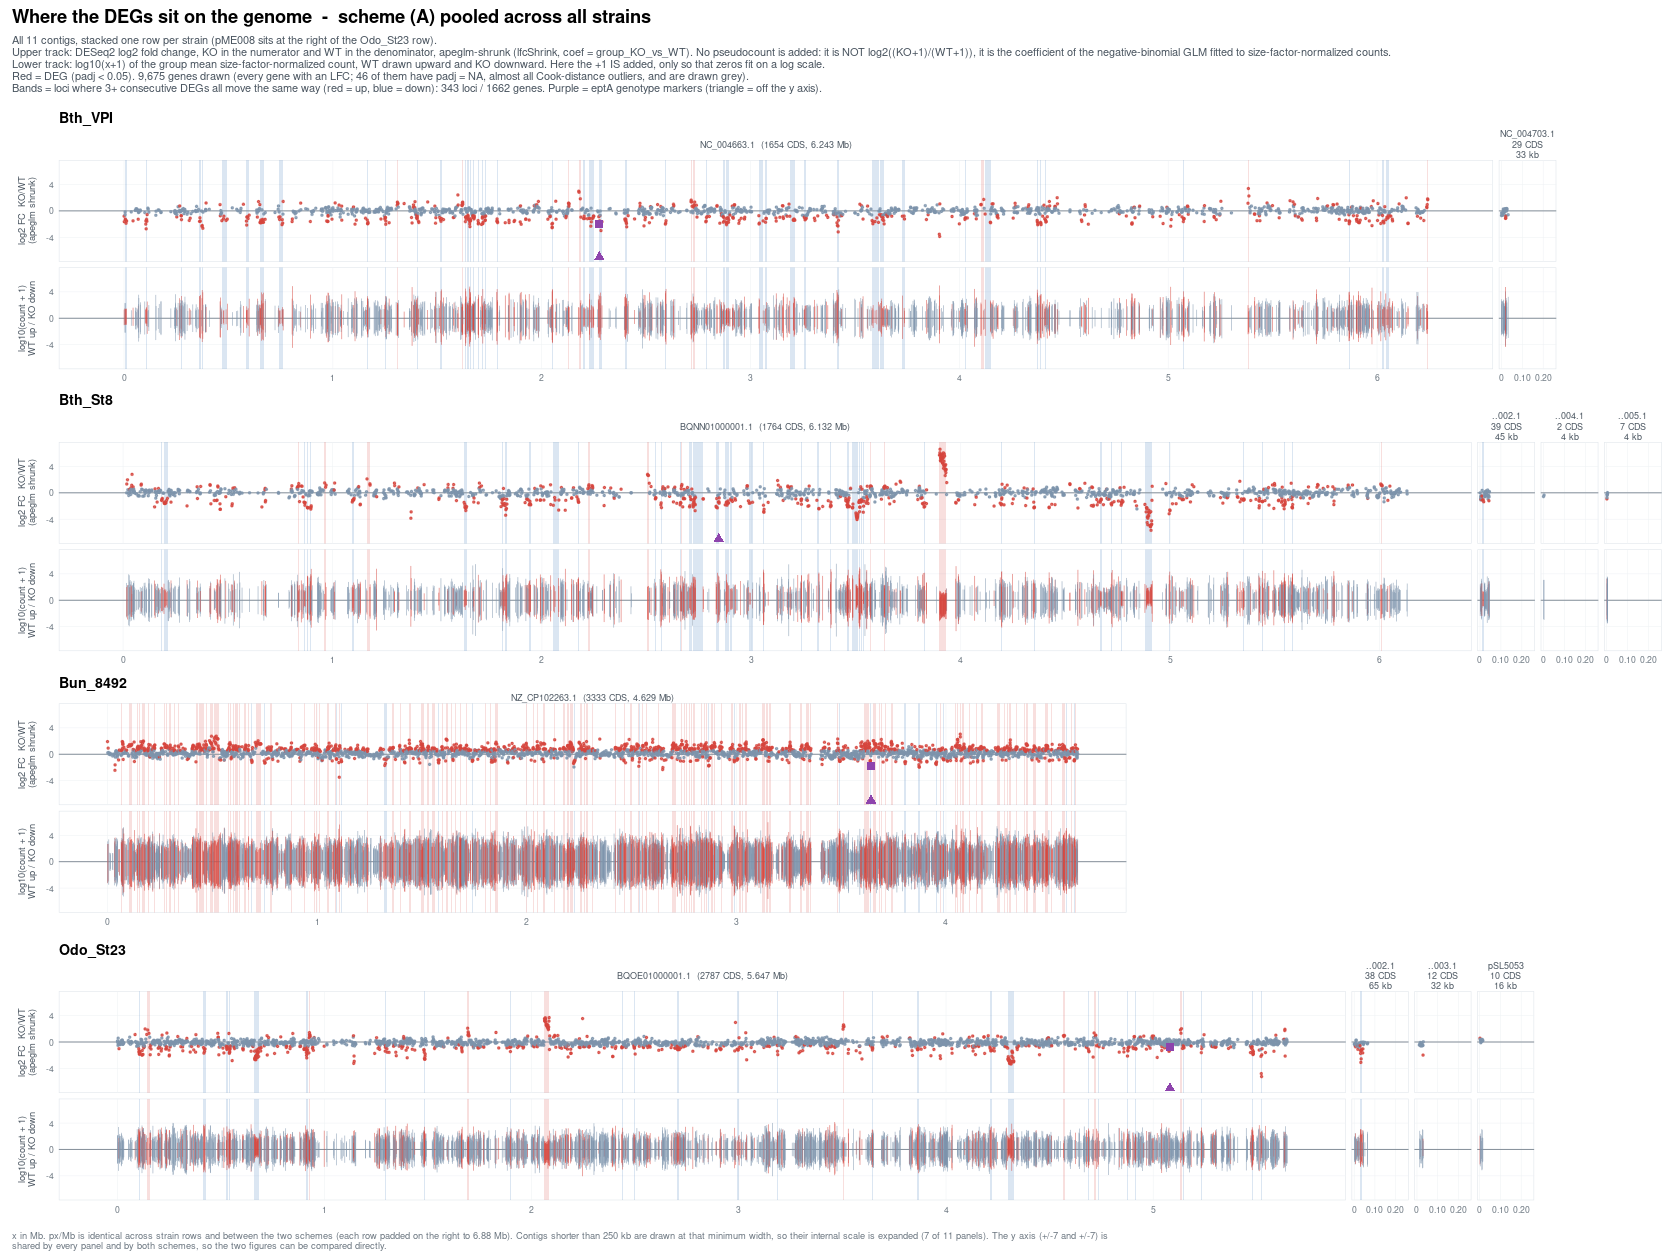

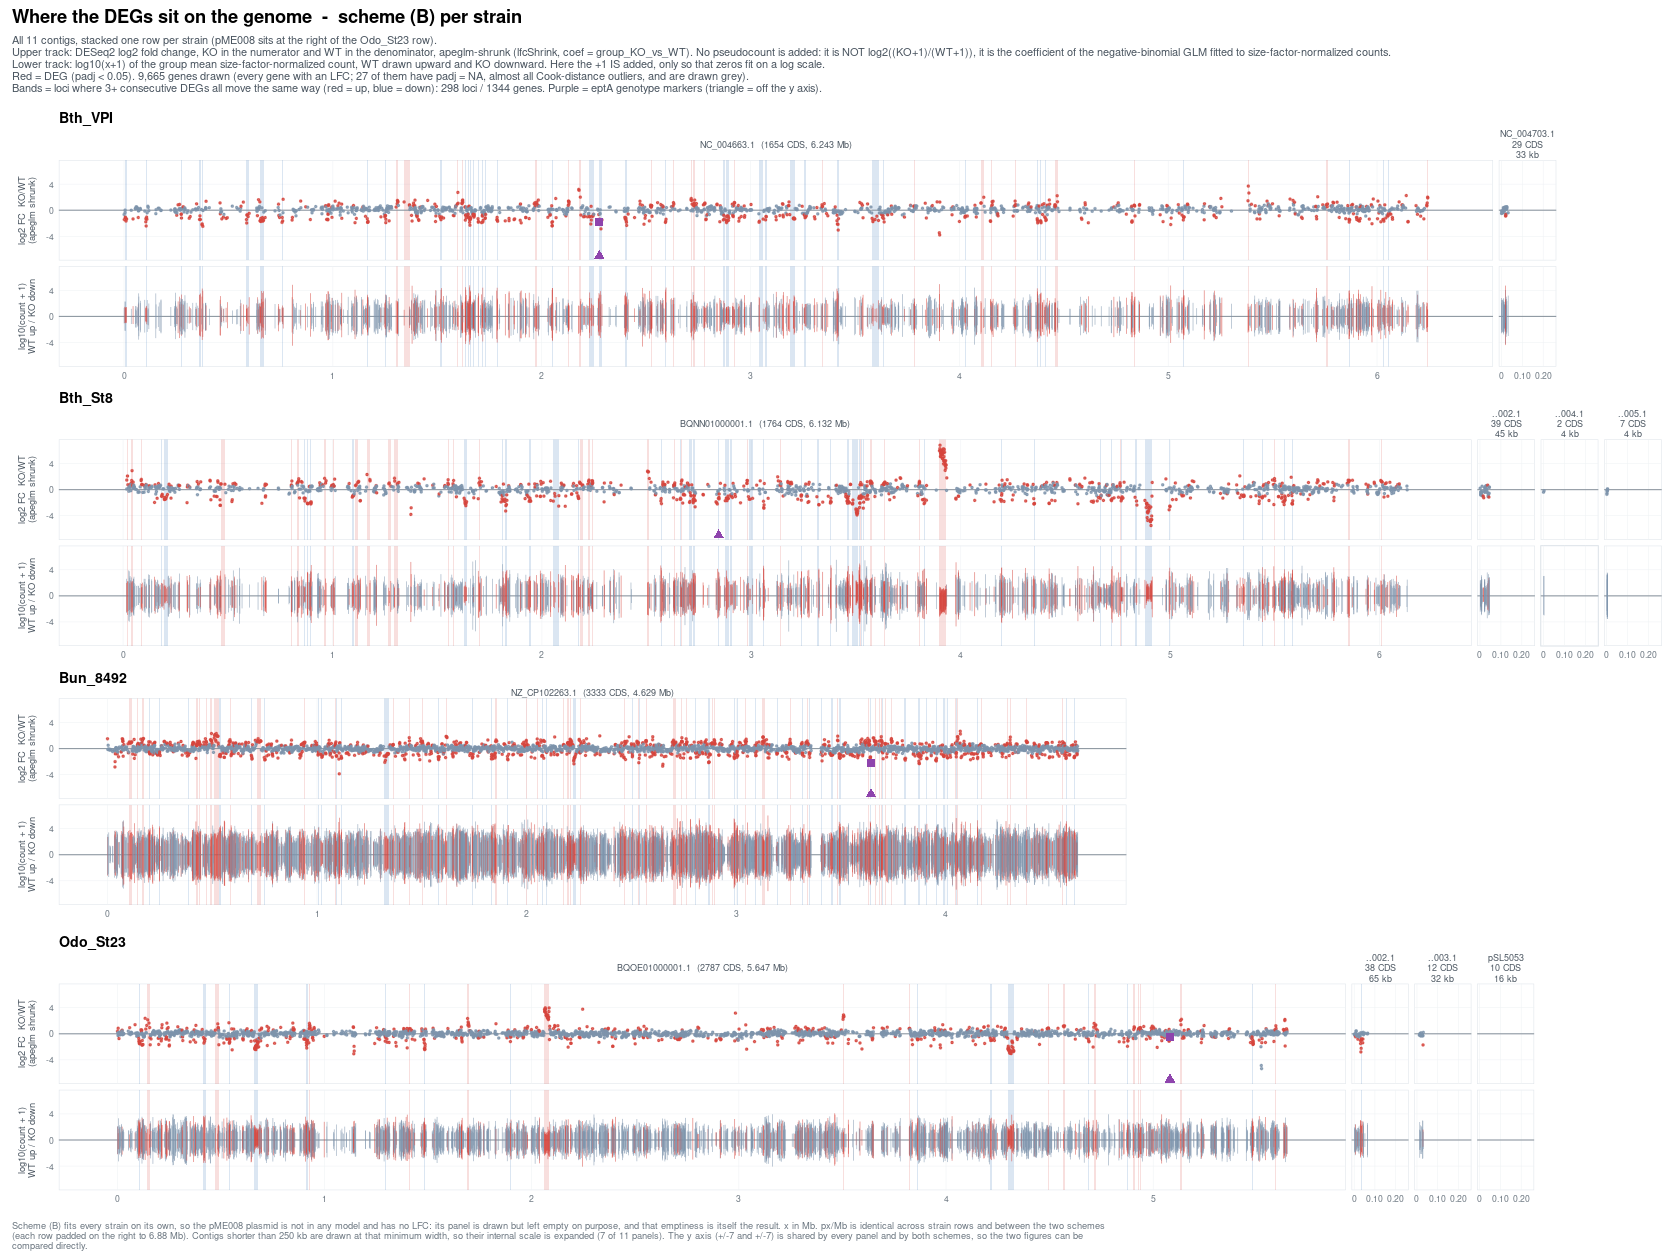

In [185]:
# ══════════════════════════════════════════════════════════════════
# セル3: notebook 内で読むための静的版（図1）— scheme (A) と (B) を並べる
# ══════════════════════════════════════════════════════════════════
# セル1 の HTML はブラウザで開く前提なので、notebook を読むだけの人には届かない。
# ステージ6 セル15-2 と同じ考え方で、同じ内容を PNG で持つ。
#
# 構成（ユーザー指定）
#   ・全 11 contig を描く。間引かない
#   ・株ごとに縦積み。pME008 は Odo_St23 の段の最右（ブラウザと同じ配置）
#   ・帯の定義は「同方向のみ」
#   ・(A) と (B) を2枚出して対比する
#
# ★ 図の中は英語のみ
#   日本語を入れると PNG 保存時に mbcsToSbcs 変換が失敗して文字化けする（CLAUDE.md）。
#   HTML 版（セル1・2）はブラウザが描くので日本語が使えるが、PNG は使えない
#
# ★ y 軸の定義（下の TRK のコメントに詳しく書いた）
#   上段 = apeglm 収縮後の log2(KO/WT)。疑似カウント無し
#   下段 = log10(正規化カウント + 1)。こちらだけ +1 している
#
# ★ 2枚は直接重ねて比較できるようにしてある
#   y 軸（±7 / ±7）も、段ごとの px/Mb も、パネルの並びも (A)(B) で共通。
#   違うのは点の位置・色・帯だけ
#
# ★ このセルは単体で実行できる（KEGG module は図に使わないので読み込まない）

# ── (1) ライブラリ ────────────────────────────────────────────────
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
library(dplyr)
library(tidyr)
library(ggplot2)
suppressMessages(library(patchwork))
cat(sprintf("ggplot2 %s / patchwork %s\n",
            packageVersion('ggplot2'), packageVersion('patchwork')))

# ── (2) パス ──────────────────────────────────────────────────────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_de      = file.path(path, 'DESeq2')
dir_gb       = file.path(path, 'genome')
if (!dir.exists(dir_gb)) dir.create(dir_gb, recursive = TRUE)
f_deA = file.path(path_de, 'A_de.csv')
f_deB = file.path(path_de, 'B_de.csv')

# ── (3) res を作る（セル1 と同じ）────────────────────────────────
# ── ステージ5 の結果を読む ─────────────────────────────────────
# (A) と (B) を1つの表にまとめる。ステージ6 はこの表だけで進む
deA = read.csv(f_deA, stringsAsFactors = FALSE)
deB = read.csv(f_deB, stringsAsFactors = FALSE)

# B_de.csv には既に LFC_A / padj_A / stat_A / AvsB が入っている（5_2 セル11）。
# (A) にしか無い pME008 の10遺伝子を足して、全 9,795 遺伝子の表にする
res = deA %>%
    dplyr::select(gene_id, strain, product, marker, biotype, mappability,
                  contig, strand, start, end,
                  Preferred_name, KEGG_ko, KEGG_Pathway, COG_category,
                  PFAMs, EC, CAZy, Description,
                  baseMean, LFC_A = LFC_shrunk, padj_A = padj, stat_A = stat_Wald,
                  normA_WT = norm_WT_mean, normA_KO = norm_KO_mean,
                  normA_diff = norm_diff) %>%
    left_join(deB %>% dplyr::select(gene_id, LFC_B, padj_pooled, padj_bystrain,
                                    stat_B, normB_WT = normB_WT_mean,
                                    normB_KO = normB_KO_mean, normB_diff, AvsB),
              by = 'gene_id') %>%
    mutate(sigA = !is.na(padj_A)      & padj_A      < 0.05,
           sigB = !is.na(padj_pooled) & padj_pooled < 0.05)
# ── (4) 対象遺伝子と連続 DEG 座位 ────────────────────────────────
# ★ セル1 の g と同じ行集合だが、この図では KEGG module を使わないので
#   アノテーションの結合は省いている（行数は一致する）
strains4  = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')
panel_ord = c(strains4, 'pME008')
g = res %>% filter(!marker, biotype == 'CDS', !is.na(padj_A) | !is.na(padj_pooled)) %>%
    mutate(mid  = (start + end)/2,
           degA = as.integer(!is.na(padj_A)      & padj_A      < 0.05),
           degB = as.integer(!is.na(padj_pooled) & padj_pooled < 0.05)) %>%
    arrange(strain, contig, mid)

# 同方向の連続 DEG 座位（セル1 の runsAd / runsBd と同じ定義）
# key は 0（非 DEG）/ +1（上昇 DEG）/ -1（低下 DEG）の3値。符号が変わると区間が切れる
mkruns = function(sc) {
  g %>% group_by(strain, contig) %>%
    mutate(deg = if (sc=='A') degA else degB,
           lf  = if (sc=='A') LFC_A else LFC_B,
           key = deg * sign(ifelse(is.na(lf), 0, lf)),
           grp = cumsum(key != lag(key, default = 0L))) %>%
    filter(deg == 1) %>% group_by(strain, contig, grp) %>%
    summarise(n = dplyr::n(), x0 = min(start), x1 = max(end),
              dir = ifelse(first(sign(lf)) > 0, 'up', 'dn'), .groups = 'drop') %>%
    filter(n >= 3)
}
runsAd = mkruns('A'); runsBd = mkruns('B')
cat(sprintf("■ 対象 %d 遺伝子 / 同方向の連続 DEG 座位: (A) %d 区間 %d 遺伝子 / (B) %d 区間 %d 遺伝子\n",
            nrow(g), nrow(runsAd), sum(runsAd$n), nrow(runsBd), sum(runsBd$n)))

# ── (5) 図を組み立てる ───────────────────────────────────────────
LIM  = ceiling(max(abs(c(g$LFC_A, g$LFC_B)), na.rm=TRUE))
CMAX = ceiling(max(log10(c(g$normA_WT,g$normA_KO,g$normB_WT,g$normB_KO)+1), na.rm=TRUE))
MINBP = 250000   # ★ 150kb だとラベルが入りきらず "(29 CD" のように切れた（実測）
# ★ 軸の中身を省略せずに書く（ユーザー指示 2026-11-05）
#   上段 = DESeq2 の log2 fold change。5_1 / 5_2 で
#          lfcShrink(dds, coef = 'group_KO_vs_WT', type = 'apeglm') をかけた値。
#          分子が KO、分母が WT。
#     ★ 疑似カウントは足していない。log2((KO+1)/(WT+1)) ではない。
#       size factor で正規化したカウントに当てた負の二項 GLM の係数（の apeglm 事後モード）
#       そのものなので、群平均の比を手で計算した値とは一致しない
#   下段 = log10(群平均の正規化カウント + 1)。こちらは +1 している。
#          0 を log 軸に乗せるためだけで、上向きが WT、下向きが KO
# ★ ラベルはパネルの高さに収まる長さでないと端から欠ける。
#   'log10(norm count + 1)' は長すぎて 'og10(...' と頭が切れた（実測）。
#   正規化の中身は副題に書いてあるので、ここは分子分母と +1 の有無だけ示す
TRK = c('log2 FC  KO/WT\n(apeglm shrunk)', 'log10(count + 1)\nWT up / KO down')

ctg2 = g %>% group_by(strain, contig) %>%
  summarise(n = dplyr::n(), len = max(end), .groups='drop') %>%
  mutate(w = pmax(len, MINBP),
         # ★ pME008 は 15.7 kb しかないので単独の段にすると段の 99.8% が空白になる。
         #   ブラウザと同じく Odo_St23 の右隣に置く
         row = ifelse(strain == 'pME008', 'Odo_St23', strain)) %>%
  arrange(match(row, strains4), strain == 'pME008', desc(len))
row_ord = strains4
maxtw = max((ctg2 %>% group_by(row) %>% summarise(tw=sum(w)))$tw)

# ── 描くデータ。scheme を引数にして (A)(B) で同じ関数を使う ──────
mkdat = function(sc) {
  d0 = g %>% mutate(lfc = if (sc=='A') LFC_A else LFC_B,
                    dg  = if (sc=='A') degA  else degB,
                    w_  = if (sc=='A') normA_WT else normB_WT,
                    o_  = if (sc=='A') normA_KO else normB_KO) %>%
       # ★ LFC が NA の遺伝子は描けない。実測では
#         (A) 0 遺伝子、(B) 10 遺伝子（pME008 の CDS 全部）。
#         (B) は株ごとに独立に DESeq2 を回すのでプラスミドはモデルに入らず、
#         B_de.csv に行自体が無い。0 除算が起きたわけではない
       filter(!is.na(lfc)) %>%
       transmute(strain, contig, x = mid/1e6, lfc, deg = dg == 1,
                 wt = log10(w_ + 1), ko = log10(o_ + 1))
  rn = if (sc=='A') runsAd else runsBd
  ep = res %>% filter(marker) %>%
       mutate(lf = if (sc=='A') LFC_A else LFC_B) %>% filter(!is.na(lf)) %>%
       transmute(strain, contig, x = (start+end)/2/1e6,
                 oor = abs(lf) > LIM, y = ifelse(abs(lf) > LIM, -LIM, lf), track = TRK[1])
  list(
    dup = d0 %>% transmute(strain, contig, x, y = lfc, deg, track = TRK[1]),
    dlo = bind_rows(d0 %>% transmute(strain, contig, x, y = wt,  deg, track = TRK[2]),
                    d0 %>% transmute(strain, contig, x, y = -ko, deg, track = TRK[2])),
    band = bind_rows(lapply(TRK, function(t)
             rn %>% transmute(strain, contig, x0 = x0/1e6, x1 = x1/1e6, dir, track = t))),
    em = ep, nrun = nrow(rn), ngene = sum(rn$n), ndrawn = nrow(d0),
    # ★ LFC はあるが padj が NA の遺伝子（Cook 距離の外れ値など）。
    #   LFC があるので描くが DEG ではないので灰色になる。本数を副題に出す
    nna = sum(is.na(if (sc=='A') g$padj_A else g$padj_pooled)[!is.na(if (sc=='A') g$LFC_A else g$LFC_B)]))
}

col_deg = c(`TRUE` = '#d6453c', `FALSE` = '#7d93ab')
mkrow = function(s, D) {
  cs = ctg2 %>% filter(row == s)
  nm = function(v) sub('^.*~', '', v)
  lv  = nm(cs$contig)
  # ★ 狭いパネルは名前が入りきらないので詰める（実測で "(29 CD" のように切れた）
  # ★ 狭いパネルは名前が入りきらないので3行に分けて詰める
  #   （1行だと "29 CDS / 33 kb" が左右で切れて "9 CDS / 33 kl" になった。実測）
  lab = setNames(ifelse(cs$len < MINBP,
                        sprintf('%s\n%d CDS\n%.0f kb', sub('^.*?0{3,}', '..', nm(cs$contig)),
                                cs$n, cs$len/1000),
                        sprintf('%s  (%d CDS, %.3f Mb)', nm(cs$contig), cs$n, cs$len/1e6)),
                 nm(cs$contig))
  fc = function(df) df %>% mutate(ctg = factor(nm(contig), levels = lv),
                                  track = factor(track, levels = TRK))
  # 各パネルの x 範囲を表示幅 w に固定する（+ 余白パネル）
  rng = bind_rows(lapply(TRK, function(t) cs %>% transmute(ctg = nm(contig), track = t, x = w/1e6)))
  rng = bind_rows(rng %>% mutate(x = 0), rng) %>%
        mutate(ctg = factor(ctg, levels = lv), track = factor(track, levels = TRK))
  ylim = bind_rows(
    data.frame(ctg = lv[1], track = TRK[1], y = c(-LIM, LIM)),
    data.frame(ctg = lv[1], track = TRK[2], y = c(-CMAX, CMAX))) %>%
    mutate(ctg = factor(ctg, levels = lv), track = factor(track, levels = TRK))

  ggplot() +
    geom_blank(data = rng,  aes(x = x)) +
    geom_blank(data = ylim, aes(x = 0, y = y)) +
    geom_rect(data = fc(D$band %>% left_join(ctg2 %>% dplyr::select(strain, contig, row), by = c('strain','contig')) %>% filter(row == s)),
              aes(xmin = x0, xmax = x1, ymin = -Inf, ymax = Inf, fill = dir),
              alpha = .17, inherit.aes = FALSE) +
    scale_fill_manual(values = c(up = '#d6453c', dn = '#2f6fb3'), guide = 'none') +
    geom_hline(yintercept = 0, linewidth = .3, colour = '#8a949e') +
    geom_segment(data = fc(D$dlo %>% left_join(ctg2 %>% dplyr::select(strain, contig, row), by = c('strain','contig')) %>% filter(row == s)),
                 aes(x = x, xend = x, y = 0, yend = y, colour = deg),
                 linewidth = .18, alpha = .75) +
    geom_point(data = fc(D$dup %>% left_join(ctg2 %>% dplyr::select(strain, contig, row), by = c('strain','contig')) %>% filter(row == s)),
               aes(x = x, y = y, colour = deg), size = .32, alpha = .75) +
    scale_colour_manual(values = col_deg, guide = 'none') +
    geom_point(data = fc(D$em %>% left_join(ctg2 %>% dplyr::select(strain, contig, row), by = c('strain','contig')) %>% filter(row == s)),
               aes(x = x, y = y, shape = oor), colour = '#8e44ad', size = 1.9) +
    scale_shape_manual(values = c(`TRUE` = 17, `FALSE` = 15), guide = 'none') +
    facet_grid(track ~ ctg, scales = 'free', space = 'free_x', switch = 'y',
               labeller = labeller(ctg = lab)) +
    scale_x_continuous(breaks = function(l) {
        # ★ 狭いパネル（表示幅 0.3 Mb 未満）は目盛り2本。実測で数字が重なって潰れた
        if (diff(l) < 0.3) scales::breaks_pretty(2)(l) else scales::breaks_pretty(5)(l) },
        labels = function(b) ifelse(b < 1 & b > 0, sprintf('%.2f', b), sprintf('%g', b))) +
    labs(x = NULL, y = NULL, title = s) +
    theme_minimal(base_size = 7) +
    theme(panel.grid.minor = element_blank(),
          panel.grid.major.x = element_line(linewidth = .15, colour = '#eef1f4'),
          panel.grid.major.y = element_line(linewidth = .15, colour = '#eef1f4'),
          panel.background = element_rect(fill = NA, colour = '#dde3e9', linewidth = .3),
          strip.text.x = element_text(size = 5.4, lineheight = .95, colour = '#4a5560', margin = margin(1,1,1,1)),
          strip.text.y.left = element_text(size = 5.6, angle = 90, colour = '#4a5560'),
          strip.placement = 'outside',
          plot.title = element_text(size = 8.5, face = 'bold', margin = margin(b = 1)),
          axis.text = element_text(size = 5.2, colour = '#6b7680'),
          plot.margin = margin(2, 4, 2, 2))
}
# ★ 幅そろえは facet の余白パネルではなく patchwork の plot_spacer() で行う。
#   余白を facet にすると、そこにも x 目盛りが描かれて意味不明な数字が並ぶ（実測）
tw = ctg2 %>% group_by(row) %>% summarise(tw = sum(w), .groups='drop')
SCHLAB = c(A = '(A) pooled across all strains', B = '(B) per strain')

mkfig = function(sc) {
  D  = mkdat(sc)
  pl = lapply(row_ord, function(s) {
    p = mkrow(s, D); w = tw$tw[tw$row == s]; pad = maxtw - w
    if (pad > maxtw*0.01) p + plot_spacer() + plot_layout(widths = c(w, pad)) else p
  })
  wrap_plots(pl, ncol = 1) +
    # ★ caption は折り返されないので右端で切れる（実測）。手で折る
    plot_annotation(
      # ★ 図の中は ASCII だけにする。em-dash (U+2014) を入れたら PNG 保存時に
      #   mbcsToSbcs 警告が出て - に置換された（実測）
      title = sprintf('Where the DEGs sit on the genome  -  scheme %s', SCHLAB[sc]),
      subtitle = sprintf('All %d contigs, stacked one row per strain (pME008 sits at the right of the Odo_St23 row).\nUpper track: DESeq2 log2 fold change, KO in the numerator and WT in the denominator, apeglm-shrunk (lfcShrink, coef = group_KO_vs_WT). No pseudocount is added: it is NOT log2((KO+1)/(WT+1)), it is the coefficient of the negative-binomial GLM fitted to size-factor-normalized counts.\nLower track: log10(x+1) of the group mean size-factor-normalized count, WT drawn upward and KO downward. Here the +1 IS added, only so that zeros fit on a log scale.\nRed = DEG (padj < 0.05). %s genes drawn (every gene with an LFC; %d of them have padj = NA, almost all Cook-distance outliers, and are drawn grey).\nBands = loci where 3+ consecutive DEGs all move the same way (red = up, blue = down): %d loci / %d genes. Purple = eptA genotype markers (triangle = off the y axis).',
                          nrow(ctg2), format(D$ndrawn, big.mark=','), D$nna, D$nrun, D$ngene),
      caption = paste(strwrap(sprintf(paste0(if (sc == 'B') 'Scheme (B) fits every strain on its own, so the pME008 plasmid is not in any model and has no LFC: its panel is drawn but left empty on purpose, and that emptiness is itself the result. ' else '',
                               'x in Mb. px/Mb is identical across strain rows and between the two schemes (each row padded on the right to %.2f Mb). Contigs shorter than %d kb are drawn at that minimum width, so their internal scale is expanded (%d of %d panels). The y axis (+/-%d and +/-%d) is shared by every panel and by both schemes, ',
                               'so the two figures can be compared directly.'),
                        maxtw/1e6, MINBP/1000, sum(ctg2$len < MINBP), nrow(ctg2), LIM, CMAX),
                      width = 265), collapse = '\n'),
      theme = theme(plot.title = element_text(size = 11, face = 'bold'),
                    plot.subtitle = element_text(size = 6.6, colour = '#4a5560'),
                    plot.caption = element_text(size = 5.6, colour = '#6b7680', hjust = 0)))
}
figs = list()
for (sc in c('A','B')) {
    p = mkfig(sc); figs[[sc]] = p
    f = file.path(dir_gb, sprintf('genome_static_%s.png', sc))
    ggsave(f, p, width = 14, height = 10.5, dpi = 200, bg = 'white')
    ok = file.copy(f, file.path(path_project, basename(f)), overwrite = TRUE)
    D = mkdat(sc)
    cat(sprintf("■ %s（%.0f KB）→ project 複製 %s / 描いた遺伝子 %s / 帯 %d 区間 %d 遺伝子\n",
        basename(f), file.size(f)/1024, ifelse(ok,'OK','!! 失敗'),
        format(D$ndrawn, big.mark=','), D$nrun, D$ngene))
}

# ── (6) notebook の出力としても表示する ──────────────────────────
# ★ セル1・2 の HTML は「ブラウザで開くこと」にしたが、この PNG は notebook 内で読む用
options(repr.plot.width = 14, repr.plot.height = 10.5)
print(figs[['A']])
print(figs[['B']])


## セル3-2: 図1 をベクタ（PDF）でも保存する

PNG は notebook に貼るためのもの。**図として後から手を入れるにはベクタが要る。**
`260914_KAD_metaFL16S` と同じく project 直下の `pdf/` に置く。

★ **`device = 'pdf'` ではなく `cairo_pdf`。** 前者だと Helvetica が**埋め込まれない**（実測 `pdffonts` → `emb = no`）。
`cairo_pdf` なら NimbusSans のサブセットが埋め込まれ、ファイルも小さい（0.66 → 0.55 MB）。

★ **セル3 を先に実行しておくこと**（`figs[['A']]` / `figs[['B']]` をそのまま書き出す）。

In [32]:
# ══════════════════════════════════════════════════════════════════
# セル3-2: 図1 をベクタ（PDF）でも保存する
# ══════════════════════════════════════════════════════════════════
# PNG は notebook に貼るためのもの。図として後から手を入れるにはベクタが要る。
# 260914_KAD_metaFL16S と同じく project 直下の pdf/ に ggsave で置く。
#
# ★ セル3 を先に実行しておくこと
#   セル3 が作った figs[['A']] / figs[['B']] をそのまま書き出す。
#   ここで図を作り直すと二重管理になり、片方だけ直したときに食い違う
#
# ★ device は 'pdf' ではなく cairo_pdf を使う
#   260914_KAD は device='pdf' だが、それだと Helvetica が「埋め込まれない」。
#   実測: pdffonts → Helvetica / Helvetica-Bold ともに emb=no。
#   base-14 フォントなので画面では出るが、投稿時に弾かれることがある。
#   cairo_pdf なら NimbusSans のサブセットが埋め込まれ、ファイルも小さい
#   （実測 0.66 MB → 0.55 MB）。文字は文字のまま残る（アウトライン化しない）
#
# ★ PDF もフォントは ASCII のみ
#   セル3 の時点で図中を全部 ASCII にしてあるので、そのまま通る

if (!exists('figs') || !all(c('A','B') %in% names(figs)))
    stop('figs が無い。先にセル3 を実行すること')

# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
pdf_dir  = file.path(path, 'pdf')
pdf_proj = file.path(path_project, 'pdf')
dir.create(pdf_dir,  recursive = TRUE, showWarnings = FALSE)
dir.create(pdf_proj, recursive = TRUE, showWarnings = FALSE)

# ★ 警告を握り潰さずに拾う。フォント関係の警告が出たら図中に非 ASCII が混ざっている
res_pdf = list()
for (sc in c('A','B')) {
    f = file.path(pdf_dir, sprintf('genome_map_%s.pdf', sc))
    w = character(0)
    withCallingHandlers(
        ggsave(f, figs[[sc]], width = 14, height = 10.5, device = grDevices::cairo_pdf),
        warning = function(e) { w <<- c(w, conditionMessage(e)); invokeRestart('muffleWarning') })
    # 検品: ページサイズとフォント埋め込み（poppler が入っていれば読む）
    info = tryCatch(system2('pdfinfo',  f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    font = tryCatch(system2('pdffonts', f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    sz   = sub('^Page size: *', '', grep('^Page size', info, value = TRUE))
    fn   = font[-(1:2)]
    res_pdf[[sc]] = data.frame(
        scheme    = sc,
        file      = basename(f),
        MB        = round(file.size(f)/1024^2, 2),
        ページ    = ifelse(length(sz) == 0, '?', sz[1]),
        フォント  = ifelse(length(fn) == 0, '?',
                           paste(sub(' .*', '', trimws(fn)), collapse = ', ')),
        # ★ pdffonts の emb 列は「末尾から5番目のトークン」。
        #   桁位置で substr すると type 欄が 'CID Type 0C' のように伸びてずれる（実測）
        埋め込み  = ifelse(length(fn) == 0, '?',
                           ifelse(all(vapply(strsplit(trimws(fn), ' +'),
                                             function(v) v[length(v)-4], character(1)) == 'yes'),
                                  '全部 yes', '!! no がある')),
        警告      = ifelse(length(w) == 0, 'なし', paste(w, collapse = ' / ')))
    ok = file.copy(f, file.path(pdf_proj, basename(f)), overwrite = TRUE)
    cat(sprintf("■ %s（%.2f MB / %s）→ project 複製 %s / フォント埋め込み %s / 警告 %s\n",
        basename(f), file.size(f)/1024^2, res_pdf[[sc]]$ページ, ifelse(ok,'OK','!! 失敗'),
        res_pdf[[sc]]$埋め込み, res_pdf[[sc]]$警告))
}

# ── 図1 のファイル対応 ──────────────────────────────────────────
f_all = c(file.path(path_project, c('genome_static_A.png','genome_static_B.png')),
          file.path(pdf_dir,      c('genome_map_A.pdf','genome_map_B.pdf')))
data.frame(scheme = c('A','B','A','B'),
           形式   = rep(c('PNG（notebook 内で読む用・200 dpi）',
                          'PDF（ベクタ・図として触る用）'), each = 2),
           file   = sub('^.*/', '', f_all),
           場所   = sub('/[^/]*$', '', f_all),
           MB     = round(file.size(f_all)/1024^2, 2)) %>% as.data.frame()

■ genome_map_A.pdf（0.55 MB / 1008 x 756 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 なし
■ genome_map_B.pdf（0.55 MB / 1008 x 756 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 なし


scheme,形式,file,場所,MB
<chr>,<chr>,<chr>,<chr>,<dbl>
A,PNG（notebook 内で読む用・200 dpi）,genome_static_A.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.83
B,PNG（notebook 内で読む用・200 dpi）,genome_static_B.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.82
A,PDF（ベクタ・図として触る用）,genome_map_A.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.55
B,PDF（ベクタ・図として触る用）,genome_map_B.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.55


## セル3-3: 議論で付けた領域をゲノムマップに重ねる（図1-2）

セル3 の図1 は「DEG がどこにあるか」まで。そこに**「その領域が何なのか」**を重ねる。出どころの違う2系統を1枚に載せる。

|-| 中身 | 入力 |
|---|---|---|
| **(AI)** | claude.ai と `product` 名を読んで**手で付けた**領域 | `genome_annotations.tsv`（手で保守） |
| **(CC)** | ステージ4〜6 の議論に出た単位を、**本データから検出した**オペロン | このセルが `genome_annotations_stage456.tsv` に書き出す |

★ **セル3 を先に実行**（`mkrow` / `mkdat` / `ctg2` / `res` などをそのまま使い、作図コード本体には手を入れない）。

★ **オペロン（2遺伝子以上が隣り合う塊）だけ**を描く。単独遺伝子（銅排出・BSH・SOD など）と PUL / OmpA は別の図に回す。

★ 重なったら **CC 側の座標**を採る。

★ 確からしさはラベル先頭の **`***` / `**` / `*`**（線種は細い枠だと判別できないため不採用）。基準は図の副題に書いてある。

★ 本数は **「当たった数 of 枠の中の CDS 数」**。区間は当たった遺伝子の min〜max なので、間に挟まる遺伝子も枠に入る。

出力: `annmap_merged_aiTSV_stage456operon_{A,B}.png`

ggrepel 0.9.6
  うち 間に無関係な遺伝子が挟まる 13 / 鎖が混在 4 / 遺伝子間 200bp 超を含む 9
■ CC 側を検出: 36 領域 / 168 遺伝子 / テーマ 11 → genome_annotations_stage456.csv（project 複製 OK）
■ AI 側 28 領域のうち 11 が CC 側と重なる → AI 側を落とす
■ 合計 53 領域（AI 17 / CC 36）
■ eptA マーカー 7 個 → ラベル 4 個にまとめた
■ annmap_merged_aiTSV_stage456operon_A.png（1013 KB）→ project 複製 OK / 警告 なし
■ annmap_merged_aiTSV_stage456operon_B.png（1007 KB）→ project 複製 OK / 警告 なし

■ 描いた領域の一覧


株,kb,出どころ,向き,ラベル
<chr>,<chr>,<chr>,<chr>,<chr>
Bth_VPI,104.0-110.8,AI,down,*** (AI) Arsenite efflux
Bth_VPI,1517.5-1521.5,CC,down,*** (CC) PPP oxidative branch [pgl/gnd] 2 CDS
Bth_VPI,2049.4-2051.2,CC,down,*** (CC) PPP non-oxidative branch [tal/fbaB] 2 CDS
Bth_VPI,2591.7-2596.5,CC,down,*** (CC) TCA oxidative direction [prpC/icd/acnA] 3 CDS
Bth_VPI,2883.9-2895.5,AI,down,** (AI) Mfa1 fimbriae + mobile element
Bth_VPI,3413.8-3421.2,AI,down,*** (AI) Porin + aspartate catabolism
Bth_VPI,3582.0-3639.9,AI,down,** (AI) Capsular polysaccharide (CPS)
Bth_VPI,373.2-377.3,AI,down,*** (AI) Pyruvate dehydrogenase complex + flavodoxin
Bth_VPI,4388.5-4391.8,CC,down,*** (CC) Fe-S cluster assembly [sufC/sufD/sufS] 3 CDS


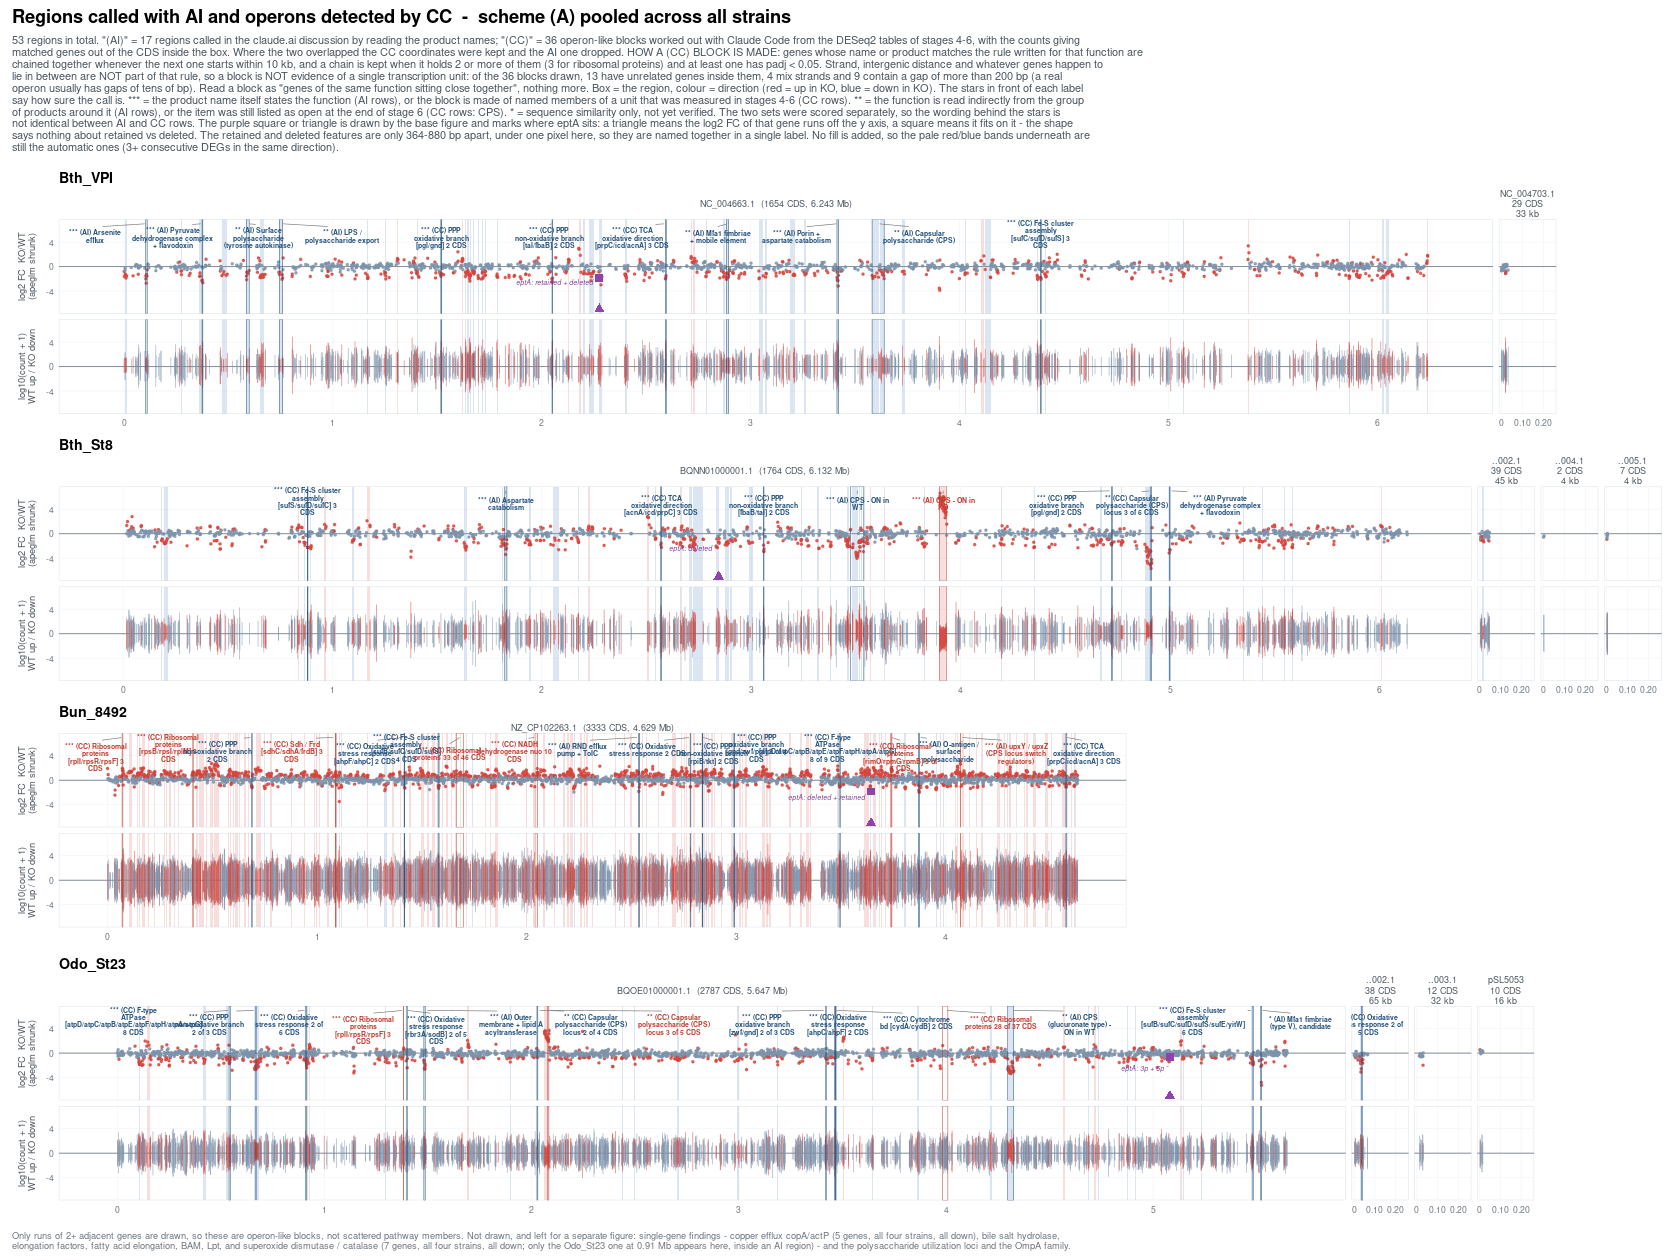

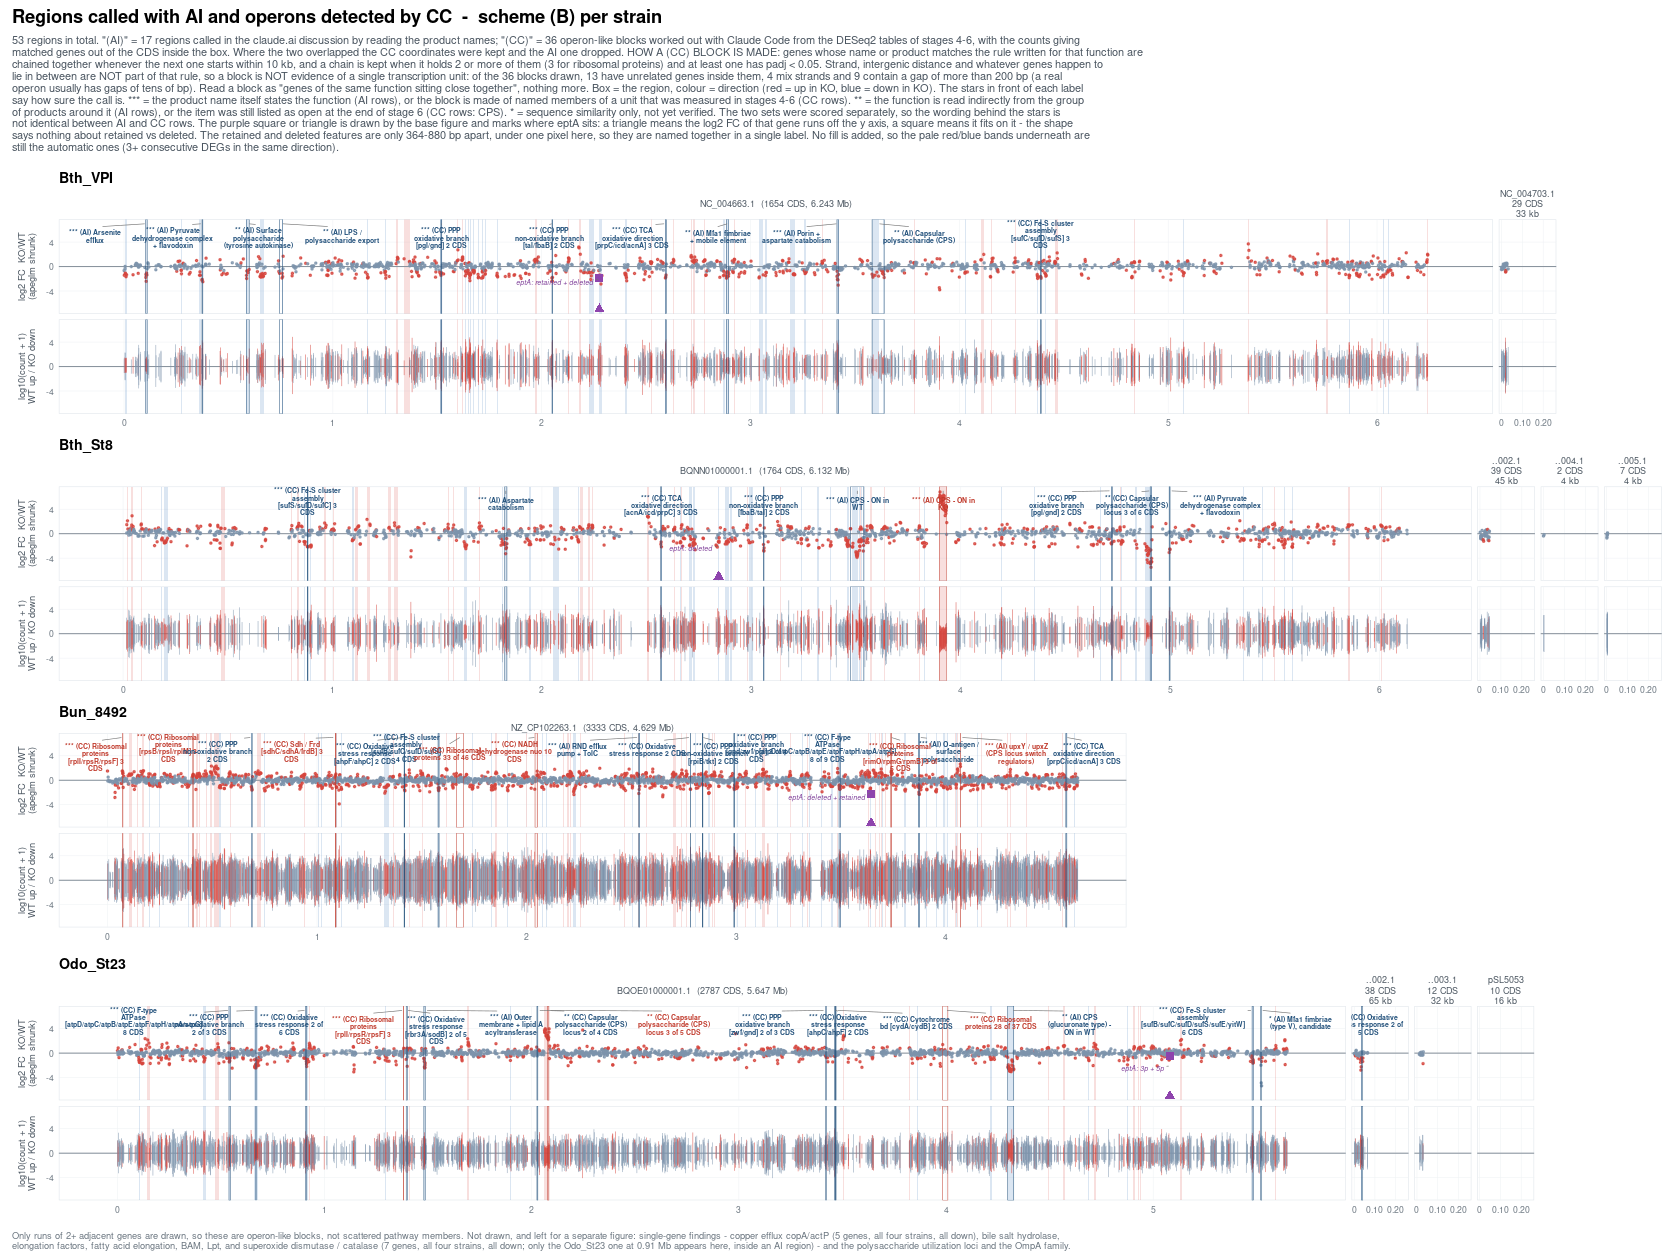

In [33]:
# ══════════════════════════════════════════════════════════════════
# セル3-3: 議論で付けた領域をゲノムマップに重ねる（図1-2）
# ══════════════════════════════════════════════════════════════════
# セル3 の図1 は「DEG がどこにあるか」までしか言わない。そこに
# 「その領域が何なのか」を重ねる。出どころの違う2系統を1枚に載せる。
#
#   (AI) claude.ai と product 名を読んで手で付けた領域
#        → genome_annotations.tsv（project 直下。手で保守するファイル）
#   (CC) ステージ4〜6 の議論に出た単位を、このプロジェクトのデータから
#        Claude Code で検出したオペロン
#        → このセルが genome_annotations_stage456.tsv に書き出す
#
# ★ セル3 を先に実行しておくこと
#   セル3 が作った mkrow / mkdat / ctg2 / TRK / LIM / tw / maxtw / row_ord /
#   SCHLAB / res をそのまま使う。作図コード本体には一切手を入れず、
#   できた段の plot に層を足すだけにする（二重管理を避ける）
#
# ★ 描くのは「オペロンになっているもの」だけ（ユーザー指示）
#   代謝経路の遺伝子はゲノム上に散在する（ステージ6 セル13 考察）。
#   2遺伝子以上が隣り合う塊だけを帯にする。単独遺伝子は別の図に回す。
#   落ちるもの: 銅排出 copA/actP(5)・BSH(3)・SOD/カタラーゼ(7 のうち6)・
#   翻訳伸長因子(8)・脂肪酸伸長(8)・Lpt(6)・BAM(5)・酸化ストレスの大半
#
# ★ PUL と 外膜OmpA は外してある（ユーザー指示）
#   PUL 194区間/293遺伝子、OmpA は PFAM で 95 遺伝子あり、この図には多すぎる。
#   次の図として別に作る
#
# ★ 重なったら CC 側の座標を採る（ユーザー指示）
#   実測で 9 組が重なる。うち CPS 2件だけは AI 側のほうが広く座位全体を
#   囲っている（St8 33.6kb→6.7kb / Odo 25.7kb→6.9kb に縮む）
#
# ★ 塗りは入れない。枠線だけにする
#   セル3 が DEG 帯を赤/青 alpha .17 で塗っている。そこへ塗りを重ねると
#   二重に濃くなり「自動検出した帯」と「議論で付けた領域」の区別が消える
#
# ★ 色は aes に載せない
#   セル3 が colour スケールを DEG の赤/灰に、shape を eptA の三角/四角に
#   使っている。1つの図に同じスケールは1本しか置けないので、
#   枠の色は colour = <値のベクタ> として直接渡す
#
# ★ 確からしさは線種ではなくラベル先頭の星で出す
#   枠を細く（linewidth .14）すると実線/破線/点線が判別できない（実測）。
#   凡例のキーも geom_rect の既定だと塗りつぶし多角形なので fill=NA では
#   何も描かれず、さらに drop=FALSE でもその段にデータが無い水準は
#   キーが空白になる。星にすれば全部解消する
#
# ★ CC 側のラベルは theme 名ではなく実際の構成遺伝子を出す
#   theme 名の括弧は正規表現に書いた代表例で、その塊にあるとは限らない。
#   実測で Odo 3.46 Mb の塊は ahpC/ahpF なのに
#   'Oxidative stress response (sodB/katA/msr/trx)' と出ていた
#
# ★ 本数は「当たった数 of 枠の中の CDS 数」
#   区間は当たった遺伝子の min〜max なので、間に挟まる遺伝子も枠に入る。
#   実測で Bun のリボソーム超オペロンは 30 当たりに対し枠の中は 46 CDS
#
# ★ 図の中は ASCII のみ（CLAUDE.md）。
#   R の文字列は ' で囲っているので、英文に ' を入れると文字列が閉じる。
#   実測で "that gene's log2 FC" でパースエラーになった

# ── (1) 前提チェック ──────────────────────────────────────────────
need = c('mkrow','mkdat','ctg2','TRK','LIM','tw','maxtw','row_ord','SCHLAB','res')
if (!all(vapply(need, exists, logical(1))))
    stop('セル3 を先に実行すること（足りない: ',
         paste(need[!vapply(need, exists, logical(1))], collapse=', '), '）')
library(ggrepel)
cat(sprintf("ggrepel %s\n", packageVersion('ggrepel')))

# ★ タブ区切りをやめて CSV にしてある。Excel は .tsv を「カンマ区切り」として
#   開くことがあり、label_en の 'Pentose phosphate pathway, oxidative branch' のように
#   カンマを含む値がそこで分すけてしまう（実測）。全列を引用符で囲めば安全
f_ai = file.path(path_project, 'genome_annotations.csv')
# ★ 書き出しは scratch へ。project にはあとで複製する（CLAUDE.md）
f_cc = file.path(dir_gb, 'genome_annotations_stage456.csv')
if (!file.exists(f_ai)) stop('genome_annotations.csv が無い: ', f_ai)
nmc  = function(v) sub('^.*~', '', v)

# ── (2) CC 側: ステージ4〜6 の議論に出た単位を本データから検出する ──
rr = res %>% filter(!marker, biotype == 'CDS') %>%
     transmute(gene_id, strain, contig = nmc(contig), start, end, strand,
               nm = Preferred_name, prod = product, PF = PFAMs,
               LFC_A, padj_A)

# theme / 日本語ラベル / 英語ラベル / 想定向き / 確からしさ / 出どころ / 最小遺伝子数 / 規則
# ★ 確からしさの基準
#   確定 = ステージ4〜6 で実測した単位の、名前の付いた構成遺伝子でできた塊
#   推定 = ステージ6 の時点で「未決」として残っていた項目
# ★ 規則は Preferred_name だけではなく product も見る（ユーザー指示）。
#   名前だけだと無名の重要な遺伝子が落ちる。実測で落ちていたのは
#   Odo の superoxide dismutase [Fe]（LFC -2.41 / padj 1.3e-17）、
#   Bth_St8 の manganese catalase、glutathione peroxidase、rubrerythrin ×5 など
IT = list(
 list('F型ATPase','F型ATPase（atpA-H）','F-type ATPase (atpA-H)','down','確定','S6 まとめ/セル11考察1',2,
      # ★ 'ATP synthase subunit' だけだと V型 ATPase を拾う。別の複合体で、
      #   実測では Bth 2株と Bun で「上昇」しており、F型の低下と混ざると結論が壊れる。
      #   さらに eggNOG は V型のα 鎖にも Preferred_name = atpA を付けるので
      #   名前でも分けられない。V-type を明示的に除く
      nm='^atp[A-H]$', pr='F0F1 ATP synthase', ex='V-type|V-ATPase|ntp'),
 list('PPP酸化相','PPP 酸化相','PPP oxidative branch','down','確定','S6 まとめ/セル7-2考察',2,
      nm='^(zwf|pgl|gnd)$', pr='glucose-6-phosphate dehydrogenase|6-phosphogluconolactonase|6-phosphogluconate dehydrogenase'),
 list('PPP非酸化相','PPP 非酸化相','PPP non-oxidative branch','down','確定','S6 セル12考察 ko00030',2,
      nm='^(tal|talA|talB|tkt|tktA|tktB|fba|fbaA|fbaB|rpe|rpiA|rpiB)$',
      pr='transaldolase|transketolase|fructose-bisphosphate aldolase|ribulose-phosphate 3-epimerase|ribose-5-phosphate isomerase'),
 list('TCA酸化方向','TCA 酸化方向','TCA oxidative direction','down','確定','S6 セル11考察2 ko00020',2,
      nm='^(prpC|acnA|acnB|icd|gltA)$',
      pr='citrate synthase|2-methylcitrate synthase|aconitate hydratase|isocitrate dehydrogenase'),
 list('酸化ストレス応答','酸化ストレス応答','Oxidative stress response','down','確定','S6 まとめ/セル7-2考察',2,
      nm='^(sodA|sodB|katA|katE|msrA|msrB|tpx|ahpC|ahpF|trxA|trxB|trxC|bcp|gor|grxC)$',
      pr='superoxide dismutase|catalase|thioredoxin|glutaredoxin|peroxiredoxin|alkyl hydroperoxide|methionine sulfoxide reductase|rubrerythrin|glutathione peroxidase|thiol peroxidase'),
 list('Fe-Sクラスター組立','Fe-S クラスター組立（suf）','Fe-S cluster assembly (suf)','down','確定','S6 まとめ/S7 テーマ',2,
      nm='^suf[A-E]$', pr='Fe-S cluster assembly|SUF system|cysteine desulfurase'),
 list('シトクロムbd','シトクロム bd（動いていない）','Cytochrome bd (NOT changed)','down','確定','S6 セル11考察1',2,
      nm='^cyd[AB]$', pr='cytochrome bd|cytochrome d ubiquinol oxidase'),
 list('リボソームタンパク','リボソームタンパク','Ribosomal proteins','up','確定','S6 まとめ ko03010',3,
      nm='^rp[ls][A-Z][0-9]?$', pr='ribosomal protein'),
 list('NADH脱水素酵素','NADH 脱水素酵素 nuo（Bun 限定）','NADH dehydrogenase nuo (Bun only)','up','確定','S6 セル11考察1',2,
      nm='^nuo[A-N]$', pr='NADH-quinone oxidoreductase subunit|NADH dehydrogenase subunit'),
 list('Sdh/Frd','Sdh / Frd（Bun 限定）','Sdh / Frd (Bun only)','up','確定','S6 セル11考察1・2',2,
      nm='^(sdh|frd)[A-D]$', pr='succinate dehydrogenase|fumarate reductase'),
 list('莢膜多糖CPS','莢膜多糖 CPS 座位','Capsular polysaccharide (CPS) locus','both','推定','S6 未決1/S4 PC1/S7 テーマ',2,
      pr='capsul|polysaccharide export|chain.length.determin|tyrosine-protein kinase|UDP-glucose 6-dehydrogenase|Wza|Wzc|Wzz'))

GAP = 10000   # ★ この bp 以内に次の遺伝子が無ければ区間を切る
out = list()
for (it in IT) {
    sel = rep(FALSE, nrow(rr))
    if (!is.null(it$nm)) sel = sel | grepl(it$nm, rr$nm)
    if (!is.null(it$pr)) sel = sel | grepl(it$pr, rr$prod, ignore.case = TRUE)
    # ★ ex= に当たるものは、名前や product で引っかかっても外す
    if (!is.null(it$ex)) sel = sel & !(grepl(it$ex, rr$prod, ignore.case = TRUE) |
                                       grepl(it$ex, rr$nm,   ignore.case = TRUE))
    d = rr[sel, ] %>% arrange(strain, contig, start)
    if (!nrow(d)) next
    d = d %>% group_by(strain, contig) %>%
        mutate(grp = cumsum(c(1, as.integer(start[-1] - cummax(end)[-dplyr::n()] > GAP)))) %>%
        ungroup()
    out[[it[[1]]]] = d %>% group_by(strain, contig, grp) %>%
        summarise(start_bp = min(start), end_bp = max(end), n_gene = dplyr::n(),
            first_locus_tag = first(gene_id), last_locus_tag = last(gene_id),
            LFC_mean = round(mean(LFC_A, na.rm = TRUE), 2),
            n_sig = sum(!is.na(padj_A) & padj_A < 0.05),
            # ★ Preferred_name は '' ではなく NA のことがある。
            #   ifelse(nm=='',...) だと NA が残り '[NA/fnlA/wbpM]' と描かれる（実測）
            n_named = sum(!is.na(nm) & nm != ''),
            evidence = paste(unique(ifelse(is.na(nm) | nm == '',
                                           paste0('<', substr(prod, 1, 18), '>'), nm)),
                             collapse = '/'), .groups = 'drop') %>%
        filter(n_gene >= it[[7]], n_sig >= 1) %>%
        mutate(theme = it[[1]], label = it[[2]], label_en = it[[3]],
               想定向き = it[[4]], confidence = it[[5]], source = it[[6]])
}
CC = bind_rows(out)
# 枠の中の CDS 数（当たらなかった遺伝子も枠には入る）
CC$n_cds = vapply(seq_len(nrow(CC)), function(i)
    sum(rr$strain == CC$strain[i] & rr$contig == CC$contig[i] &
        rr$end >= CC$start_bp[i] & rr$start <= CC$end_bp[i]), integer(1))
# ★ この規則は「鎖の向き」「遺伝子間距離」「間に挙まる遺伝子」を見ていない。
#   そのままにするが（ユーザー判断）、どれだけ破っているかを数えて副題に出す
CC$n_inter = CC$n_cds - CC$n_gene
CC$mixed = vapply(seq_len(nrow(CC)), function(i) {
    gi = rr[rr$strain==CC$strain[i] & rr$contig==CC$contig[i] &
            rr$end >= CC$start_bp[i] & rr$start <= CC$end_bp[i], ]
    length(unique(gi$strand)) > 1 }, logical(1))
CC$maxgap = vapply(seq_len(nrow(CC)), function(i) {
    gi = rr[rr$strain==CC$strain[i] & rr$contig==CC$contig[i] &
            rr$end >= CC$start_bp[i] & rr$start <= CC$end_bp[i], ]
    gi = gi[order(gi$start), ]
    if (nrow(gi) < 2) 0L else max(gi$start[-1] - gi$end[-nrow(gi)]) }, integer(1))
cat(sprintf("  うち 間に無関係な遺伝子が挟まる %d / 鎖が混在 %d / 遺伝子間 200bp 超を含む %d\n",
    sum(CC$n_inter > 0), sum(CC$mixed), sum(CC$maxgap > 200)))

CC = CC %>%
    mutate(direction = ifelse(LFC_mean > 0, 'up', 'down'),
           start_kb = round(start_bp/1000, 1), end_kb = round(end_bp/1000, 1),
           kind = 'region') %>%
    dplyr::select(strain, contig, start_bp, end_bp, start_kb, end_kb,
                  first_locus_tag, last_locus_tag, direction, label, label_en,
                  confidence, evidence, kind, theme, 想定向き,
                  n_gene, n_named, n_cds, n_inter, mixed, maxgap,
                  n_sig, LFC_mean, source) %>%
    arrange(match(strain, strains4), contig, start_bp)
# ★ BOM を付けてから書く。theme / label 列が日本語なので、
#   BOM が無いと Excel で開いたときに化ける（write.table は BOM を付けない）
# ★ 全列を引用符で囲む（quote = TRUE）。label にカンマが入る
con = file(f_cc, open = 'wb')
writeBin(as.raw(c(0xEF, 0xBB, 0xBF)), con)
writeLines(enc2utf8(capture.output(
    write.csv(CC, row.names = FALSE, na = ''))), con, useBytes = TRUE)
close(con)
ok_cc = file.copy(f_cc, file.path(path_project, basename(f_cc)), overwrite = TRUE)
cat(sprintf("■ CC 側を検出: %d 領域 / %d 遺伝子 / テーマ %d → %s（project 複製 %s）\n",
    nrow(CC), sum(CC$n_gene), dplyr::n_distinct(CC$theme), basename(f_cc),
    ifelse(ok_cc,'OK','!! 失敗')))

# ── (3) AI 側を読み、重なった分を落とす ──────────────────────────
# ★ BOM 付き UTF-8 で読む。BOM が無いと Excel が Shift_JIS と誤認して
#   日本語の label 列が化けるので、このファイルには BOM を付けてある。
#   'UTF-8-BOM' は BOM が無いファイルでもそのまま読める
AI = read.csv(f_ai, fileEncoding = 'UTF-8-BOM', stringsAsFactors = FALSE)
AIr = AI %>% filter(kind == 'region'); AIe = AI %>% filter(kind == 'eptA')
AIr$dup = vapply(seq_len(nrow(AIr)), function(i)
    any(AIr$strain[i] == CC$strain & AIr$contig[i] == CC$contig &
        AIr$start_bp[i] < CC$end_bp & CC$start_bp < AIr$end_bp[i]), logical(1))
cat(sprintf("■ AI 側 %d 領域のうち %d が CC 側と重なる → AI 側を落とす\n",
            nrow(AIr), sum(AIr$dup)))

STAR = c(`確定` = '***', `推定` = '**', `候補` = '*')
AA = bind_rows(
  # ★ AI 側の訳に入れた '* '（元は ★）は星と紛らわしいので外す
  AIr %>% filter(!dup) %>% transmute(strain, contig, start_bp, end_bp, direction,
        origin = 'AI',
        lab = sprintf('%s (AI) %s', STAR[confidence], sub('^\\* ', '', label_en))),
  CC %>% transmute(strain, contig, start_bp, end_bp, direction, origin = 'CC',
        core = sub(' \\([^()]*\\)$', '', label_en),
        cnt  = ifelse(n_cds > n_gene, sprintf('%d of %d CDS', n_gene, n_cds),
                                      sprintf('%d CDS', n_gene)),
        # ★ 遺伝子名を出すのは全部に Preferred_name があるときだけ。
        #   1つでも無名が混ざると <capsular polysacch> のように読めない
        lab  = sprintf('%s (CC) %s %s', STAR[confidence],
                 ifelse(n_named == n_gene & n_gene <= 8 & nchar(evidence) <= 45,
                        sprintf('%s [%s]', core, evidence), core), cnt)) %>%
    dplyr::select(-core, -cnt))
cat(sprintf("■ 合計 %d 領域（AI %d / CC %d）\n", nrow(AA),
            sum(AA$origin == 'AI'), sum(AA$origin == 'CC')))

have = ctg2 %>% transmute(strain, ctg = nmc(contig), row, len)
AA   = AA  %>% left_join(have, by = c('strain','contig'='ctg'))
EE   = AIe %>% left_join(have, by = c('strain','contig'='ctg'))
stopifnot(!any(is.na(AA$row)), all(AA$end_bp <= AA$len))   # 検品

# ★ eptA の feature は 364〜880 bp しか離れておらず、この縮尺（約 6,254 bp/px）
#   では 1 px 未満。別々にラベルを出してもどちらを指すか区別できないので、
#   5 kb 以内のものは1つにまとめて両方の名前を書く
EE = EE %>% arrange(strain, contig, start_bp) %>% group_by(strain, contig) %>%
    mutate(gg = cumsum(c(1, as.integer(diff(start_bp) > 5000)))) %>%
    group_by(strain, contig, row, gg) %>%
    summarise(start_bp = round(mean(start_bp)),
              label_en = paste0('eptA: ',
                                paste(sub('^eptA ', '', label_en), collapse = ' + ')),
              .groups = 'drop') %>%
    mutate(ctg = contig, x0 = start_bp/1e6)
cat(sprintf("■ eptA マーカー %d 個 → ラベル %d 個にまとめた\n", nrow(AIe), nrow(EE)))

ANNCOL = c(up = '#C0392B', down = '#1F4E79', marker = '#7D3C98')
AA = AA %>% mutate(ctg = contig, col = unname(ANNCOL[direction]),
                   xm = (start_bp + end_bp)/2e6, x0 = start_bp/1e6, x1 = end_bp/1e6)
# ★ ラベルは折り返す。1行のままだと 6 Mb の軸に十数本並べて横幅が足りず、
#   ggrepel でも触れ合う（実測）
WRAP = function(v) vapply(v, function(x) paste(strwrap(x, width = 22), collapse = '\n'),
                          character(1), USE.NAMES = FALSE)

# ── (4) 重ねる層 ─────────────────────────────────────────────────
add_marks = function(p, s) {
    a = AA %>% filter(row == s); e = EE %>% filter(row == s)
    if (!nrow(a)) return(p)
    lv = (ctg2 %>% filter(row == s) %>% transmute(v = nmc(contig)))$v
    fc = function(d, trk) d %>% mutate(ctg = factor(ctg, levels = lv),
                                       track = factor(trk, levels = TRK))
    p +
      geom_rect(data = bind_rows(fc(a, TRK[1]), fc(a, TRK[2])), inherit.aes = FALSE,
                aes(xmin = x0, xmax = x1, ymin = -Inf, ymax = Inf),
                fill = NA, colour = c(a$col, a$col), linewidth = .14) +
      geom_text_repel(data = fc(a, TRK[1]), inherit.aes = FALSE,
                aes(x = xm, y = LIM, label = WRAP(lab)),
                colour = a$col, size = 1.45, fontface = 'bold', lineheight = .88,
                ylim = c(LIM*0.30, LIM), direction = 'both',
                box.padding = .24, point.padding = .05, max.overlaps = Inf,
                segment.size = .18, segment.colour = 'grey45',
                min.segment.length = 0, seed = 1) +
      # ★ eptA は y=-LIM に置くと軸の一番下まで落ちてマーカーから離れる
      geom_text_repel(data = fc(e, TRK[1]), inherit.aes = FALSE,
                aes(x = x0, y = -LIM*0.30, label = label_en),
                colour = ANNCOL['marker'], size = 1.45, fontface = 'italic',
                ylim = c(-LIM*0.62, -LIM*0.12), direction = 'both', box.padding = .18,
                max.overlaps = Inf, segment.size = .18, segment.colour = 'grey45',
                min.segment.length = 0, seed = 1)
}

# ── (5) セル3 の mkfig と同じ組み立て。違いは add_marks を通すところだけ ──
mkfig_ann = function(sc) {
  D  = mkdat(sc)
  pl = lapply(row_ord, function(s) {
    p = add_marks(mkrow(s, D), s)
    w = tw$tw[tw$row == s]; pad = maxtw - w
    if (pad > maxtw*0.01) p + plot_spacer() + plot_layout(widths = c(w, pad)) else p
  })
  wrap_plots(pl, ncol = 1) +
    plot_annotation(
      title = sprintf('Regions called with AI and operons detected by CC  -  scheme %s',
                      SCHLAB[sc]),
      subtitle = paste(strwrap(sprintf('%d regions in total. "(AI)" = %d regions called in the claude.ai discussion by reading the product names; "(CC)" = %d operon-like blocks worked out with Claude Code from the DESeq2 tables of stages 4-6, with the counts giving matched genes out of the CDS inside the box. Where the two overlapped the CC coordinates were kept and the AI one dropped. HOW A (CC) BLOCK IS MADE: genes whose name or product matches the rule written for that function are chained together whenever the next one starts within 10 kb, and a chain is kept when it holds 2 or more of them (3 for ribosomal proteins) and at least one has padj < 0.05. Strand, intergenic distance and whatever genes happen to lie in between are NOT part of that rule, so a block is NOT evidence of a single transcription unit: of the %d blocks drawn, %d have unrelated genes inside them, %d mix strands and %d contain a gap of more than 200 bp (a real operon usually has gaps of tens of bp). Read a block as "genes of the same function sitting close together", nothing more. Box = the region, colour = direction (red = up in KO, blue = down in KO). The stars in front of each label say how sure the call is. *** = the product name itself states the function (AI rows), or the block is made of named members of a unit that was measured in stages 4-6 (CC rows). ** = the function is read indirectly from the group of products around it (AI rows), or the item was still listed as open at the end of stage 6 (CC rows: CPS). * = sequence similarity only, not yet verified. The two sets were scored separately, so the wording behind the stars is not identical between AI and CC rows. The purple square or triangle is drawn by the base figure and marks where eptA sits: a triangle means the log2 FC of that gene runs off the y axis, a square means it fits on it - the shape says nothing about retained vs deleted. The retained and deleted features are only 364-880 bp apart, under one pixel here, so they are named together in a single label. No fill is added, so the pale red/blue bands underneath are still the automatic ones (3+ consecutive DEGs in the same direction).',
                        nrow(AA), sum(AA$origin == 'AI'), sum(AA$origin == 'CC'),
                        nrow(CC), sum(CC$n_inter > 0), sum(CC$mixed), sum(CC$maxgap > 200)),
                      width = 230), collapse = '\n'),
      caption = paste(strwrap('Only runs of 2+ adjacent genes are drawn, so these are operon-like blocks, not scattered pathway members. Not drawn, and left for a separate figure: single-gene findings - copper efflux copA/actP (5 genes, all four strains, all down), bile salt hydrolase, elongation factors, fatty acid elongation, BAM, Lpt, and superoxide dismutase / catalase (7 genes, all four strains, all down; only the Odo_St23 one at 0.91 Mb appears here, inside an AI region) - and the polysaccharide utilization loci and the OmpA family.',
                      width = 265), collapse = '\n'),
      theme = theme(plot.title = element_text(size = 11, face = 'bold'),
                    plot.subtitle = element_text(size = 6.6, colour = '#4a5560'),
                    plot.caption = element_text(size = 5.6, colour = '#6b7680', hjust = 0)))
}

# ── (6) 書き出して notebook にも表示する ─────────────────────────
figs_ann = list()
for (sc in c('A','B')) {
    p = mkfig_ann(sc); figs_ann[[sc]] = p
    f = file.path(dir_gb, sprintf('annmap_merged_aiTSV_stage456operon_%s.png', sc))
    w = character(0)
    withCallingHandlers(ggsave(f, p, width = 14, height = 10.5, dpi = 200, bg = 'white'),
        warning = function(e) { w <<- c(w, conditionMessage(e)); invokeRestart('muffleWarning') })
    ok = file.copy(f, file.path(path_project, basename(f)), overwrite = TRUE)
    cat(sprintf("■ %s（%.0f KB）→ project 複製 %s / 警告 %s\n", basename(f),
        file.size(f)/1024, ifelse(ok,'OK','!! 失敗'),
        ifelse(length(w) == 0, 'なし', paste(unique(w), collapse = ' | '))))
}

# ── (7) 何を描いたかの一覧 ───────────────────────────────────────
cat("\n■ 描いた領域の一覧\n")
AA %>% transmute(株 = strain, kb = sprintf('%.1f-%.1f', start_bp/1000, end_bp/1000),
                 出どころ = origin, 向き = direction,
                 ラベル = gsub('\n', ' ', lab)) %>%
  arrange(match(株, strains4), kb) %>% as.data.frame()

options(repr.plot.width = 14, repr.plot.height = 10.5)
print(figs_ann[['A']])
print(figs_ann[['B']])

## セル3-4: 塊を作らない pathway を遺伝子単位で重ねる（図1-3、17項目）

セル3-3 は**「2遺伝子以上が 10 kb 以内に隣り合う塊」だけ**を枠で描いた。そこから漏れる所見のほうが多いので、**1項目1図で遺伝子そのものに印**を打つ。

> 例: 銅排出 `copA`/`actP` は**4株すべてで低下・全部有意**なのに、4株とも単独遺伝子なのでセル3-3 には1つも出てこない。

| 印 | 意味 |
|---|---|
| 塗りつぶし / 白抜き | **有意（padj<0.05）かどうか** |
| **濃い黄・大きい丸** | **枠にも帯にも入らない「完全な単独」** |
| 灰・小さい丸 | 枠か帯のどちらかに入る（セル3-3 の図で見るべきもの） |

★ **帯と枠の区別は付けない。**単独を見やすくするのが目的。

- **枠** = 同じ機能の遺伝子が 10 kb 以内に2つ以上（セル3-3 の規則）
- **帯** = 同じ方向の DEG が3つ以上連続（セル3 の規則。機能は見ていない）

この2つは独立で、実測では 307 遺伝子が **枠○帯○ 87 / 枠○帯× 81 / 枠×帯○ 27 / 枠×帯× 112** に分かれる。

★ ラベルは**有意な遺伝子だけ**（全点に付けると図が埋まる。非有意も白丸は残る）。

★ 遺伝子は `Preferred_name` と `product` の**両方**で拾う。名前だけだと Odo の `superoxide dismutase [Fe]`（LFC −2.41）のような無名の重要遺伝子が落ちる。ただし **F型ATPase だけは V型 ATPase を明示的に除外**する。

★ 34枚は notebook に表示しない。ファイルに書いて、最後に一覧表だけ出す。

出力: `annmap/annmap_merged_aiTSV_stage456operon_adding_non_cluster_forming_pathway_<項目>_{A,B}.png`

In [34]:
# ══════════════════════════════════════════════════════════════════
# セル3-4: 塊を作らない pathway を遺伝子単位で重ねる（図1-3、17項目）
# ══════════════════════════════════════════════════════════════════
# セル3-3 は「2遺伝子以上が 10 kb 以内に隣り合う塊」だけを枠で描いた。
# そこから漏れる所見のほうが多いので、1項目1図で遺伝子そのものに印を打つ。
#   例: 銅排出 copA/actP は4株すべてで低下・全部有意なのに、
#       4株とも単独遺伝子なのでセル3-3 には1つも出てこない
#
# ★ セル3 を先に実行しておくこと
#   mkrow / mkdat / ctg2 / TRK / LIM / tw / maxtw / row_ord / SCHLAB /
#   res / runsAd / runsBd / strains4 / dir_gb / path_project を使う。
#   作図コード本体には手を入れず、できた段の plot に層を足すだけ
#
# ★ 印の意味（ユーザー指示）
#   塗りつぶし / 白抜き = 有意（padj<0.05）か どうか
#   濃い黄・大きい丸     = 枠にも帯にも入らない「完全な単独」
#   灰・小さい丸         = 枠か帯のどちらかに入る（セル3-3 の図で見るべきもの）
#   ★ 帯と枠の区別は付けない（ユーザー指示）。単独を見やすくするのが目的
#
#   枠 = 同じ機能の遺伝子が 10 kb 以内に2つ以上（セル3-3 の規則）
#   帯 = 同じ方向の DEG が3つ以上連続（セル3 の規則）。機能は見ていない
#   この2つは独立で、実測では 307 遺伝子が
#   枠○帯○ 87 / 枠○帯× 81 / 枠×帯○ 27 / 枠×帯× 112 に分かれる
#
# ★ ラベルは有意な遺伝子だけ（ユーザー指示）
#   全点に付けると図が埋まる。非有意も白丸は残るので隠してはいない
#
# ★ 遺伝子は Preferred_name と product の両方で拾い、和集合を描く
#   名前だけだと無名の重要な遺伝子が落ちる。実測で落ちていたのは
#   Odo の superoxide dismutase [Fe]（LFC -2.41 / padj 1.3e-17）など
# ★ ただし F型ATPase だけは除外規則が要る。product の 'ATP synthase subunit' は
#   V型 ATPase も拾い、V型は Bth 2株と Bun で逆に上昇している（実測）。
#   eggNOG は V型のα鎖にも Preferred_name = atpA を付けるので名前でも分けられない
#
# ★ 正規表現に角括弧を書かない
#   '3-oxoacyl-\\[acyl-carrier-protein\\]' と書いたらエスケープが深くなり
#   'Invalid character range' で落ちた（実測）。括弧の手前までで足りる
#
# ★ 34 枚を notebook に表示はしない。ファイルに書くだけにして、最後に一覧表を出す
#
# ★ 図の中は ASCII のみ（CLAUDE.md）

need = c('mkrow','mkdat','ctg2','TRK','LIM','tw','maxtw','row_ord','SCHLAB',
         'res','runsAd','runsBd','strains4','dir_gb','path_project')
if (!all(vapply(need, exists, logical(1))))
    stop('セル3 を先に実行すること（足りない: ',
         paste(need[!vapply(need, exists, logical(1))], collapse=', '), '）')
library(ggrepel)
# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
# ★ 38 枚あるので project 直下ではなく annmap/ に置く
OUT     = file.path(path, 'annmap')
OUTPROJ = file.path(path_project, 'annmap')
dir.create(OUT,     recursive = TRUE, showWarnings = FALSE)
dir.create(OUTPROJ, recursive = TRUE, showWarnings = FALSE)
nmc=function(v) sub('^.*~','',v)
shr=function(v) sub('^(BT_RS|NQ510_RS|CE91St8_|CE91St23_)','',v)
wrap1=function(v,w) vapply(v, function(x) paste(strwrap(x,w),collapse='\n'), character(1), USE.NAMES=FALSE)
HL='#B8860B'; HLD='#6b4f00'; MUT='#aab4bf'; MUTD='#78838f'; GAP=10000
# ★ 1段に付けるラベルの上限。PUL は 1株で有意 76 あり、全部に付けると
#   文字が重なって読めなくなる（実測）。|LFC| の大きい順にこの数だけ付ける。
#   丸は全部残るのでデータは隠れない
LABMAX = 12

# tag / 英語名 / 名前の規則 / product の規則 / 除外 / 最小塊サイズ / PFAM の規則
# ★ PFAM を足したのは OmpA のため。product の 'OmpA family' だと 10 遺伝子しか
#   取れないが、ステージ6 セル7-5 が論じた OmpA の term は PFAM 由来で 95 遺伝子ある
TH = list(
 list('atpase_F','F-type ATPase (atpA-H)','^atp[A-H]$','F0F1 ATP synthase','V-type|V-ATPase|ntp',2,NA),
 list('ppp_oxidative','PPP oxidative branch','^(zwf|pgl|gnd)$','glucose-6-phosphate dehydrogenase|6-phosphogluconolactonase|6-phosphogluconate dehydrogenase',NA,2,NA),
 list('ppp_nonoxidative','PPP non-oxidative branch','^(tal|talA|talB|tkt|tktA|tktB|fba|fbaA|fbaB|rpe|rpiA|rpiB)$','transaldolase|transketolase|fructose-bisphosphate aldolase|ribulose-phosphate 3-epimerase|ribose-5-phosphate isomerase',NA,2,NA),
 list('tca_oxidative','TCA oxidative direction','^(prpC|acnA|acnB|icd|gltA)$','citrate synthase|2-methylcitrate synthase|aconitate hydratase|isocitrate dehydrogenase',NA,2,NA),
 list('oxidative_stress','Oxidative stress response','^(sodA|sodB|katA|katE|msrA|msrB|tpx|ahpC|ahpF|trxA|trxB|trxC|bcp|gor|grxC)$','superoxide dismutase|catalase|thioredoxin|glutaredoxin|peroxiredoxin|alkyl hydroperoxide|methionine sulfoxide reductase|rubrerythrin|glutathione peroxidase|thiol peroxidase',NA,2,NA),
 list('fes_suf','Fe-S cluster assembly (suf)','^suf[A-E]$','Fe-S cluster assembly|SUF system|cysteine desulfurase',NA,2,NA),
 list('copper_efflux','Copper efflux P-type ATPase (copA/actP)','^(copA|actP)$','copper-translocating P-type ATPase|copper-exporting',NA,2,NA),
 list('bile_salt_hydrolase','Bile salt hydrolase / 7a-HSDH',NA,'choloylglycine hydrolase|bile salt hydrolase|7-alpha-hydroxysteroid',NA,2,NA),
 list('cytochrome_bd','Cytochrome bd','^cyd[AB]$','cytochrome bd|cytochrome d ubiquinol oxidase',NA,2,NA),
 list('elongation_factors','Translation elongation factors','^(tuf|tufA|fusA|fusA2|efp|tsf)$','elongation factor Tu|elongation factor G|elongation factor P|elongation factor Ts',NA,2,NA),
 list('ribosomal_proteins','Ribosomal proteins','^rp[ls][A-Z][0-9]?$','ribosomal protein',NA,3,NA),
 list('fatty_acid_elongation','Fatty acid elongation (fab)','^(fabF|fabH|fabZ|fabG|fabA|fabB|fabD|fabI)$','3-oxoacyl-|beta-ketoacyl|ACP S-malonyltransferase|enoyl-|3-hydroxyacyl-|malonyl CoA-acyl carrier',NA,2,NA),
 list('nadh_nuo','NADH dehydrogenase nuo','^nuo[A-N]$','NADH-quinone oxidoreductase subunit|NADH dehydrogenase subunit',NA,2,NA),
 list('sdh_frd','Sdh / Frd','^(sdh|frd)[A-D]$','succinate dehydrogenase|fumarate reductase',NA,2,NA),
 list('bam_complex','BAM complex','^bam[A-E]$','outer membrane protein assembly factor',NA,2,NA),
 list('lpt_lps_transport','LPS transport (Lpt)','^lpt[A-G]$','LPS-assembly|lipopolysaccharide transport|LptD|LptE',NA,2,NA),
 list('cps_locus','Capsular polysaccharide (CPS) locus',NA,'capsul|polysaccharide export|chain.length.determin|tyrosine-protein kinase|UDP-glucose 6-dehydrogenase|Wza|Wzc|Wzz',NA,2,NA),
 # ★ PUL と OmpA は点が多いので最後に置く。PUL は product、OmpA は PFAM で拾う
 list('pul_susCD','Polysaccharide utilization locus (SusC/SusD)',NA,'SusC/RagA|RagB/SusD|SusD/RagB|SusE domain|SusF',NA,3,NA),
 list('ompA_family','Outer membrane OmpA family',NA,NA,NA,2,'OmpA|OMP_b-brl'))

NLAB = 0
mkone = function(TAG, THEN, NMR, PRR, EXR, KMIN, PFR = NA, FMT = 'png') {
  sel = rep(FALSE, nrow(res))
  ok  = !res$marker & res$biotype=='CDS'
  if (!is.na(NMR)) sel = sel | (ok & grepl(NMR, res$Preferred_name))
  if (!is.na(PRR)) sel = sel | (ok & grepl(PRR, res$product, ignore.case=TRUE))
  if (!is.na(PFR)) sel = sel | (ok & grepl(PFR, res$PFAMs))
  if (!is.na(EXR)) sel = sel & !(grepl(EXR, res$product, ignore.case=TRUE) |
                                 grepl(EXR, res$Preferred_name, ignore.case=TRUE))
  sg = res[sel,] %>% transmute(strain, ctg=nmc(contig), gene_id, nm=Preferred_name,
            prod=product, x=(start+end)/2/1e6, LFC_A, padj_A, LFC_B, padj_pooled,
            byname=if (is.na(NMR)) FALSE else grepl(NMR, Preferred_name))
  if (!nrow(sg)) { cat(sprintf('!! 0 件: %s\n', TAG)); return(invisible(NULL)) }
  sg = sg %>% arrange(strain, ctg, x) %>% group_by(strain, ctg) %>%
       mutate(blk=cumsum(c(1, as.integer(diff(x)*1e6 > GAP)))) %>%
       group_by(strain, ctg, blk) %>% mutate(blkn=dplyr::n()) %>% ungroup() %>%
       mutate(operon = blkn >= KMIN)

  add_hl = function(p, s, sc) {
    d = sg %>% filter(strain==s) %>%
        mutate(lfc=if (sc=='A') LFC_A else LFC_B, pj=if (sc=='A') padj_A else padj_pooled) %>%
        filter(!is.na(lfc))
    if (!nrow(d)) return(p)
    lv = (ctg2 %>% filter(row==s) %>% transmute(v=nmc(contig)))$v
    rn = (if (sc=='A') runsAd else runsBd) %>% mutate(ctg=nmc(contig))
    inb = vapply(seq_len(nrow(d)), function(i)
      any(rn$strain==d$strain[i] & rn$ctg==d$ctg[i] &
          rn$x0 <= d$x[i]*1e6+1 & rn$x1 >= d$x[i]*1e6-1), logical(1))
    disp = ifelse(is.na(d$nm) | d$nm=='', substr(d$prod,1,22), d$nm)
    d = d %>% mutate(sig = !is.na(pj) & pj<0.05, alone = !operon & !inb,
                     base=ifelse(alone,HL,MUT), edge=ifelse(alone,HLD,MUTD),
                     fillv=ifelse(sig, base, 'white'), sz=ifelse(alone,2.7,1.7),
                     lab=sprintf('%s %s\nLFC %+.2f', shr(gene_id), wrap1(disp,20), lfc))
    dl = d %>% filter(sig) %>% arrange(desc(abs(lfc))) %>% head(LABMAX)
    NLAB <<- NLAB + sum(d$sig) - nrow(dl)
    fc = function(x,trk) x %>% mutate(ctg=factor(ctg,levels=lv), track=factor(trk,levels=TRK))
    p +
      geom_point(data=fc(d,TRK[1]), inherit.aes=FALSE, aes(x=x,y=lfc),
                 shape=21, fill=d$fillv, colour=d$edge, size=d$sz, stroke=.45) +
      { if (!nrow(dl)) NULL else
        geom_text_repel(data=fc(dl,TRK[1]), inherit.aes=FALSE, aes(x=x,y=lfc,label=lab),
                 colour=dl$edge, size=ifelse(dl$alone,1.6,1.3),
                 fontface=ifelse(dl$alone,'bold','plain'), lineheight=.88,
                 ylim=c(LIM*0.20, LIM*0.82), direction='both', box.padding=.22,
                 point.padding=.15, max.overlaps=Inf, segment.size=.2,
                 segment.colour=dl$edge, min.segment.length=0, seed=1) }
  }
  for (sc in c('A','B')) {
    NLAB <<- 0            # ラベルを省いた遺伝子の数（副題に出す）
    D = mkdat(sc)
    rn0 = (if (sc=='A') runsAd else runsBd) %>% mutate(ctg=nmc(contig))
    nb0 = vapply(seq_len(nrow(sg)), function(i)
        !any(rn0$strain==sg$strain[i] & rn0$ctg==sg$ctg[i] &
             rn0$x0 <= sg$x[i]*1e6+1 & rn0$x1 >= sg$x[i]*1e6-1), logical(1))
    n_alone = sum(!sg$operon & nb0); n_nb = sum(nb0)
    lf = if (sc=='A') sg$LFC_A else sg$LFC_B
    pj = if (sc=='A') sg$padj_A else sg$padj_pooled
    ns = sum(!is.na(pj) & pj<0.05); nd = sum(!is.na(pj) & pj<0.05 & lf<0)
    none = setdiff(strains4, unique(sg$strain))
    pl = lapply(row_ord, function(s) {
      p = add_hl(mkrow(s,D), s, sc); w=tw$tw[tw$row==s]; pad=maxtw-w
      if (pad > maxtw*0.01) p + plot_spacer() + plot_layout(widths=c(w,pad)) else p })
    P = wrap_plots(pl, ncol=1) + plot_annotation(
      title = sprintf('%s  -  scheme %s', THEN, SCHLAB[sc]),
      subtitle = paste(strwrap(sprintf('NOT AN OPERON CALL. These genes are drawn because the pathway is one we are following, not because the genome pointed here, and nothing here says whether any of them is under operon-level control. %d genes carry this function across the four strains. FILL says significance: filled when padj < 0.05, open when not; %d are significant here and %d of those go down. COLOUR AND SIZE say whether the gene stands completely alone: a big dark yellow circle means it is neither inside a block of 2 or more genes of the same function within 10 kb nor inside a run of 3+ consecutive DEGs moving the same way, and %d of the %d are like that. A small grey circle means it is inside one or the other, and is drawn only so the whole gene set can be seen; those cases appear as boxes in the merged annotation figure. Only significant genes carry a text label, so the open circles have none, and where a strain row holds more than %d of them only the %d with the largest |log2 FC| are labelled (%d labels were left off here). %s',
                 nrow(sg), ns, nd, n_alone, nrow(sg), LABMAX, LABMAX, NLAB,
                 ifelse(length(none)==0, 'All four strains carry at least one.',
                   sprintf('%s %s no gene annotated with this function at all, and that absence is itself the result.',
                     paste(none, collapse=' and '), ifelse(length(none)==1,'has','have')))),
               width=230), collapse='\n'),
      caption = paste(strwrap(sprintf('Matched on Preferred_name (%s), on product name (%s) and on PFAM (%s)%s, and the union is drawn. Red = DEG in the base figure; a filled circle sits on top of a red point. The pale red/blue bands are the automatic same-direction DEG loci and are not specific to this gene set.',
                 ifelse(is.na(NMR),'none',NMR), ifelse(is.na(PRR),'none',substr(PRR,1,90)),
                 ifelse(is.na(PFR),'none',PFR),
                 ifelse(is.na(EXR),'', sprintf(', excluding %s', EXR))), width=265), collapse='\n'),
      theme = theme(plot.title=element_text(size=11,face='bold'),
                    plot.subtitle=element_text(size=6.6,colour='#4a5560'),
                    plot.caption=element_text(size=5.6,colour='#6b7680',hjust=0)))
    # ★ PDF は cairo_pdf。device='pdf' だと Helvetica が埋め込まれない（セル3-2 参照）
    f = file.path(if (FMT == 'pdf') OUTPDF else OUT,
          sprintf('annmap_merged_aiTSV_stage456operon_adding_non_cluster_forming_pathway_%s_%s.%s',
                  TAG, sc, FMT))
    w = character(0)
    withCallingHandlers(
      if (FMT == 'pdf') ggsave(f, P, width=14, height=10.5, device=grDevices::cairo_pdf)
      else              ggsave(f, P, width=14, height=10.5, dpi=200, bg='white'),
      warning=function(e){ w <<- c(w, conditionMessage(e)); invokeRestart('muffleWarning') })
    file.copy(f, file.path(if (FMT=='pdf') OUTPDFPROJ else OUTPROJ, basename(f)), overwrite=TRUE)
    if (sc=='A') {
      cat(sprintf('■ %-22s 遺伝子 %3d / 有意 %3d(下 %3d) / 完全単独 %3d / 無い株 %s / 警告 %s\n',
        TAG, nrow(sg), ns, nd, n_alone, ifelse(length(none)==0,'なし',paste(none,collapse=',')),
        ifelse(length(w)==0,'なし',paste(unique(w),collapse='|'))))
      SUM[[TAG]] <<- data.frame(項目=TAG, 内容=THEN, 遺伝子=nrow(sg), 有意=ns,
          うち低下=nd, 完全単独=n_alone, 枠か帯に入る=nrow(sg)-n_alone,
          アノテ無しの株=ifelse(length(none)==0,'—',paste(none, collapse=',')),
          stringsAsFactors=FALSE)
    }
  }
}
SUM = list()
for (t in TH) mkone(t[[1]], t[[2]], t[[3]], t[[4]], t[[5]], t[[6]], t[[7]])
cat(sprintf('\n■ %d 項目 x 2 scheme = %d 枚 → %s\n   project 複製 → %s（%d 枚）\n',
    length(SUM), 2*length(SUM), OUT, OUTPROJ,
    length(list.files(OUTPROJ, pattern='\\.png$'))))

# ── 一覧（scheme A の数字）────────────────────────────────────────
cat('\n■ 項目ごとのまとめ（scheme A）\n')
bind_rows(SUM) %>% arrange(desc(遺伝子)) %>% as.data.frame()

■ atpase_F               遺伝子  18 / 有意  15(下  15) / 完全単独   2 / 無い株 なし / 警告 なし
■ ppp_oxidative          遺伝子  13 / 有意  10(下  10) / 完全単独   3 / 無い株 なし / 警告 なし
■ ppp_nonoxidative       遺伝子  23 / 有意  15(下  15) / 完全単独  12 / 無い株 なし / 警告 なし
■ tca_oxidative          遺伝子  11 / 有意  10(下   9) / 完全単独   1 / 無い株 なし / 警告 なし
■ oxidative_stress       遺伝子  50 / 有意  39(下  35) / 完全単独  30 / 無い株 なし / 警告 なし
■ fes_suf                遺伝子  18 / 有意  17(下  17) / 完全単独   2 / 無い株 なし / 警告 なし
■ copper_efflux          遺伝子   5 / 有意   5(下   5) / 完全単独   4 / 無い株 なし / 警告 なし
■ bile_salt_hydrolase    遺伝子   4 / 有意   3(下   3) / 完全単独   3 / 無い株 Bth_VPI,Bun_8492 / 警告 なし
■ cytochrome_bd          遺伝子   5 / 有意   1(下   1) / 完全単独   1 / 無い株 Bth_VPI,Bth_St8 / 警告 なし
■ elongation_factors     遺伝子  16 / 有意   9(下   1) / 完全単独  11 / 無い株 なし / 警告 なし
■ ribosomal_proteins     遺伝子 117 / 有意  44(下   2) / 完全単独  27 / 無い株 なし / 警告 なし
■ fatty_acid_elongation  遺伝子  23 / 有意   9(下   2) / 完全単独  15 / 無い株 なし / 警告 なし
■ nadh_nuo               遺伝子  17 / 有意   3(下   0) 

項目,内容,遺伝子,有意,うち低下,完全単独,枠か帯に入る,アノテ無しの株
<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>
pul_susCD,Polysaccharide utilization locus (SusC/SusD),293,76,28,211,82,—
ribosomal_proteins,Ribosomal proteins,117,44,2,27,90,—
ompA_family,Outer membrane OmpA family,95,40,32,64,31,—
oxidative_stress,Oxidative stress response,50,39,35,30,20,—
cps_locus,Capsular polysaccharide (CPS) locus,29,15,8,13,16,—
ppp_nonoxidative,PPP non-oxidative branch,23,15,15,12,11,—
fatty_acid_elongation,Fatty acid elongation (fab),23,9,2,15,8,—
atpase_F,F-type ATPase (atpA-H),18,15,15,2,16,—
fes_suf,Fe-S cluster assembly (suf),18,17,17,2,16,—


## セル3-5: 図1-2 と 図1-3 をベクタ（PDF）でも保存する

セル3-2・セル6-2 と同じ形。PNG は画面で読むためのもので、図として後から手を入れるにはベクタが要る。

★ **セル3-3 と セル3-4 を先に実行**しておくこと。

| 図 | やり方 | 出力先 |
|---|---|---|
| **図1-2**（マージ図 2枚） | セル3-3 が残した `figs_ann` をそのまま書き出す | `pdf/` |
| **図1-3**（19項目 38枚） | セル3-4 の `mkone()` を `FMT='pdf'` で**呼び直す** | `annmap_pdf/` |

★ 図1-3 を描き直すのは、**38枚ぶんの patchwork を持ち回ると記憶域が厳しい**ため。描画コードは `mkone` の1か所のままなので二重管理にはならない。

★ **`device='pdf'` ではなく `cairo_pdf`。**前者だと Helvetica が埋め込まれない（セル3-2 の実測）。

★ 最後に `pdfinfo` / `pdffonts` で**ページサイズとフォント埋め込みを全本検品**する。

In [35]:
# ══════════════════════════════════════════════════════════════════
# セル3-5: 図1-2 と 図1-3 をベクタ（PDF）でも保存する
# ══════════════════════════════════════════════════════════════════
# セル3-2・セル6-2 と同じ形。PNG は notebook / 画面で読むためのもので、
# 図として後から手を入れるにはベクタが要る。
#
# ★ セル3-3 と セル3-4 を先に実行しておくこと
#   図1-2（マージ図 2枚）は セル3-3 が残した figs_ann をそのまま書き出す。
#   図1-3（19項目 38枚）は セル3-4 の mkone() を FMT='pdf' で呼び直す。
#     ・38 枚ぶんの patchwork を持ち回ると記憶域が厳しいので、ここは
#       描き直す。描画コードは1か所（mkone）のままなので二重管理にならない
#
# ★ device は 'pdf' ではなく cairo_pdf
#   device='pdf' だと Helvetica が埋め込まれない（セル3-2 の実測）。
#   cairo_pdf なら NimbusSans のサブセットが埋め込まれ、文字は文字のまま残る
#
# ★ 図の中は ASCII のみなので、フォント警告は出ない想定。出たら拾って表に出す

need = c('figs_ann','mkone','TH','OUT','dir_gb','path_project')
if (!all(vapply(need, exists, logical(1))))
    stop('セル3-3 と セル3-4 を先に実行すること（足りない: ',
         paste(need[!vapply(need, exists, logical(1))], collapse=', '), '）')

# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
pdf_dir     = file.path(path, 'pdf')
pdf_proj    = file.path(path_project, 'pdf')
OUTPDF      = file.path(path, 'annmap_pdf')
OUTPDFPROJ  = file.path(path_project, 'annmap_pdf')
for (d in c(pdf_dir, pdf_proj, OUTPDF, OUTPDFPROJ))
    dir.create(d, recursive = TRUE, showWarnings = FALSE)

# ── (1) 図1-2: マージ図 2枚 ──────────────────────────────────────
for (sc in c('A','B')) {
    f = file.path(pdf_dir, sprintf('annmap_merged_aiTSV_stage456operon_%s.pdf', sc))
    w = character(0)
    withCallingHandlers(
        ggsave(f, figs_ann[[sc]], width = 14, height = 10.5, device = grDevices::cairo_pdf),
        warning = function(e) { w <<- c(w, conditionMessage(e)); invokeRestart('muffleWarning') })
    ok = file.copy(f, file.path(pdf_proj, basename(f)), overwrite = TRUE)
    cat(sprintf("■ %s（%.2f MB）→ project 複製 %s / 警告 %s\n", basename(f),
        file.size(f)/1024^2, ifelse(ok,'OK','!! 失敗'),
        ifelse(length(w) == 0, 'なし', paste(unique(w), collapse = ' | '))))
}

# ── (2) 図1-3: 19項目 x 2 scheme を PDF で描き直す ───────────────
# ★ mkone は FMT='pdf' のとき OUTPDF に書く。PNG 側のファイルは触らない
for (t in TH) mkone(t[[1]], t[[2]], t[[3]], t[[4]], t[[5]], t[[6]], t[[7]], FMT = 'pdf')

# ── (3) 検品: ページサイズとフォント埋め込み ─────────────────────
# ★ pdffonts の emb 列は「末尾から5番目のトークン」。桁位置で切ると
#   type 欄が 'CID Type 0C' のように伸びてずれる（セル3-2 の実測）
fs = c(list.files(pdf_dir, pattern = '^annmap_merged_aiTSV_stage456operon_[AB]\\.pdf$',
                  full.names = TRUE),
       list.files(OUTPDF, pattern = '\\.pdf$', full.names = TRUE))
chk = lapply(fs, function(f) {
    info = tryCatch(system2('pdfinfo',  f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    font = tryCatch(system2('pdffonts', f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    sz   = sub('^Page size: *', '', grep('^Page size', info, value = TRUE))
    fn   = font[-(1:2)]
    data.frame(file = basename(f), MB = round(file.size(f)/1024^2, 2),
        ページ = ifelse(length(sz) == 0, '?', sz[1]),
        埋め込み = ifelse(length(fn) == 0, '?',
            ifelse(all(vapply(strsplit(trimws(fn), ' +'),
                              function(v) v[length(v)-4], character(1)) == 'yes'),
                   'yes', '!! no がある')), stringsAsFactors = FALSE) })
CHK = bind_rows(chk)
cat(sprintf("\n■ PDF %d 本 / 合計 %.0f MB / フォント埋め込みが全部 yes: %s\n",
    nrow(CHK), sum(CHK$MB), all(CHK$埋め込み == 'yes')))
cat(sprintf("   図1-2 → %s（project 複製 %s）\n   図1-3 → %s（project 複製 %s）\n",
    pdf_dir, pdf_proj, OUTPDF, OUTPDFPROJ))
if (any(CHK$埋め込み != 'yes')) print(as.data.frame(CHK %>% filter(埋め込み != 'yes')))

# ── (4) PNG と PDF の対応 ────────────────────────────────────────
CHK %>% mutate(図 = ifelse(grepl('adding_non_cluster', file), '図1-3（項目別）', '図1-2（マージ）'),
               項目 = sub('^.*pathway_', '', sub('_[AB]\\.pdf$', '', file)),
               scheme = sub('^.*_([AB])\\.pdf$', '\\1', file)) %>%
  group_by(図) %>%
  summarise(本数 = dplyr::n(), 合計MB = round(sum(MB), 1),
            最小MB = min(MB), 最大MB = max(MB),
            埋め込み = paste(unique(埋め込み), collapse = '/'), .groups = 'drop') %>%
  as.data.frame()

■ annmap_merged_aiTSV_stage456operon_A.pdf（0.57 MB）→ project 複製 OK / 警告 なし
■ annmap_merged_aiTSV_stage456operon_B.pdf（0.57 MB）→ project 複製 OK / 警告 なし
■ atpase_F               遺伝子  18 / 有意  15(下  15) / 完全単独   2 / 無い株 なし / 警告 なし
■ ppp_oxidative          遺伝子  13 / 有意  10(下  10) / 完全単独   3 / 無い株 なし / 警告 なし
■ ppp_nonoxidative       遺伝子  23 / 有意  15(下  15) / 完全単独  12 / 無い株 なし / 警告 なし
■ tca_oxidative          遺伝子  11 / 有意  10(下   9) / 完全単独   1 / 無い株 なし / 警告 なし
■ oxidative_stress       遺伝子  50 / 有意  39(下  35) / 完全単独  30 / 無い株 なし / 警告 なし
■ fes_suf                遺伝子  18 / 有意  17(下  17) / 完全単独   2 / 無い株 なし / 警告 なし
■ copper_efflux          遺伝子   5 / 有意   5(下   5) / 完全単独   4 / 無い株 なし / 警告 なし
■ bile_salt_hydrolase    遺伝子   4 / 有意   3(下   3) / 完全単独   3 / 無い株 Bth_VPI,Bun_8492 / 警告 なし
■ cytochrome_bd          遺伝子   5 / 有意   1(下   1) / 完全単独   1 / 無い株 Bth_VPI,Bth_St8 / 警告 なし
■ elongation_factors     遺伝子  16 / 有意   9(下   1) / 完全単独  11 / 無い株 なし / 警告 なし
■ ribosomal_proteins     遺伝子 117 / 有意  44(下   2) / 完全

図,本数,合計MB,最小MB,最大MB,埋め込み
<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>
図1-2（マージ）,2,1.1,0.57,0.57,yes
図1-3（項目別）,38,21.2,0.55,0.57,yes


## セル4: 同方向の連続 DEG 座位を locus 単位の表にして保存する

セル1・3 が図の中で使っている **「3遺伝子以上 連続して同じ方向に動く区間」を表として取り出す。**
以降の整理（セル5）はこの2つの CSV だけを入力にする。

| 表 | 中身 |
|---|---|
| `eptA_samedir_DEG_loci.csv` | **1 locus 1行**。座標・遺伝子数・向き・LFC・padj・両端の `locus_tag` |
| `eptA_samedir_DEG_loci_genes.csv` | **構成遺伝子 1行**。locus に属する全遺伝子をアノテーション付きで |

★ **(A)(B) 両方を作る。** `scheme` 列で分け、locus ID は `A001`… / `B001`… と別体系。
★ **「最強の遺伝子」列**（区間内で最も強く動いた遺伝子）を持たせる。区間の `padj` 最小値とは別物なので両方入れる。
★ **ランク**（`rank`）もここで付ける。株 × 向き ごとに「最強の遺伝子の LFC」順。
出力する表は3つ。**表1 は claude.ai との議論で使った形**（1株1行で ↓ / ↑ を横に並べる）、表2 は株 × 向き、表3 は遺伝子数の多い locus 上位10。

★ このセルは**単体で実行できる**。

In [36]:
# ══════════════════════════════════════════════════════════════════
# セル4: 同方向の連続 DEG 座位を locus 単位の表にして保存する
# ══════════════════════════════════════════════════════════════════
# セル1・3 が図の中で使っている「3遺伝子以上 連続して同じ方向に動く区間」を、
# 表として取り出す。以降の整理（セル5）はこの2つの CSV だけを入力にする。
#
# 出す表は2つ
#   表1 … 1 locus 1行。座標・遺伝子数・向き・LFC・padj・両端の locus_tag
#   表2 … 構成遺伝子 1行。locus に属する全遺伝子をアノテーション付きで
#
# ★ (A)(B) 両方を作る。主従をつけない（CLAUDE.md §7）
#   scheme 列で分け、locus ID は A001… / B001… と別体系にする
#
# ★ 「最強の遺伝子」列を持たせる
#   区間内で最も強く動いた遺伝子（↓なら LFC 最小、↑なら最大）とその padj。
#   区間の padj 最小値とは別物なので、両方入れておく
#   （実測: Bth_VPI の1位区間は 最強の遺伝子 3.50e-17 に対し区間最小 1.04e-19）
#
# ★ 区間内のランク（rank 列）もここで付ける
#   株 × 向き ごとに「最強の遺伝子の LFC」順。セル5 の上位10 はこれを使う
#
# ★ このセルは単体で実行できる

# ── (1) ライブラリ ────────────────────────────────────────────────
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
suppressMessages({library(dplyr); library(tidyr); library(stringr)})

# ── (2) パス ──────────────────────────────────────────────────────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_de      = file.path(path, 'DESeq2')

# ── (3) res を作る（セル1・3 と同じ）──────────────────────────────
deA = read.csv(file.path(path_de,'A_de.csv'), stringsAsFactors = FALSE)
deB = read.csv(file.path(path_de,'B_de.csv'), stringsAsFactors = FALSE)
res = deA %>%
    dplyr::select(gene_id, strain, product, marker, biotype, contig, strand, start, end,
                  Preferred_name, KEGG_ko, KEGG_Pathway, COG_category, EC, PFAMs, CAZy,
                  baseMean, LFC_A = LFC_shrunk, padj_A = padj,
                  normA_WT = norm_WT_mean, normA_KO = norm_KO_mean) %>%
    left_join(deB %>% dplyr::select(gene_id, LFC_B, padj_pooled,
                                    normB_WT = normB_WT_mean, normB_KO = normB_KO_mean),
              by = 'gene_id')

# ── (4) KEGG module（セル1 / 6_pathway セル7-6 と同じ固定版）──────
# ★ eggNOG の KEGG_Module 列は使わない。res$KEGG_ko → KEGG 公式の
#   module-K 対応 → M番号 の経路で作る（CLAUDE.md §6-9）
MOD_VER    = '261028'
f_mod_keg  = file.path(path, sprintf('ref/ko00002_%s.keg', MOD_VER))
f_mod_link = file.path(path, sprintf('ref/module_ko_%s.tsv', MOD_VER))
stopifnot(file.exists(f_mod_keg), file.exists(f_mod_link))
mod_ids = character(0)
for (l in readLines(f_mod_keg, warn = FALSE)) {
    if (startsWith(l, 'D')) {
        m = str_match(l, '^D\\s+(M[0-9]+)\\s')
        if (!is.na(m[1])) mod_ids = c(mod_ids, m[2])
    }
}
mod_ids = unique(mod_ids)
mod_ko = read.delim(f_mod_link, stringsAsFactors = FALSE) %>%
         transmute(M = sub('^md:','',module), K = sub('^ko:','',ko)) %>%
         filter(M %in% mod_ids) %>% distinct()
mod_gene = res %>% filter(!is.na(KEGG_ko), KEGG_ko != '-', KEGG_ko != '') %>%
    dplyr::select(gene_id, KEGG_ko) %>% tidyr::separate_rows(KEGG_ko, sep = ',') %>%
    transmute(gene_id, K = str_trim(sub('^ko:','',KEGG_ko))) %>% filter(K != '') %>%
    inner_join(mod_ko, by = 'K', relationship = 'many-to-many') %>%
    distinct(gene_id, M) %>% arrange(gene_id, M) %>% group_by(gene_id) %>%
    summarise(KEGG_Module = paste(M, collapse = ','), .groups = 'drop')

# ── (5) 対象遺伝子（セル1・3 の g と同じ行集合）───────────────────
strains4  = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')
panel_ord = c(strains4, 'pME008')
g = res %>% filter(!marker, biotype == 'CDS', !is.na(padj_A) | !is.na(padj_pooled)) %>%
    left_join(mod_gene, by = 'gene_id') %>%
    mutate(across(c(Preferred_name,KEGG_ko,KEGG_Pathway,KEGG_Module,COG_category,EC,PFAMs,CAZy),
                  ~ifelse(is.na(.)|.=='-', '', .)),
           mid  = (start + end)/2,
           degA = as.integer(!is.na(padj_A)      & padj_A      < 0.05),
           degB = as.integer(!is.na(padj_pooled) & padj_pooled < 0.05)) %>%
    arrange(strain, contig, mid)

# ── (6) locus を切り出す ──────────────────────────────────────────
# key は 0（非 DEG）/ +1（上昇 DEG）/ -1（低下 DEG）の3値。符号が変わると区間が切れる
# セル1 の runsAd / runsBd、セル3 の帯と全く同じ定義
mkmem = function(sc) {
  g %>% group_by(strain, contig) %>%
    mutate(deg = if (sc=='A') degA else degB,
           lf  = if (sc=='A') LFC_A else LFC_B,
           pj  = if (sc=='A') padj_A else padj_pooled,
           wt  = if (sc=='A') normA_WT else normB_WT,
           ko  = if (sc=='A') normA_KO else normB_KO,
           key = deg * sign(ifelse(is.na(lf), 0, lf)),
           grp = cumsum(key != lag(key, default = 0L))) %>%
    filter(deg == 1) %>% group_by(strain, contig, grp) %>%
    filter(dplyr::n() >= 3) %>% ungroup() %>% mutate(scheme = sc)
}
mem = bind_rows(mkmem('A'), mkmem('B'))

# locus 1行にまとめる。locus ID は 株 → contig → 座標 の順に 001 から
loci0 = mem %>% group_by(scheme, strain, contig, grp) %>%
  arrange(start, .by_group = TRUE) %>%
  summarise(x0 = min(start), x1 = max(end), n_gene = dplyr::n(),
            dir = ifelse(first(sign(lf)) > 0, 'up', 'dn'),
            LFC_med = median(lf), LFC_min = min(lf), LFC_max = max(lf),
            padj_min = min(pj), padj_max = max(pj),
            norm_WT = sum(wt), norm_KO = sum(ko),
            gene_first = first(gene_id), gene_last = last(gene_id),
            # ★ 最強の遺伝子。↓は LFC 最小、↑は最大
            i_ext = ifelse(first(sign(lf)) > 0, which.max(lf), which.min(lf)),
            gene_ext = gene_id[i_ext], name_ext = Preferred_name[i_ext],
            prod_ext = product[i_ext], LFC_ext = lf[i_ext], padj_ext = pj[i_ext],
            normWT_ext = wt[i_ext], normKO_ext = ko[i_ext],
            names = paste(unique(Preferred_name[Preferred_name != '']), collapse = ','),
            modules = paste(sort(unique(unlist(strsplit(KEGG_Module[KEGG_Module != ''], ',')))),
                            collapse = ','),
            .groups = 'drop') %>%
  dplyr::select(-i_ext) %>%
  arrange(scheme, match(strain, panel_ord), contig, x0) %>%
  group_by(scheme) %>% mutate(locus = sprintf('%s%03d', scheme, dplyr::row_number())) %>%
  ungroup() %>% mutate(len_kb = round((x1 - x0 + 1)/1000, 1))

# ── (7) もう一方のスキームで同じ向きの locus と重なるか ───────────
ov = function(a, b) {
  vapply(seq_len(nrow(a)), function(i) {
    h = b %>% filter(strain == a$strain[i], contig == a$contig[i], dir == a$dir[i],
                     x0 <= a$x1[i], x1 >= a$x0[i])
    if (nrow(h) == 0) '' else paste(h$locus, collapse = ',')
  }, character(1))
}
lA = loci0 %>% filter(scheme == 'A'); lB = loci0 %>% filter(scheme == 'B')
lA$other_scheme = ov(lA, lB); lB$other_scheme = ov(lB, lA)
key = bind_rows(lA, lB) %>% dplyr::select(scheme, strain, contig, grp, locus)

loci = bind_rows(lA, lB) %>%
  # ★ ランクは 株 × 向き ごとに「最強の遺伝子の LFC」順（↓は小さい順 / ↑は大きい順）
  group_by(scheme, strain, dir) %>%
  arrange(ifelse(first(dir) == 'dn', 1, -1) * LFC_ext, .by_group = TRUE) %>%
  mutate(rank = dplyr::row_number()) %>% ungroup() %>%
  transmute(scheme, locus, rank, strain, contig = sub('^.*~','',contig),
            start = x0, end = x1, len_kb, n_gene, dir,
            LFC_med = round(LFC_med,3), LFC_min = round(LFC_min,3), LFC_max = round(LFC_max,3),
            padj_min = signif(padj_min,3), padj_max = signif(padj_max,3),
            gene_ext, name_ext, prod_ext, LFC_ext = round(LFC_ext,3),
            padj_ext = signif(padj_ext,3),
            normWT_ext = round(normWT_ext), normKO_ext = round(normKO_ext),
            norm_WT = round(norm_WT), norm_KO = round(norm_KO),
            gene_first, gene_last, names, modules, other_scheme) %>%
  arrange(scheme, locus)

# ── (8) 構成遺伝子の表 ────────────────────────────────────────────
genes = mem %>%
  left_join(key, by = c('scheme','strain','contig','grp')) %>%
  group_by(scheme, locus) %>% arrange(start, .by_group = TRUE) %>%
  mutate(order_in_locus = dplyr::row_number()) %>% ungroup() %>%
  transmute(scheme, locus, order_in_locus, strain, contig = sub('^.*~','',contig),
            gene_id, start, end, strand,
            LFC = round(lf,3), padj = signif(pj,3),
            norm_WT = round(wt), norm_KO = round(ko),
            Preferred_name, product, COG_category,
            KEGG_ko = gsub('ko:','',KEGG_ko), KEGG_Module, KEGG_Pathway, EC, PFAMs, CAZy) %>%
  arrange(scheme, locus, order_in_locus)

# ── (9) 検品 ──────────────────────────────────────────────────────
cat(sprintf("■ locus: (A) %d / (B) %d   構成遺伝子: (A) %s / (B) %s\n",
    sum(loci$scheme=='A'), sum(loci$scheme=='B'),
    format(sum(genes$scheme=='A'), big.mark=','), format(sum(genes$scheme=='B'), big.mark=',')))
cat(sprintf("  遺伝子数の合計が locus 表と遺伝子表で一致: A %s / B %s\n",
    sum(loci$n_gene[loci$scheme=='A']) == sum(genes$scheme=='A'),
    sum(loci$n_gene[loci$scheme=='B']) == sum(genes$scheme=='B')))
cat(sprintf("  locus ID に重複なし: %s / 区間内で向きが揃っている: %s\n",
    !any(duplicated(paste(loci$scheme, loci$locus))),
    all((genes %>% left_join(loci %>% dplyr::select(scheme,locus,dir), by=c('scheme','locus')) %>%
         mutate(ok = (dir=='up') == (LFC > 0)))$ok)))
cat(sprintf("  最強の遺伝子が区間の LFC 極値と一致: %s\n",
    all(loci$LFC_ext == ifelse(loci$dir=='dn', loci$LFC_min, loci$LFC_max))))
cat(sprintf("  ランクに欠番なし: %s\n",
    all((loci %>% group_by(scheme,strain,dir) %>%
         summarise(ok = identical(sort(rank), seq_len(dplyr::n())), .groups='drop'))$ok)))
cat(sprintf("  CSV が全部 ASCII（Excel で化けない）: %s\n",
    !any(grepl('[^\x01-\x7f]', c(unlist(lapply(loci, as.character)),
                                 unlist(lapply(genes, as.character)))))))

# ── (10) CSV に保存する ───────────────────────────────────────────
# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
dir_out = file.path(path, 'genome')
if (!dir.exists(dir_out)) dir.create(dir_out, recursive = TRUE)
f1 = file.path(dir_out, 'eptA_samedir_DEG_loci.csv')
f2 = file.path(dir_out, 'eptA_samedir_DEG_loci_genes.csv')
write.csv(loci,  f1, row.names = FALSE, na = '')
write.csv(genes, f2, row.names = FALSE, na = '')
ok1 = file.copy(f1, file.path(path_project, basename(f1)), overwrite = TRUE)
ok2 = file.copy(f2, file.path(path_project, basename(f2)), overwrite = TRUE)
cat(sprintf("\n■ %s（%s 行 × %d 列 / %.0f KB）→ project 複製 %s\n■ %s（%s 行 × %d 列 / %.0f KB）→ project 複製 %s\n",
    basename(f1), format(nrow(loci), big.mark=','), ncol(loci), file.size(f1)/1024, ifelse(ok1,'OK','!! 失敗'),
    basename(f2), format(nrow(genes), big.mark=','), ncol(genes), file.size(f2)/1024, ifelse(ok2,'OK','!! 失敗')))

# ── 表1: 株ごとのまとめ ───────────────────────────────────────────
# ★ claude.ai との議論で使った形。1株1行で ↓ / ↑ を横に並べる
#   「最大長」は区間に入った遺伝子数の最大値。kb の最大とは別物なので両方出す
cat("\n■ 表1: 株ごとの同方向連続 DEG 区間\n")
expand.grid(scheme = c('A','B'), 株 = panel_ord, stringsAsFactors = FALSE) %>%
  left_join(loci %>% group_by(scheme, 株 = strain) %>%
            summarise(区間数 = dplyr::n(),
                      `↓` = sum(dir == 'dn'), `↑` = sum(dir == 'up'),
                      最大長_遺伝子数 = max(n_gene), 最大長_kb = max(len_kb),
                      .groups = 'drop'),
            by = c('scheme','株')) %>%
  mutate(across(c(区間数, `↓`, `↑`), ~ifelse(is.na(.), 0L, as.integer(.)))) %>%
  arrange(scheme, match(株, panel_ord)) %>%
  as.data.frame()

# ── 表2: 株 × 向き の内訳（0 の組み合わせも消さない）──────────────
cat("\n■ 表2: 株 × 向き の locus 数\n")
expand.grid(scheme = c('A','B'), strain = panel_ord, dir = c('dn','up'),
            stringsAsFactors = FALSE) %>%
  left_join(loci %>% group_by(scheme, strain, dir) %>%
            summarise(locus数 = dplyr::n(), 遺伝子数 = sum(n_gene),
                      最大遺伝子数 = max(n_gene), 最大kb = max(len_kb), .groups='drop'),
            by = c('scheme','strain','dir')) %>%
  mutate(across(c(locus数, 遺伝子数), ~ifelse(is.na(.), 0L, as.integer(.)))) %>%
  arrange(scheme, match(strain, panel_ord), dir) %>%
  as.data.frame()

# ── 表3: locus の上位10（遺伝子数順・scheme A）─────────────────────
cat("\n■ 表3: 遺伝子数の多い locus 上位10（scheme A）\n")
loci %>% filter(scheme == 'A') %>% arrange(desc(n_gene)) %>% head(10) %>%
  dplyr::select(locus, rank, strain, contig, start, end, len_kb, n_gene, dir,
                LFC_med, gene_ext, LFC_ext, padj_ext, names, other_scheme) %>%
  as.data.frame()

■ locus: (A) 343 / (B) 298   構成遺伝子: (A) 1,662 / (B) 1,344
  遺伝子数の合計が locus 表と遺伝子表で一致: A TRUE / B TRUE
  locus ID に重複なし: TRUE / 区間内で向きが揃っている: TRUE
  最強の遺伝子が区間の LFC 極値と一致: TRUE
  ランクに欠番なし: TRUE
  CSV が全部 ASCII（Excel で化けない）: TRUE

■ eptA_samedir_DEG_loci.csv（641 行 × 29 列 / 155 KB）→ project 複製 OK
■ eptA_samedir_DEG_loci_genes.csv（3,006 行 × 22 列 / 586 KB）→ project 複製 OK

■ 表1: 株ごとの同方向連続 DEG 区間


scheme,株,区間数,↓,↑,最大長_遺伝子数,最大長_kb
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>
A,Bth_VPI,64,55,9,9,32.8
A,Bth_St8,58,47,11,35,40.0
A,Bun_8492,179,21,158,15,25.9
A,Odo_St23,42,34,8,26,30.2
A,pME008,0,0,0,NA,NA
B,Bth_VPI,72,48,24,9,32.8
B,Bth_St8,78,44,34,35,34.4
B,Bun_8492,109,51,58,12,23.3
B,Odo_St23,39,21,18,26,30.2



■ 表2: 株 × 向き の locus 数


scheme,strain,dir,locus数,遺伝子数,最大遺伝子数,最大kb
<chr>,<chr>,<chr>,<int>,<int>,<int>,<dbl>
A,Bth_VPI,dn,55,241,9,32.8
A,Bth_VPI,up,9,36,5,14.2
A,Bth_St8,dn,47,233,23,40.0
A,Bth_St8,up,11,70,35,34.4
A,Bun_8492,dn,21,80,6,14.4
A,Bun_8492,up,158,772,15,25.9
A,Odo_St23,dn,34,182,26,30.2
A,Odo_St23,up,8,48,20,22.8
A,pME008,dn,0,0,NA,NA



■ 表3: 遺伝子数の多い locus 上位10（scheme A）


locus,rank,strain,contig,start,end,len_kb,n_gene,dir,LFC_med,gene_ext,LFC_ext,padj_ext,names,other_scheme
<chr>,<int>,<chr>,<chr>,<int>,<int>,<dbl>,<int>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>
A109,11,Bth_St8,BQNN01000001.1,3897436,3931832,34.4,35,up,5.075,CE91St8_29560,6.599,3.06e-26,"wbpM,ugd,neuB,neuA,gmhB,pglE",B134
A330,2,Odo_St23,BQOE01000001.1,4297368,4327602,30.2,26,dn,-2.814,CE91St23_35370,-3.332,1.45e-14,"pglE,epsL",B286
A115,1,Bth_St8,BQNN01000001.1,4879128,4913386,34.3,23,dn,-3.505,CE91St8_37650,-5.689,3.42e-28,"wcgX,fnlA,ugd,wbpM",B142
A309,5,Odo_St23,BQOE01000001.1,662032,682770,20.7,21,dn,-2.147,CE91St23_05240,-2.672,2.99e-11,"rfbF,rfbG,wlbE",B267
A319,8,Odo_St23,BQOE01000001.1,2061652,2084474,22.8,20,up,2.628,CE91St23_17280,3.703,8.35e-27,"fumA,fumB,aepY,ptk_3,wbpM",B279
A143,157,Bun_8492,NZ_CP102263.1,507212,533081,25.9,15,up,2.014,NQ510_RS02075,2.741,9.14e-08,eglS,B164
A293,77,Bun_8492,NZ_CP102263.1,4474376,4488807,14.4,15,up,0.981,NQ510_RS18215,1.331,4.92e-07,"nadD,gmk,yeaZ,murA,rimM,nlpD_1,dxr,rseP,ddh,ruvA",B255
A187,73,Bun_8492,NZ_CP102263.1,1680158,1688296,8.1,13,up,0.818,NQ510_RS06315,1.300,7.56e-14,"rpsL,rpsG,fusA,rpsJ,rplC,rplD,rplW,rplB,rpsS,rplV,rpsC,rplP,rpmC",
A246,151,Bun_8492,NZ_CP102263.1,3120369,3137872,17.5,13,up,1.459,NQ510_RS12360,2.202,1.99e-27,"pepC,nqrA,nqrB,nqrC,nqrD,nqrE,nqrF,rmuC,map,sbcC,sbcD",B219


## セル5: locus 表を整理する（claude.ai との議論の再現）

セル4 が書いた**2つの CSV だけ**を入力にする。DESeq2 の結果には触らない。

| 表 | 中身 |
|---|---|
| 表5-1 | 株ごとのまとめ（セル4 表1 の再掲。CSV から作り直すので**突き合わせにもなる**） |
| 表5-2a / 5-2b | 株ごとの上位10。**↓ と ↑ を別々に。**`theme` / `COG` / `COG説明_原典` / `COG説明_訳` / `M` / `module名` 付き |
| 表5-3 | **テーマ × 株 の最小ランク。**4株に共通して出るものを探す |
| 表5-4 | どのテーマにも当たらなかった locus の数 |
| 表5-5 | **テーマの判定規則そのもの**（検品用） |
| 表5-6 | **COG カテゴリ × 株。**偏りのない語彙で同じ比較（26カテゴリ全部、0件も残す）。説明は**原典英語と訳の2列** |
| 表5-7 | **KEGG module × 株。**同上（欠け ≤ 1 のみ表示、残りは件数で） |

★ **ランクの定義**（セル4 の `rank`）は、株 × 向き ごとに**「区間内で最も強く動いた遺伝子の LFC」順**。
`padj` は**その遺伝子の padj** で、区間の `padj` 最小値ではない。

★ **テーマは `product` と `Preferred_name` への正規表現で決める。**
遺伝子 ID は株ごとに別物なので、機能の文字列で対応づけるしかない。規則は表5-5 に全部出す。

★ このセルは**単体で実行できる**（セル4 を先に実行しておくこと）。

★ **3つの分類は見ているものが違う。**どれか1つが正しいのではない。

|- | 強み | 弱み |
|---|---|---|
| 7テーマ | 狙った機能を直接見られる | **A↓ から作ったので A↓ については循環**（A↑ と B は循環なし） |
| COG | 偏りなし・locus の 95% を被覆 | 粗い。`O` に Fe-S 組立と酸化ストレスが同居、`X` が 0 件 |
| KEGG module | 定義が明確 | **locus の 40% しか被覆せず**、装置系・防御系が丸ごと欠落 |

★ 並べ替えは **欠けている株の数 → 4株の最小ランクのうち最も悪いもの → ランク合計**。
「○ が付くこと」自体は情報量が小さい（低下区間が 55本ある株なら、ありふれたカテゴリは必ずどれかに入る）。

★ **COG の説明は `説明_原典`（NCBI COG の原文）と `説明_訳`（自前）の2列。**引用に使えるのは原典の方。1列の短縮和訳だと `M` の biogenesis、`O` の protein turnover、`D` の chromosome partitioning、`Q` の transport and catabolism が落ちる。

In [37]:
# ══════════════════════════════════════════════════════════════════
# セル5: locus 表を整理する（claude.ai との議論の再現）
# ══════════════════════════════════════════════════════════════════
# セル4 が書いた2つの CSV だけを入力にする。DESeq2 の結果には触らない。
#
# 出す表
#   表5-1 … 株ごとのまとめ（セル4 表1 の再掲。CSV から作り直すので突き合わせにもなる）
#   表5-2 … 株ごとの上位10。↓ と ↑ を別々に。claude.ai の表と同じ列立てに
#            theme / COG / COG説明（原典英語・訳）/ M / module名 を足したもの
#   表5-3 … テーマ × 株 の最小ランク。4株に共通して出るものを探す
#   表5-4 … どのテーマにも当たらなかった locus の数
#   表5-5 … テーマの判定規則そのもの（検品用）
#   表5-6 … COG カテゴリ × 株（26カテゴリ全部、0件も残す）
#   表5-7 … KEGG module × 株（欠け ≤ 1 のみ表示）
#
# ★ COG の説明は「原典英語」と「訳（自前）」の2列に分ける（ユーザー指定）
#   引用に使えるのは原典英語の方。訳は読むためのもの
#
# ★ ランクの定義（セル4 で付けた rank 列）
#   株 × 向き ごとに「区間内で最も強く動いた遺伝子の LFC」順。
#   padj は その遺伝子の padj で、区間の padj 最小値ではない
#   （実測: Bth_VPI の1位区間は 3.50e-17 に対し区間最小は 1.04e-19）
#
# ★ テーマは product と Preferred_name への正規表現で決める
#   遺伝子 ID は株ごとに別物なので、機能の文字列で対応づけるしかない。
#   規則は表5-5 に全部出して、後から足し引きできるようにしておく
#
# ★ このセルは単体で実行できる（セル4 を先に実行しておくこと）

# ── (1) ライブラリとパス ──────────────────────────────────────────
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
suppressMessages({library(dplyr); library(tidyr)})
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
f1 = file.path(path_project, 'eptA_samedir_DEG_loci.csv')
f2 = file.path(path_project, 'eptA_samedir_DEG_loci_genes.csv')
cat(sprintf('%-34s %s\n%-34s %s\n', basename(f1),
            ifelse(file.exists(f1),'OK','!! 無い → セル4 を先に実行'), basename(f2),
            ifelse(file.exists(f2),'OK','!! 無い → セル4 を先に実行')))
stopifnot(file.exists(f1), file.exists(f2))
loci  = read.csv(f1, stringsAsFactors = FALSE)
genes = read.csv(f2, stringsAsFactors = FALSE)
strains4  = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')
panel_ord = c(strains4, 'pME008')
cat(sprintf("■ 読み込み: locus %s 行 / 構成遺伝子 %s 行\n",
    format(nrow(loci), big.mark=','), format(nrow(genes), big.mark=',')))

# ── 表5-1: 株ごとのまとめ ─────────────────────────────────────────
cat("\n■ 表5-1: 株ごとの同方向連続 DEG 区間\n")
expand.grid(scheme = c('A','B'), 株 = panel_ord, stringsAsFactors = FALSE) %>%
  left_join(loci %>% group_by(scheme, 株 = strain) %>%
            summarise(区間数 = dplyr::n(), `↓` = sum(dir=='dn'), `↑` = sum(dir=='up'),
                      最大長_遺伝子数 = max(n_gene), 最大長_kb = max(len_kb), .groups='drop'),
            by = c('scheme','株')) %>%
  mutate(across(c(区間数,`↓`,`↑`), ~ifelse(is.na(.), 0L, as.integer(.)))) %>%
  arrange(scheme, match(株, panel_ord)) %>% as.data.frame()


# ── (3) 注釈の材料をまとめて作る ──────────────────────────────────
# ★ 表5-2 に theme / COG / KEGG module を足すので、分類の定義を
#   表5-2 より前に持ってくる。表5-3〜5-7 も同じ材料を使う
# ══════════════════════════════════════════════════════════════════

# ── テーマ分類 ────────────────────────────────────────────────────
# ★ 4株に共通して出るものを探すための分類。遺伝子 ID は株ごとに別物なので、
#   product と Preferred_name の文字列で機能的に対応づける
# ★ 'Fe-S cluster' や 'iron-sulfur' だけだと rnf / sdh / frd など
#   Fe-S を持つだけの酵素まで入る（実測で Bun に4件）。組み立て系に絞ってある
TH = c(
 '莢膜・表層多糖' = 'capsul|polysaccharide|glycosyl ?transferase|glycosyltransferase|O-antigen|O antigen|lipopolysaccharide|undecaprenyl|chain.length.determin|UDP-glucose 6-dehydrogenase|UDP-N-acetylglucosamine 2-epimerase|nucleotide sugar|sugar transferase|dTDP|CDP-glucose|CDP-abequose|galactose phosphate transferase|WbuB|^ugd$|^wbpM$|^gmhA$|^gmhB$|^neuA$|^neuB$|^pgl|^rfb|^wcg|^fnlA$|^epsL$|^ptk',
 '解糖・ペントースリン酸' = 'aldolase|transketolase|transaldolase|phosphoglycerate mutase|glucose-6-phosphate dehydrogenase|6-phosphogluconate|6-phosphogluconolactonase|pyruvate kinase|enolase|phosphofructokinase|glyceraldehyde-3-phosphate dehydrogenase|hexokinase|triose-phosphate isomerase',
 '外膜・輸送体' = 'porin|OmpA|outer membrane|TolC|RND |efflux|SusC|SusD|RagA|RagB|TonB|ABC transporter|permease|multidrug|antiporter|symporter|barrel',
 'Fe-Sクラスター組立(suf)' = 'Fe-S cluster assembly|SUF system|cysteine desulfurase|^suf[A-E]$',
 # ★ 'redox' は入れてはいけない。'ferredoxin' の中にマッチする（fer-redox-in）。
 #   実測で 4Fe-4S ferredoxin / nifJ / porG を拾っていた。いずれも Fe-S を
 #   「持っている」だけのタンパクで、ROS 除去でも Fe-S 組み立てでもない。
 #   外しても表5-3 の最小ランクは全 scheme × 向きで変わらない（確認済み）
 '酸化ストレス・チオール' = 'peroxidase|superoxide dismutase|catalase|thioredoxin|glutaredoxin|glutathione|rubrerythrin|alkyl hydroperoxide|disulfide|^tpx$|^ahpC$',
 'ピルビン酸脱水素酵素複合体' = 'dihydrolipoamide|lipoate|lipoyl|pyruvate dehydrogenase|flavodoxin|^lplA$|^bfmB|^isiB$',
 '可動性遺伝因子' = 'transposase|integrase|recombinase|invertase|phage|RNA-directed DNA polymerase|reverse transcriptase|ParB|RepB|Spo0J|conjugat|mobilization|relaxase|fimbrillin')

gt  = genes %>% mutate(txt = paste(product, Preferred_name))
hit = bind_rows(lapply(names(TH), function(th)
        gt %>% filter(grepl(TH[[th]], txt, ignore.case = TRUE)) %>%
               transmute(scheme, locus, strain, theme = th, gene_id, Preferred_name, product)))
lh  = hit %>% count(scheme, locus, strain, theme, name = 'n_hit')
Lh  = loci %>% left_join(lh, by = c('scheme','locus','strain'), relationship = 'many-to-many')

# ★ COG カテゴリの説明は2列に分ける（ユーザー指定）
#   説明_原典 … NCBI COG の原文そのまま。引用できる値はこちら
#   説明_訳   … 自前の訳。原文を省略せずに訳してある
#   （以前の1列版は自前の短縮和訳で、M の biogenesis、O の protein turnover、
#     D の chromosome partitioning、Q の transport and catabolism が落ちていた）
COGEN = c(
  J = 'Translation, ribosomal structure and biogenesis',
  A = 'RNA processing and modification',
  K = 'Transcription',
  L = 'Replication, recombination and repair',
  B = 'Chromatin structure and dynamics',
  D = 'Cell cycle control, cell division, chromosome partitioning',
  Y = 'Nuclear structure',
  V = 'Defense mechanisms',
  T = 'Signal transduction mechanisms',
  M = 'Cell wall/membrane/envelope biogenesis',
  N = 'Cell motility',
  Z = 'Cytoskeleton',
  W = 'Extracellular structures',
  U = 'Intracellular trafficking, secretion, and vesicular transport',
  O = 'Posttranslational modification, protein turnover, chaperones',
  X = 'Mobilome: prophages, transposons',
  C = 'Energy production and conversion',
  G = 'Carbohydrate transport and metabolism',
  E = 'Amino acid transport and metabolism',
  F = 'Nucleotide transport and metabolism',
  H = 'Coenzyme transport and metabolism',
  I = 'Lipid transport and metabolism',
  P = 'Inorganic ion transport and metabolism',
  Q = 'Secondary metabolites biosynthesis, transport and catabolism',
  R = 'General function prediction only',
  S = 'Function unknown')
COGJA = c(
  J = '翻訳・リボソームの構造と生合成',
  A = 'RNA のプロセシングと修飾',
  K = '転写',
  L = '複製・組換え・修復',
  B = 'クロマチンの構造と動態',
  D = '細胞周期制御・細胞分裂・染色体分配',
  Y = '核構造',
  V = '防御機構',
  T = 'シグナル伝達機構',
  M = '細胞壁・膜・外被の生合成',
  N = '細胞運動',
  Z = '細胞骨格',
  W = '細胞外構造',
  U = '細胞内輸送・分泌・小胞輸送',
  O = '翻訳後修飾・タンパク質代謝回転・シャペロン',
  X = 'モビローム（プロファージ・トランスポゾン）',
  C = 'エネルギーの産生と変換',
  G = '糖質の輸送と代謝',
  E = 'アミノ酸の輸送と代謝',
  F = 'ヌクレオチドの輸送と代謝',
  H = '補酵素の輸送と代謝',
  I = '脂質の輸送と代謝',
  P = '無機イオンの輸送と代謝',
  Q = '二次代謝産物の生合成・輸送・異化',
  R = '一般的な機能予測のみ',
  S = '機能不明')
stopifnot(identical(names(COGEN), names(COGJA)), length(COGEN) == 26)

cg = genes %>% filter(COG_category != '') %>%
  tidyr::separate_rows(COG_category, sep = '') %>% filter(COG_category != '') %>%
  distinct(scheme, locus, strain, k = COG_category)
path      = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
MOD_VER   = '261028'
f_mod_keg = file.path(path, sprintf('ref/ko00002_%s.keg', MOD_VER))
stopifnot(file.exists(f_mod_keg))
modlab = character(0)
for (l in readLines(f_mod_keg, warn = FALSE)) if (startsWith(l, 'D')) {
    m = stringr::str_match(l, '^D\\s+(M[0-9]+)\\s+(.*)$')
    if (!is.na(m[1])) modlab[m[2]] = trimws(sub('\\s*\\[.*$', '', m[3]))
}
modlab = modlab[!duplicated(names(modlab))]

mg = genes %>% filter(KEGG_Module != '') %>%
  tidyr::separate_rows(KEGG_Module, sep = ',') %>% filter(KEGG_Module != '') %>%
  distinct(scheme, locus, strain, k = KEGG_Module)

# ── locus 1本につき1行の注釈表（表5-2 に貼る）─────────────────────
# ★ 1つの locus が複数の theme / COG / module を持つので、つないで1セルにする
# ★ COG の原文には '/' が入る（Cell wall/membrane/envelope biogenesis）。
#   原典英語だけ ' | ' でつなぐ。区切りと名前の中の '/' が混ざらないようにする
ann_theme = hit %>% distinct(scheme, locus, theme) %>%
  arrange(scheme, locus, match(theme, names(TH))) %>%
  group_by(scheme, locus) %>%
  summarise(theme = paste(theme, collapse = '/'), .groups = 'drop')

ann_cog = cg %>% distinct(scheme, locus, k) %>%
  arrange(scheme, locus, match(k, names(COGEN))) %>%
  group_by(scheme, locus) %>%
  summarise(COG          = paste(k, collapse = ''),
            COG説明_原典 = paste(unname(COGEN[k]), collapse = ' | '),
            COG説明_訳   = paste(unname(COGJA[k]), collapse = '/'), .groups = 'drop')

ann_mod = mg %>% distinct(scheme, locus, k) %>%
  arrange(scheme, locus, k) %>%
  group_by(scheme, locus) %>%
  summarise(M        = paste(k, collapse = ','),
            module名 = paste(ifelse(is.na(modlab[k]), k, unname(modlab[k])),
                             collapse = '/'), .groups = 'drop')

ann = loci %>% distinct(scheme, locus) %>%
  left_join(ann_theme, by = c('scheme','locus')) %>%
  left_join(ann_cog,   by = c('scheme','locus')) %>%
  left_join(ann_mod,   by = c('scheme','locus')) %>%
  mutate(across(everything(), ~ ifelse(is.na(.), '', .)))
stopifnot(nrow(ann) == nrow(loci), !anyDuplicated(paste(ann$scheme, ann$locus)))
cat(sprintf("\n■ 注釈: locus %d のうち theme 付き %d / COG 付き %d / module 付き %d\n",
    nrow(ann), sum(ann$theme != ''), sum(ann$COG != ''), sum(ann$M != '')))

# ── 表5-2: 株ごとの上位10 ─────────────────────────────────────────
# ★ 「その他の遺伝子」は最強の遺伝子を除いた残り。LFC の強い順に並べる
#   （↓なら小さい順 / ↑なら大きい順）
# ★ ここで ifelse(dr=='dn', LFC, -LFC) と書いてはいけない。
#   dr は長さ1なので ifelse の結果も長さ1に潰れ、並べ替えが全く効かない（実測）
mktop = function(sc, dr, k = 10) {
  top = loci %>% filter(scheme == sc, dir == dr, rank <= k)
  oth = top %>% dplyr::select(scheme, locus, strain, rank, gene_ext) %>%
    left_join(genes %>% dplyr::select(scheme, locus, gene_id, product,
                                      gLFC = LFC, gWT = norm_WT, gKO = norm_KO),
              by = c('scheme','locus'), relationship = 'many-to-many') %>%
    filter(gene_id != gene_ext) %>%
    mutate(ord  = if (dr == 'dn') gLFC else -gLFC,
           item = sprintf('%s %+.2f %s [%s->%s]',
                          sub('^(BT_RS|NQ510_RS|CE91St8_|CE91St23_)', '', gene_id), gLFC,
                          substr(product, 1, 40),
                          format(gWT, big.mark=',', trim=TRUE),
                          format(gKO, big.mark=',', trim=TRUE))) %>%
    arrange(strain, rank, ord) %>% group_by(scheme, strain, rank) %>%
    summarise(その他の遺伝子 = paste(item, collapse = ' / '), .groups = 'drop')
  top %>% left_join(oth, by = c('scheme','strain','rank')) %>%
    left_join(ann, by = c('scheme','locus')) %>%
    transmute(株 = strain, 順位 = rank,
              位置kb = sprintf('%s-%s', format(round(start/1000), big.mark=',', trim=TRUE),
                                        format(round(end/1000),   big.mark=',', trim=TRUE)),
              locus,
              範囲 = sprintf('%s - %s', gene_first,
                             sub('^(BT_RS|NQ510_RS|CE91St8_|CE91St23_)', '', gene_last)),
              n = n_gene, 最強LFC = LFC_ext, padj = padj_ext, LFC中央値 = LFC_med,
              theme, COG, COG説明_原典, COG説明_訳, M, module名,
              最強の遺伝子 = sprintf('%s %s', gene_ext, substr(prod_ext, 1, 45)),
              `WT->KO` = sprintf('%s->%s', format(normWT_ext, big.mark=',', trim=TRUE),
                                           format(normKO_ext, big.mark=',', trim=TRUE)),
              その他の遺伝子 = ifelse(is.na(その他の遺伝子), '', その他の遺伝子)) %>%
    arrange(match(株, strains4), 順位)
}
cat("\n■ 表5-2a: scheme A の【低下】区間 上位10（4株）\n")
mktop('A','dn') %>% as.data.frame()
cat("\n■ 表5-2b: scheme A の【上昇】区間 上位10（4株）\n")
mktop('A','up') %>% as.data.frame()

# ── 表5-2 を CSV に保存する ───────────────────────────────────────
# ★ 表5-2a / 5-2b は画面に出すだけだったので、ファイルにも残す。
#   素の40行は eptA_samedir_DEG_loci.csv を scheme=='A' & rank<=10 で絞れば
#   同じだが、このセルが作る派生列（その他の遺伝子 / theme / COG説明 /
#   module名 / 整形済みの範囲・位置kb・WT->KO）は CSV に無い
# ★ ↓ と ↑ を1本にまとめ、dir 列で分ける（loci CSV と同じ持ち方）
# ★ scheme A のみ。表5-2 が A しか出していないので、それに合わせる
# ★ BOM を付けて UTF-8 で書く。
#   セル4 の2本は全部 ASCII だったが、この表は theme と COG説明_訳 に
#   日本語が入るので、BOM が無いと Excel が Shift_JIS と誤認して化ける
top10 = bind_rows(mktop('A','dn') %>% mutate(dir = 'dn', .before = 1),
                  mktop('A','up') %>% mutate(dir = 'up', .before = 1))
# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
dir_out = file.path('/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome', 'genome')
if (!dir.exists(dir_out)) dir.create(dir_out, recursive = TRUE)
f3  = file.path(dir_out, 'eptA_top10_schemeA.csv')
con = file(f3, open = 'wb')
writeBin(as.raw(c(0xEF, 0xBB, 0xBF)), con)
writeLines(enc2utf8(capture.output(write.csv(top10, row.names = FALSE, na = ''))),
           con, useBytes = TRUE)
close(con)

# 検品: 読み戻して行数・列数・中身が一致するか
# ★ check.names = FALSE を付ける。既定だと read.csv が 'WT->KO' を 'WT..KO' に
#   直してしまい、列名の突き合わせが必ず落ちる（実測）
back = read.csv(f3, stringsAsFactors = FALSE, fileEncoding = 'UTF-8-BOM',
                check.names = FALSE)
ok3 = file.copy(f3, file.path(path_project, basename(f3)), overwrite = TRUE)
cat(sprintf("\n■ %s（%d 行 × %d 列 / %.0f KB）→ project 複製 %s\n",
    basename(f3), nrow(top10), ncol(top10), file.size(f3)/1024, ifelse(ok3,'OK','!! 失敗')))
cat(sprintf("  ↓ %d 行 / ↑ %d 行 / 株 %s\n", sum(top10$dir=='dn'), sum(top10$dir=='up'),
    paste(unique(top10$株), collapse=' ')))
cat(sprintf("  読み戻して行数・列数が一致: %s / 列名が一致: %s\n",
    identical(dim(back), dim(top10)), identical(names(back), names(top10))))
cat(sprintf("  最強LFC が読み戻しても一致: %s\n",
    isTRUE(all.equal(back$最強LFC, top10$最強LFC))))

# ── 表5-3: テーマ × 株 の最小ランク ───────────────────────────────
# ★ 空欄 = その株のその向きに、そのテーマの locus が1本も無い
cat("\n■ 表5-3: テーマ × 株 の最小ランク（◎ = 4株とも上位10 / ○ = 4株に存在）\n")
# ★ テーマ × scheme × 向き を全組み合わせ作る。1本も無いテーマも行として残す
expand.grid(scheme = c('A','B'), dir = c('dn','up'), theme = names(TH),
            stringsAsFactors = FALSE) %>%
  left_join(Lh %>% filter(!is.na(theme)) %>%
              group_by(scheme, dir, theme, strain) %>%
              summarise(r = min(rank), .groups = 'drop') %>%
              tidyr::pivot_wider(names_from = strain, values_from = r),
            by = c('scheme','dir','theme')) %>%
  dplyr::select(scheme, dir, theme, any_of(strains4)) %>%
  mutate(across(any_of(strains4), ~ ifelse(is.na(.), NA_integer_, as.integer(.))),
         全株 = ifelse(rowSums(is.na(dplyr::across(any_of(strains4)))) == 0, '○', ''),
         `4株とも上位10` = ifelse(rowSums(dplyr::across(any_of(strains4),
                                   ~ !is.na(.) & . <= 10)) == 4, '◎', '')) %>%
  arrange(scheme, desc(dir), desc(`4株とも上位10`), desc(全株), theme) %>% as.data.frame()

# ── 表5-4: どのテーマにも当たらなかった locus ─────────────────────
# ★ 当たらなかったことも結果。規則の網羅度がここに出る
cat("\n■ 表5-4: どのテーマにも当たらなかった locus の数\n")
Lh %>% group_by(scheme, locus) %>%
  summarise(strain = first(strain), dir = first(dir), 未該当 = all(is.na(theme)), .groups='drop') %>%
  group_by(scheme, strain, dir) %>%
  summarise(locus数 = dplyr::n(), 未該当 = sum(未該当), .groups='drop') %>%
  mutate(未該当率 = sprintf('%.0f%%', 100*未該当/locus数)) %>%
  arrange(scheme, match(strain, strains4), desc(dir)) %>% as.data.frame()

# ── 表5-5: テーマの判定規則 ───────────────────────────────────────
cat("\n■ 表5-5: テーマの判定規則と当たり数\n")
data.frame(theme = names(TH), 正規表現 = unname(TH), stringsAsFactors = FALSE) %>%
  left_join(hit %>% group_by(theme) %>%
            summarise(当たった遺伝子 = dplyr::n_distinct(paste(scheme, gene_id)),
                      当たったlocus = dplyr::n_distinct(paste(scheme, locus)), .groups='drop'),
            by = 'theme') %>%
  mutate(across(c(当たった遺伝子, 当たったlocus), ~ifelse(is.na(.), 0L, as.integer(.))),
         正規表現 = ifelse(nchar(正規表現) > 90,
                           paste0(substr(正規表現, 1, 90), ' …（全文はコード参照）'), 正規表現)) %>%
  as.data.frame()
# ══════════════════════════════════════════════════════════════════
# 偏りのない分類でも同じ比較をする（表5-6 / 表5-7）
# ══════════════════════════════════════════════════════════════════
# ★ なぜ足すか
#   表5-3 のテーマは claude.ai が scheme A の ↓ 上位10 を読んで作ったもの。
#   「◎（4株とも上位10）」は、上位10 から作ったテーマが上位10 に入っているので
#   その列については循環している（A の ↑ と scheme B の列は循環していない）。
#   表5-4 のとおり 33〜62% の locus はどのテーマにも当たらない。
#   そこで COG と KEGG module という「データを見る前に定義が決まっている語彙」で
#   同じ比較をして、並べて読めるようにする
#
# ★ 3つの分類は見ているものが違う。どれか1つが正しいのではない
#   7テーマ … 狙った機能を直接見られる / A↓ については循環
#   COG     … 偏りなし・locus の 95% を被覆 / 粗い
#   module  … 定義が明確 / locus の 40% しか被覆しない
#
# ★ 実測した具体例（Fe-S クラスター組立 と 酸化ストレス）
#   KEGG module … どちらも 0/15・0/13 遺伝子。module は連続した代謝反応の鎖を
#                  定義する枠組みなので、アセンブリ装置も単発の防御酵素も入らない
#   COG         … どちらも主に O（翻訳後修飾・シャペロン）に落ちて分離できない
#                  （sufS だけ E、SOD/カタラーゼ/cdr は P）
#   つまりこの2テーマについては、7テーマ分類の方が解像度が高い
#
# ★ 並べ替えは 欠けている株の数 → 4株の最小ランクのうち最も悪いもの → ランク合計
#   「○ が付くこと」自体は情報量が小さい。低下区間が 55本もある株なら
#   ありふれたカテゴリは必ずどれかに入る（実測: V も U も VPI は 23位で ○）。
#   4株そろって上位にあるものを上に出す
# ★ セルの中身は「最小ランク (当たった locus 数)」。本数が見えないと読めない
#   （suf は4株とも1本だけ、COG の M は VPI で 21本）

options(repr.matrix.max.rows = 320)   # ★ 表を途中で省略させない

# ── 表5-6: COG カテゴリ × 株 ──────────────────────────────────────
# ★ 列名を COG にすると mutate の中で同名の名前付きベクタが隠れて説明が NA になる
#   （実測）。ラベル側を COGEN / COGJA にしてある
# ★ eggNOG の COG_category は 'GM' のように複数文字が入る。1文字ずつに割って両方に数える
# ★ 26カテゴリ全部を残す。本データに1遺伝子も出ない A B R W X Y Z も空行で残す
#   （X モビロームが 0 件なのは所見。claude.ai が「可動性遺伝因子」と呼んだ座位に
#     eggNOG は X を付けていない）
cat(sprintf("\n■ COG 被覆: 遺伝子行 %s / %s（%.1f%%）\n",
    format(sum(genes$COG_category != ''), big.mark=','), format(nrow(genes), big.mark=','),
    100*mean(genes$COG_category != '')))
cat("\n■ 表5-6: COG カテゴリ × 株 の「最小ランク (当たった locus 数)」\n")
cat("   空欄 = そのカテゴリの locus が1本も無い\n")
base6 = expand.grid(scheme = c('A','B'), dir = c('dn','up'), k = names(COGEN),
                    strain = strains4, stringsAsFactors = FALSE) %>%
  left_join(loci %>% inner_join(cg, by = c('scheme','locus','strain')) %>%
              group_by(scheme, dir, k, strain) %>%
              summarise(r = min(rank), n = dplyr::n(), .groups = 'drop'),
            by = c('scheme','dir','k','strain'))
base6 %>% mutate(v = ifelse(is.na(r), '', sprintf('%d(%d)', r, n))) %>%
  dplyr::select(scheme, dir, k, strain, v) %>%
  tidyr::pivot_wider(names_from = strain, values_from = v) %>%
  left_join(base6 %>% group_by(scheme, dir, k) %>%
              summarise(欠け = sum(is.na(r)),
                        最大ランク = ifelse(all(is.na(r)), NA, max(r, na.rm = TRUE)),
                        ランク合計 = ifelse(all(is.na(r)), NA, sum(r, na.rm = TRUE)),
                        locus合計 = as.integer(sum(n, na.rm = TRUE)), .groups = 'drop'),
            by = c('scheme','dir','k')) %>%
  transmute(scheme, dir, COG = k,
            説明_原典 = unname(COGEN[k]), 説明_訳 = unname(COGJA[k]),
            across(any_of(strains4)), 欠け, 最大ランク, ランク合計, locus合計) %>%
  arrange(scheme, desc(dir), 欠け, 最大ランク, ランク合計) %>% as.data.frame()

# ── 表5-7: KEGG module × 株 ───────────────────────────────────────
# ★ module 名は セル1・4 と同じ固定版の階層ファイルから引く（KEGG API は叩かない）
# ★ K 番号を共有しているだけの module が巻き添えで並ぶ。
#   実測: Calvin cycle / Reductive citrate cycle / Methylaspartate cycle /
#   Methylcitrate cycle が、Bacteroides が持たないのに親の経路と全く同じ
#   順位・locus 数で出る。順位と本数が親と完全一致していたら巻き添えを疑う
# ★ 177 module あるので「欠け ≤ 1」だけ表示し、残りは件数で示す
cat(sprintf("\n■ KEGG module 被覆: 遺伝子行 %s / %s（%.1f%%） / locus %d / %d（%.0f%%） / module %d 種\n",
    format(sum(genes$KEGG_Module != ''), big.mark=','), format(nrow(genes), big.mark=','),
    100*mean(genes$KEGG_Module != ''),
    dplyr::n_distinct(paste(mg$scheme, mg$locus)), nrow(loci),
    100*dplyr::n_distinct(paste(mg$scheme, mg$locus))/nrow(loci), dplyr::n_distinct(mg$k)))
cat("   ★ Fe-S クラスター組立 と 酸化ストレス・チオール の遺伝子には module が1つも付かない（0/15・0/13）\n")

base7 = expand.grid(scheme = c('A','B'), dir = c('dn','up'), k = sort(unique(mg$k)),
                    strain = strains4, stringsAsFactors = FALSE) %>%
  left_join(loci %>% inner_join(mg, by = c('scheme','locus','strain')) %>%
              group_by(scheme, dir, k, strain) %>%
              summarise(r = min(rank), n = dplyr::n(), .groups = 'drop'),
            by = c('scheme','dir','k','strain'))
t7 = base7 %>% mutate(v = ifelse(is.na(r), '', sprintf('%d(%d)', r, n))) %>%
  dplyr::select(scheme, dir, k, strain, v) %>%
  tidyr::pivot_wider(names_from = strain, values_from = v) %>%
  left_join(base7 %>% group_by(scheme, dir, k) %>%
              summarise(欠け = sum(is.na(r)),
                        最大ランク = ifelse(all(is.na(r)), NA, max(r, na.rm = TRUE)),
                        ランク合計 = ifelse(all(is.na(r)), NA, sum(r, na.rm = TRUE)),
                        locus合計 = as.integer(sum(n, na.rm = TRUE)), .groups = 'drop'),
            by = c('scheme','dir','k'))
cat("\n■ 表5-7 に出さなかったぶんの件数（1 scheme × 1 向き あたり 177 module）\n")
t7 %>% group_by(scheme, dir) %>%
  summarise(`欠け0（4株とも）` = sum(欠け==0), `欠け1` = sum(欠け==1), `欠け2` = sum(欠け==2),
            `欠け3` = sum(欠け==3), `欠け4（この向きに無し）` = sum(欠け==4), .groups='drop') %>%
  arrange(scheme, desc(dir)) %>% as.data.frame()
cat("\n■ 表5-7: KEGG module × 株（欠け ≤ 1 のみ。残りは上の件数表のとおり）\n")
t7 %>% filter(欠け <= 1) %>%
  transmute(scheme, dir, M = k, module名 = unname(modlab[k]),
            across(any_of(strains4)), 欠け, 最大ランク, ランク合計, locus合計) %>%
  arrange(scheme, desc(dir), 欠け, 最大ランク, ランク合計) %>% as.data.frame()

eptA_samedir_DEG_loci.csv          OK
eptA_samedir_DEG_loci_genes.csv    OK
■ 読み込み: locus 641 行 / 構成遺伝子 3,006 行

■ 表5-1: 株ごとの同方向連続 DEG 区間


scheme,株,区間数,↓,↑,最大長_遺伝子数,最大長_kb
<chr>,<chr>,<int>,<int>,<int>,<int>,<dbl>
A,Bth_VPI,64,55,9,9,32.8
A,Bth_St8,58,47,11,35,40.0
A,Bun_8492,179,21,158,15,25.9
A,Odo_St23,42,34,8,26,30.2
A,pME008,0,0,0,NA,NA
B,Bth_VPI,72,48,24,9,32.8
B,Bth_St8,78,44,34,35,34.4
B,Bun_8492,109,51,58,12,23.3
B,Odo_St23,39,21,18,26,30.2



■ 注釈: locus 641 のうち theme 付き 318 / COG 付き 637 / module 付き 259

■ 表5-2a: scheme A の【低下】区間 上位10（4株）


株,順位,位置kb,locus,範囲,n,最強LFC,padj,LFC中央値,theme,COG,COG説明_原典,COG説明_訳,M,module名,最強の遺伝子,WT->KO,その他の遺伝子
<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Bth_VPI,1,"3,413-3,421",A046,BT_RS13950 - 13985,6,-3.189,3.50e-17,-2.015,外膜・輸送体,JMES,"Translation, ribosomal structure and biogenesis | Cell wall/membrane/envelope biogenesis | Amino acid transport and metabolism | Function unknown",翻訳・リボソームの構造と生合成/細胞壁・膜・外被の生合成/アミノ酸の輸送と代謝/機能不明,M00122,"Cobalamin biosynthesis, cobyrinate a,c-diamide => cobalamin",BT_RS13975 porin,"1,697->176","13970 -2.30 L-asparaginase 2 [4,378->850] / 13960 -2.22 aspartate ammonia-lyase [8,431->1,706] / 13950 -1.81 porin family protein [19,234->5,387] / 13985 -1.42 cob(I)yrinic acid a,c-diamide adenosyltr [3,243->1,125] / 13955 -0.93 SMI1/KNR4 family protein [699->352]"
Bth_VPI,2,"2,281-2,290",A033,BT_RS09220 - 09250,3,-2.985,6.36e-16,-1.948,,DC,"Cell cycle control, cell division, chromosome partitioning | Energy production and conversion",細胞周期制御・細胞分裂・染色体分配/エネルギーの産生と変換,"M00019,M00570","Valine/isoleucine biosynthesis, pyruvate => valine / 2-oxobutanoate => isoleucine/Isoleucine biosynthesis, threonine => 2-oxobutanoate => isoleucine",BT_RS09230 thiamine pyrophosphate-dependent enzyme,"2,208->264","09220 -1.95 thiamine pyrophosphate-binding protein [7,884->1,908] / 09250 -1.65 hypothetical protein [90->26]"
Bth_VPI,3,104-111,A002,BT_RS00540 - 00590,6,-2.722,7.62e-06,-1.557,外膜・輸送体,KDOCP,"Transcription | Cell cycle control, cell division, chromosome partitioning | Posttranslational modification, protein turnover, chaperones | Energy production and conversion | Inorganic ion transport and metabolism",転写/細胞周期制御・細胞分裂・染色体分配/翻訳後修飾・タンパク質代謝回転・シャペロン/エネルギーの産生と変換/無機イオンの輸送と代謝,,,BT_RS00555 ACR3 family arsenite efflux transporter,37->5,00540 -2.01 hypothetical protein [18->4] / 00575 -1.58 aromatic aminobenezylarsenical efflux pe [21->6] / 00545 -1.53 permease [24->7] / 00565 -1.27 arsenical pump-driving ATPase [47->14] / 00590 -0.56 helix-turn-helix transcriptional regulat [344->226]
Bth_VPI,4,373-378,A005,BT_RS01520 - 01535,3,-2.645,2.26e-12,-2.348,ピルビン酸脱水素酵素複合体,CH,Energy production and conversion | Coenzyme transport and metabolism,エネルギーの産生と変換/補酵素の輸送と代謝,"M00009,M00011,M00032","Citrate cycle (TCA cycle, Krebs cycle)/Citrate cycle, second carbon oxidation, 2-oxoglutarate => oxaloacetate/Lysine degradation, lysine => saccharopine => acetoacetyl-CoA",BT_RS01535 flavodoxin,"8,818->1,325","01520 -2.35 lipoate--protein ligase family protein [1,118->206] / 01525 -2.22 dihydrolipoamide acetyltransferase famil [19,536->3,951]"
Bth_VPI,5,"2,048-2,052",A026,BT_RS08400 - 08415,4,-2.556,1.71e-15,-2.236,解糖・ペントースリン酸/可動性遺伝因子,LGF,"Replication, recombination and repair | Carbohydrate transport and metabolism | Nucleotide transport and metabolism",複製・組換え・修復/糖質の輸送と代謝/ヌクレオチドの輸送と代謝,"M00001,M00002,M00003,M00004,M00007,M00165","Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate/Glycolysis, core module involving three-carbon compounds/Gluconeogenesis, oxaloacetate => fructose-6P/Pentose phosphate pathway (Pentose phosphate cycle)/Pentose phosphate pathway, non-oxidative phase, fructose-6P => ribose-5P/Reductive pentose phosphate cycle (Calvin cycle)",BT_RS08405 fructose-6-phosphate aldolase,"12,166->1,973","08410 -2.46 class I fructose-bisphosphate aldolase [23,649->4,056] / 08400 -2.01 tyrosine-type DNA invertase cluster 3b [90->20] / 08415 -1.89 2,3-diphosphoglycerate-dependent phospho [22,513->5,761]"
Bth_VPI,6,"2,400-2,408",A034,BT_RS09695 - 09720,6,-2.422,6.51e-10,-1.602,酸化ストレス・チオール,OFIQ,"Posttranslational modification, protein turnover, chaperones | Nucleotide transport and metabolism | Lipid transport and metabolism | Secondary metabolites biosynthesis, transport and catabolism",翻訳後修飾・タンパク質代謝回転・シャペロン/ヌクレオチドの輸送と代謝/脂質の輸送と代謝/二次代謝産物の生合成・輸送・異化,"M00082,M00173,M00373,M00376,M00551,M00620,M00741","Fatty acid biosynthesis, initiation/Reductive citrate cycle (Arnon-Buchanan cycle)/Ethylmalonyl


■ 表5-2b: scheme A の【上昇】区間 上位10（4株）


株,順位,位置kb,locus,範囲,n,最強LFC,padj,LFC中央値,theme,COG,COG説明_原典,COG説明_訳,M,module名,最強の遺伝子,WT->KO,その他の遺伝子
<chr>,<int>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
Bth_VPI,1,"2,128-2,131",A027,BT_RS08765 - 08780,4,1.164,5.74e-04,1.080,莢膜・表層多糖,JMES,"Translation, ribosomal structure and biogenesis | Cell wall/membrane/envelope biogenesis | Amino acid transport and metabolism | Function unknown",翻訳・リボソームの構造と生合成/細胞壁・膜・外被の生合成/アミノ酸の輸送と代謝/機能不明,M00793,"dTDP-L-Rha biosynthesis, Glc-1P => dTDP-L-Rha",BT_RS08765 peptide chain release factor 3,69->168,08770 +1.13 dTDP-4-dehydrorhamnose reductase [50->116] / 08780 +1.03 LysE family translocator [51->110] / 08775 +0.70 DUF4924 family protein [38->67]
Bth_VPI,2,"1,617-1,623",A017,BT_RS06545 - 06565,5,1.320,1.33e-05,1.014,,C,Energy production and conversion,エネルギーの産生と変換,M00159,"V/A-type ATPase, prokaryotes",BT_RS06560 DUF2764 domain-containing protein,57->153,06555 +1.23 V-type ATP synthase subunit A [127->323] / 06565 +1.01 hypothetical protein [128->268] / 06545 +0.89 V-type ATP synthase subunit D [53->108] / 06550 +0.79 V-type ATP synthase subunit B [192->359]
Bth_VPI,3,"1,307-1,312",A014,BT_RS05210 - 05225,4,1.321,1.11e-04,1.129,外膜・輸送体,GS,Carbohydrate transport and metabolism | Function unknown,糖質の輸送と代謝/機能不明,,,BT_RS05215 BT_3987 domain-containing protein,106->287,05220 +1.17 endo-beta-N-acetylglucosaminidase family [216->519] / 05225 +1.09 SusD/RagB family nutrient-binding outer [171->398] / 05210 +0.83 BT_3987 domain-containing protein [225->433]
Bth_VPI,4,"2,726-2,734",A037,BT_RS10970 - 10995,5,1.324,6.94e-04,0.823,外膜・輸送体,JKTHP,"Translation, ribosomal structure and biogenesis | Transcription | Signal transduction mechanisms | Coenzyme transport and metabolism | Inorganic ion transport and metabolism",翻訳・リボソームの構造と生合成/転写/シグナル伝達機構/補酵素の輸送と代謝/無機イオンの輸送と代謝,,,BT_RS10995 TonB-dependent receptor,43->119,"10980 +0.90 RNA polymerase sigma-70 factor [15->31] / 10990 +0.82 FecR family protein [187->377] / 10970 +0.63 translation factor GTPase family protein [1,994->3,302] / 10975 +0.53 radical SAM family heme chaperone HemW [43->65]"
Bth_VPI,5,"2,714-2,721",A036,BT_RS10915 - 10935,4,1.629,1.02e-06,1.368,,MGS,Cell wall/membrane/envelope biogenesis | Carbohydrate transport and metabolism | Function unknown,細胞壁・膜・外被の生合成/糖質の輸送と代謝/機能不明,,,BT_RS10920 DUF1080 domain-containing protein,"475->1,570",10915 +1.38 sugar phosphate isomerase/epimerase [98->279] / 10930 +1.36 Gfo/Idh/MocA family protein [331->902] / 10935 +0.69 DUF6377 domain-containing protein [117->199]
Bth_VPI,6,"4,103-4,117",A052,BT_RS16245 - 16325,3,1.729,5.51e-06,0.970,外膜・輸送体,DHS,"Cell cycle control, cell division, chromosome partitioning | Coenzyme transport and metabolism | Function unknown",細胞周期制御・細胞分裂・染色体分配/補酵素の輸送と代謝/機能不明,,,BT_RS16325 DUF4271 domain-containing protein,15->53,16250 +0.97 ABC transporter permease [136->282] / 16245 +0.93 methyltransferase domain-containing prot [238->485]
Bth_VPI,7,"6,238-6,243",A064,BT_RS23950 - 23970,5,1.816,2.85e-07,0.952,,KTH,Transcription | Signal transduction mechanisms | Coenzyme transport and metabolism,転写/シグナル伝達機構/補酵素の輸送と代謝,M00035,Methionine degradation,BT_RS23965 hypothetical protein,11->40,23970 +1.69 hypothetical protein [11->40] / 23960 +0.95 ATP-binding protein [111->229] / 23950 +0.61 helix-turn-helix transcriptional regulat [36->59] / 23955 +0.50 DNA cytosine methyltransferase [144->212]
Bth_VPI,8,"2,177-2,186",A028,BT_RS08925 - 08945,3,2.977,4.92e-07,2.811,外膜・輸送体,GS,Carbohydrate transport and metabolism | Function unknown,糖質の輸送と代謝/機能不明,,,BT_RS08925 DUF4960 domain-containing protein,48->438,08930 +2.81 RagB/SusD family nutrient uptake outer m [40->320] / 08945 +1.83 DUF4980 domain-containing protein [219->878]
Bth_VPI,9,"5,381-5,388",A059,BT_RS20755 - 20765,3,3.382,4.92e-07,2.254,外膜・輸送体,MGPS,Cell wall/membrane/envelope biogenesis | Carbohydrate transport and metabolism | Inorganic ion transport and metabolism | Function unknown,細胞壁・膜・外被の生合成/糖質の輸送と代謝/無機

... (8 outputs left out)


■ KEGG module 被覆: 遺伝子行 519 / 3,006（17.3%） / locus 259 / 641（40%） / module 177 種
   ★ Fe-S クラスター組立 と 酸化ストレス・チオール の遺伝子には module が1つも付かない（0/15・0/13）

■ 表5-7 に出さなかったぶんの件数（1 scheme × 1 向き あたり 177 module）


scheme,dir,欠け0（4株とも）,欠け1,欠け2,欠け3,欠け4（この向きに無し）
<chr>,<chr>,<int>,<int>,<int>,<int>,<int>
A,up,0,0,18,122,37
A,dn,8,13,31,33,92
B,up,0,5,22,65,85
B,dn,4,23,24,36,90



■ 表5-7: KEGG module × 株（欠け ≤ 1 のみ。残りは上の件数表のとおり）


scheme,dir,M,module名,Bth_VPI,Bth_St8,Bun_8492,Odo_St23,欠け,最大ランク,ランク合計,locus合計
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<int>
A,dn,M00051,"De novo pyrimidine biosynthesis, glutamine (+ PRPP) => UMP",7(1),7(1),6(1),2(1),0,7,22,4
A,dn,M00004,Pentose phosphate pathway (Pentose phosphate cycle),5(2),5(3),9(3),5(2),0,9,24,10
A,dn,M00007,"Pentose phosphate pathway, non-oxidative phase, fructose-6P => ribose-5P",5(1),5(2),9(1),5(1),0,9,24,5
A,dn,M00165,Reductive pentose phosphate cycle (Calvin cycle),5(1),5(2),9(1),5(1),0,9,24,5
A,dn,M00009,"Citrate cycle (TCA cycle, Krebs cycle)",4(3),4(3),12(1),28(1),0,28,48,8
A,dn,M00173,Reductive citrate cycle (Arnon-Buchanan cycle),6(3),19(3),12(1),28(1),0,28,65,8
A,dn,M00006,"Pentose phosphate pathway, oxidative phase, glucose-6P => ribulose-5P",40(1),28(1),10(1),29(1),0,40,107,4
A,dn,M00008,"Entner-Doudoroff pathway, glucose-6P => glyceraldehyde-3P + pyruvate",40(1),28(1),10(1),29(1),0,40,107,4
A,dn,M00001,"Glycolysis (Embden-Meyerhof pathway), glucose => pyruvate",5(2),5(2),14(1),,1,14,24,5


## セル6: locus × COG カテゴリのカラーマップ（図2）

セル4 の**2つの CSV だけ**を入力にする。セル5 の 表5-2a と 表5-6 を1枚の図にしたもの。

- **行** = 1 locus（行名は `BT_RS13950 - 13985` の範囲）。株ごとに区切り、株内は**最強遺伝子の LFC 順**
- **列** = COG **26カテゴリ全部**。0件のカテゴリも列として残す
- **タイル** = その locus の遺伝子が1つでもそのカテゴリを持つ。1 locus が複数持ちうる
- **左の棒** = 行順の根拠（最強遺伝子の LFC）／**上の棒** = 列順の根拠（worst of the 4 best ranks、色は欠けている株の数）

★ **列順は4図それぞれ自分の最大ランク順**。配色も図ごとに貼り直すので、**同じ COG が図によって別の色**になる（色は隣の列を見分けるためだけ）。

★ 列ラベルの回転は `element_text(angle=90)` ではなく **`guide_axis(angle=90)`**。前者だとラベルが列の中心から左に 2.2 pt ずれ、`hjust`/`vjust` では直せない。

出力: `COGmap_{A,B}_{dn,up}.png`（4枚）

ggplot2 3.5.2 / patchwork 1.3.2


■ 入力: locus 641 行 / 構成遺伝子 3,006 行
  COG を持つ遺伝子 2,843 / 3,006 行（95%）→ locus×COG の対応 1,992 組
  COG 表に出てこない文字: なし


Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”


■ COGmap_A_dn.png（443 KB / 7.6 x 15.1 in）→ project 複製 OK
   locus 157 / COG を1つも持たない locus  2（空の行として残す）
   列順: M S F G E O H C P K T V U D J L N I Q A B Y Z W X R


Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”


■ COGmap_A_up.png（531 KB / 7.6 x 17.0 in）→ project 複製 OK
   locus 186 / COG を1つも持たない locus  0（空の行として残す）
   列順: S C E M G P H D F K J T I O L V U Q N A B Y Z W X R


Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”


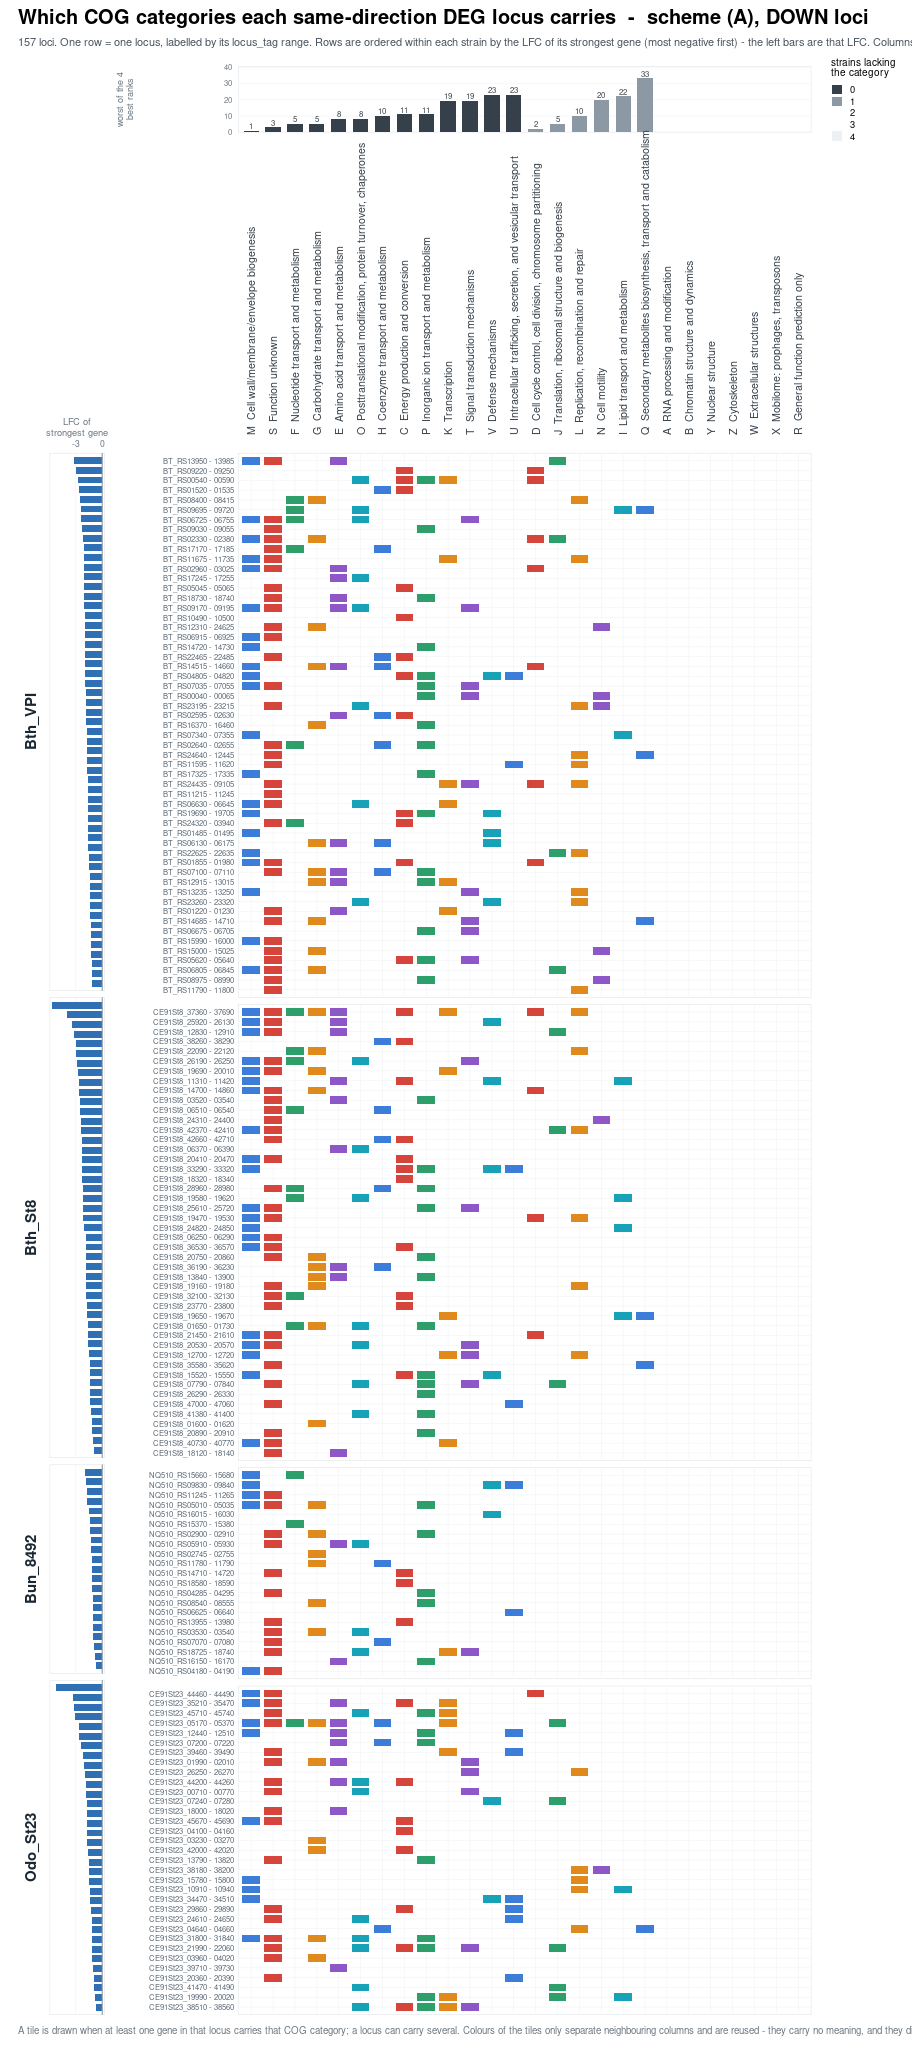

■ COGmap_B_dn.png（475 KB / 7.6 x 15.6 in）→ project 複製 OK
   locus 164 / COG を1つも持たない locus  2（空の行として残す）
   列順: E S M J G H F T P K O L C V I U N Q D A B Y Z W X R


Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”


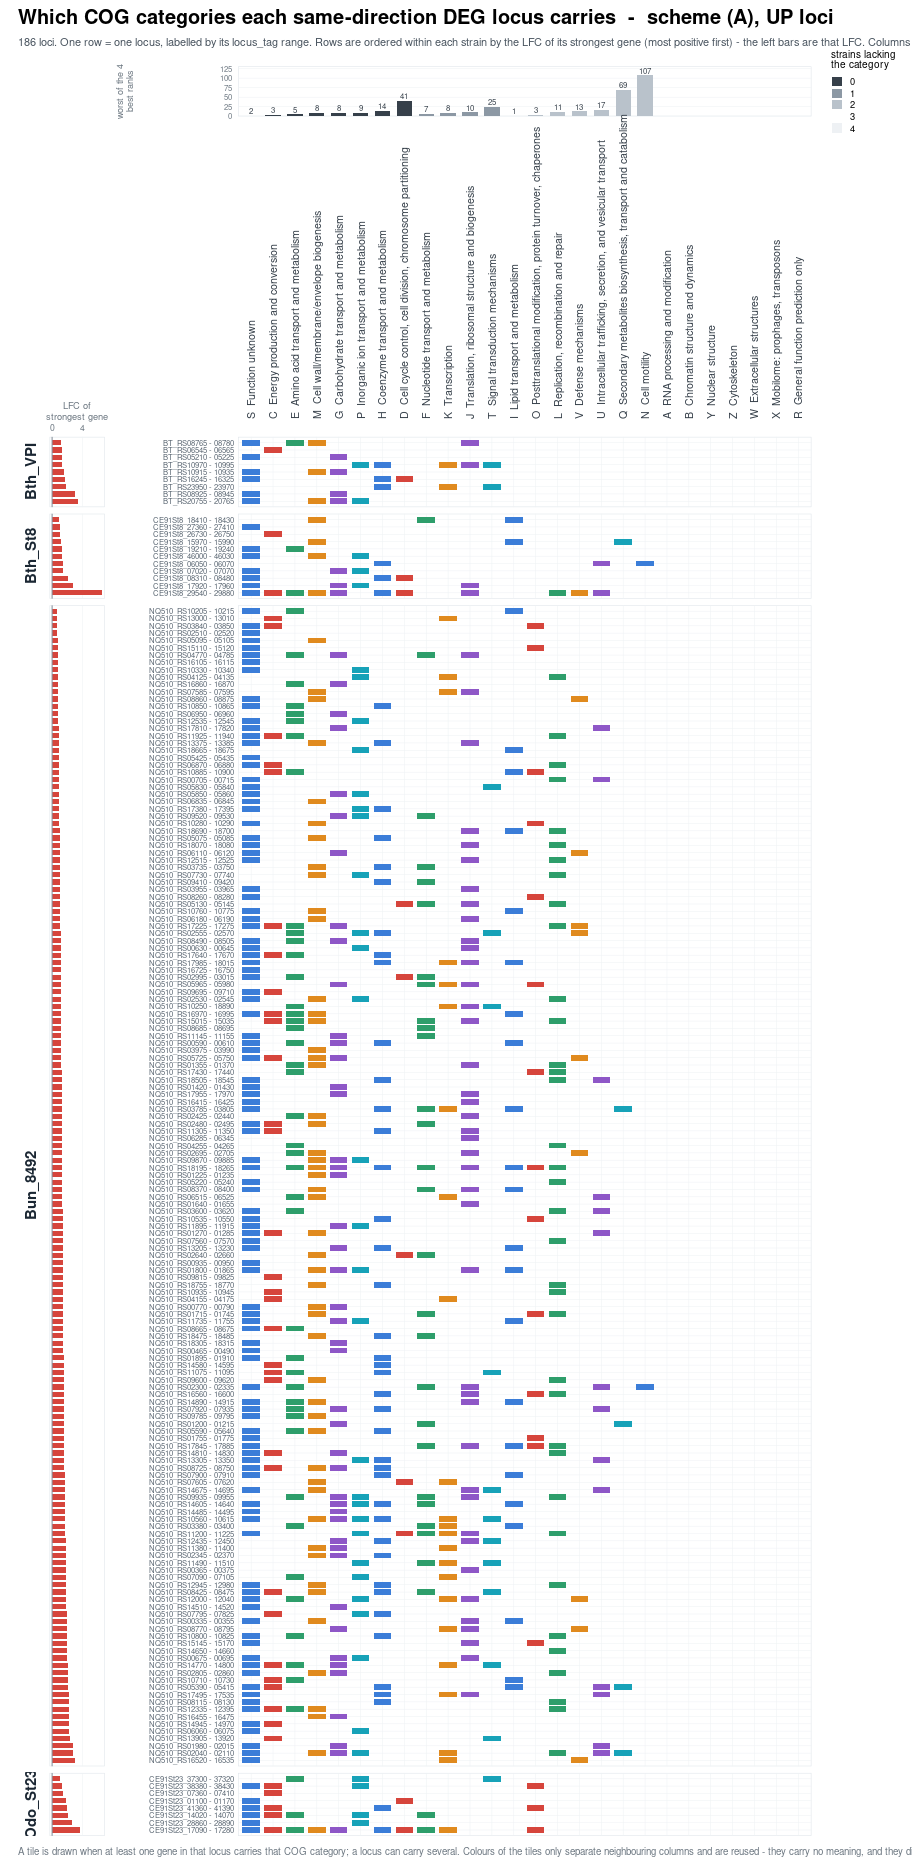

■ COGmap_B_up.png（413 KB / 7.6 x 13.5 in）→ project 複製 OK
   locus 134 / COG を1つも持たない locus  0（空の行として残す）
   列順: S M O H C K J F E G P D T V I L U Q N A B Y Z W X R


Warning message:
“Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).”


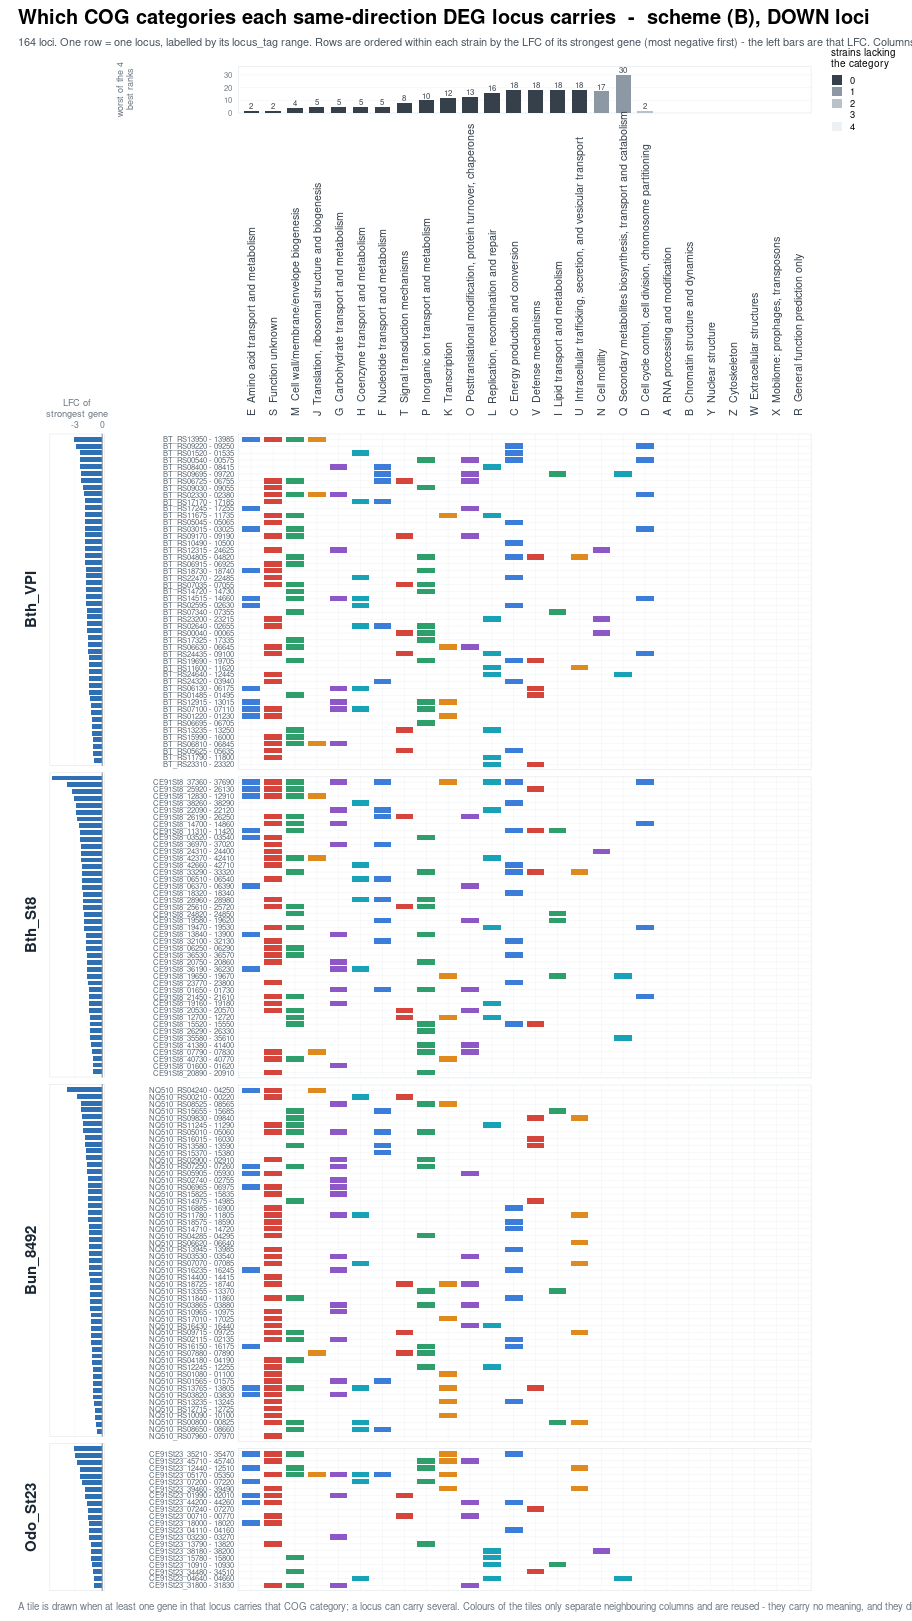

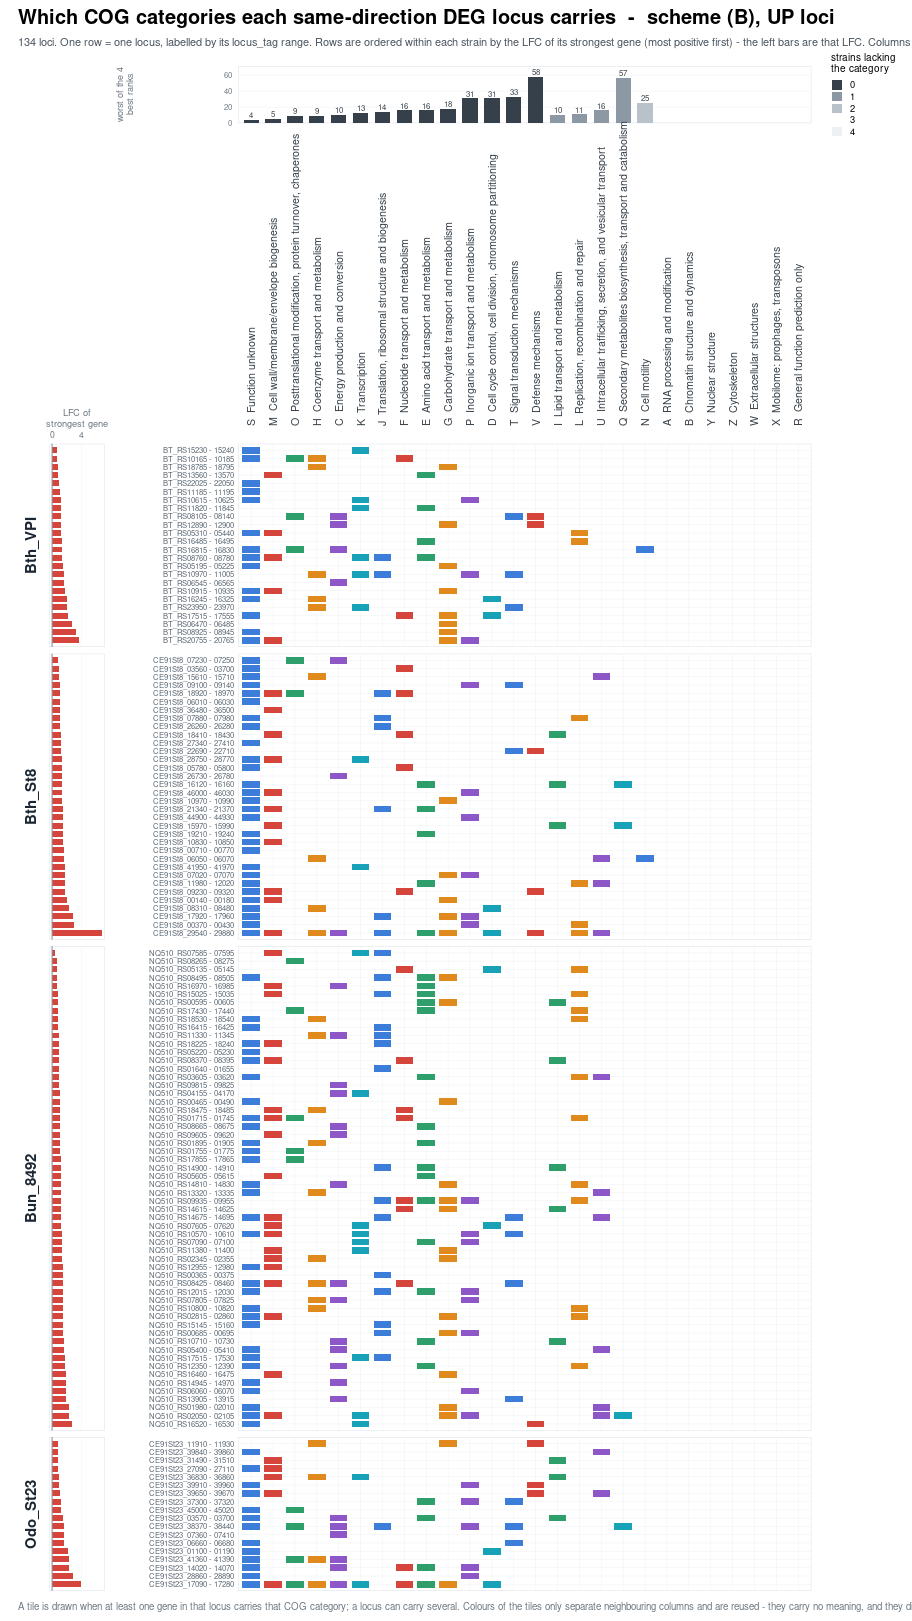

In [20]:
# ══════════════════════════════════════════════════════════════════
# セル6: locus × COG カテゴリのカラーマップ（図2）
# ══════════════════════════════════════════════════════════════════
# セル4 が書いた2つの CSV だけを入力にする。DESeq2 の結果には触らない。
# セル5 の 表5-2a（株ごとの上位10）と 表5-6（COG × 株）を1枚の図にしたもの。
#
# 図の構成（ユーザー指定）
#   ・1行 = 1 locus。行名は locus_tag の範囲（BT_RS13950 - 13985）
#   ・株は左端に縦書きで出す。株の中は「最強遺伝子の LFC」順（↓ なら小さい順）
#   ・列 = COG 26カテゴリ全部。0件のカテゴリも列として残す（無いことが結果）
#   ・タイルは「その locus の遺伝子が1つでもそのカテゴリを持つ」で塗る。
#     1つの locus が複数のカテゴリを持ちうるので、1行に複数タイルが出る
#
# ★ 並びの規則が図そのものから読めるようにしてある
#   左の棒 = 行順の根拠（最強遺伝子の LFC）
#   上の棒 = 列順の根拠（worst of the 4 best ranks）。棒の色 = 欠けている株の数
#
# ★ 列順は図ごとに違う（4図を A/低下 の順で固定していない）
#   従って配色も図ごとに貼り直す。色は隣の列を見分けるためだけで意味を持たない。
#   同じ COG が図によって別の色になるので、図どうしを色で追わないこと
#
# ★ 図の中は英語のみ（CLAUDE.md）。
#   aes() に渡る列名も ASCII にしてある。日本語の列名は凡例・軸名として
#   そのまま描かれることがあり、PNG では mbcsToSbcs で化ける
#
# ★ 列ラベルの中央揃え（実測で確かめた）
#   element_text(angle = 90) で回すと、ラベルが列の中心から左に 2.2 pt ずれる。
#   hjust / vjust は回転した軸ラベルの横位置に効かない（0 / 0.5 / 1 で描いた
#   PNG が md5 まで同一だった）。guide_axis(angle = 90) に渡すと ggplot2 側が
#   回転に合わせて justification を計算するので中心が合う（実測でずれ 0 px）
#
# ★ このセルは単体で実行できる

# ── (1) ライブラリ ────────────────────────────────────────────────
.libPaths(c("/home/tanoue/R/metatx-lib-4.4", .libPaths()))
library(dplyr)
library(tidyr)
library(ggplot2)
suppressMessages(library(patchwork))
cat(sprintf("ggplot2 %s / patchwork %s\n",
            packageVersion('ggplot2'), packageVersion('patchwork')))

# ── (2) パス ──────────────────────────────────────────────────────
path         = '/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
path_project = '/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome'
dir_gb       = file.path(path, 'genome')
if (!dir.exists(dir_gb)) dir.create(dir_gb, recursive = TRUE)
f_loci  = file.path(path_project, 'eptA_samedir_DEG_loci.csv')
f_genes = file.path(path_project, 'eptA_samedir_DEG_loci_genes.csv')

loci  = read.csv(f_loci,  stringsAsFactors = FALSE)
genes = read.csv(f_genes, stringsAsFactors = FALSE)
cat(sprintf("■ 入力: locus %s 行 / 構成遺伝子 %s 行\n",
            format(nrow(loci), big.mark=','), format(nrow(genes), big.mark=',')))

s4 = c('Bth_VPI','Bth_St8','Bun_8492','Odo_St23')

# ── (3) COG 26カテゴリの正式名（NCBI COG の原典英語）────────────
# ★ 並べ方は NCBI の分類順（情報処理 → 細胞過程 → 代謝 → 特徴づけ不良）。
#   図の列順はこの順ではなく下の mkord で決めるが、同点のときの
#   タイブレークにこの順を使うので、ここでの並び自体に意味がある
COGEN = c(
    J = 'Translation, ribosomal structure and biogenesis',
    A = 'RNA processing and modification',
    K = 'Transcription',
    L = 'Replication, recombination and repair',
    B = 'Chromatin structure and dynamics',
    D = 'Cell cycle control, cell division, chromosome partitioning',
    Y = 'Nuclear structure',
    V = 'Defense mechanisms',
    T = 'Signal transduction mechanisms',
    M = 'Cell wall/membrane/envelope biogenesis',
    N = 'Cell motility',
    Z = 'Cytoskeleton',
    W = 'Extracellular structures',
    U = 'Intracellular trafficking, secretion, and vesicular transport',
    O = 'Posttranslational modification, protein turnover, chaperones',
    X = 'Mobilome: prophages, transposons',
    C = 'Energy production and conversion',
    G = 'Carbohydrate transport and metabolism',
    E = 'Amino acid transport and metabolism',
    F = 'Nucleotide transport and metabolism',
    H = 'Coenzyme transport and metabolism',
    I = 'Lipid transport and metabolism',
    P = 'Inorganic ion transport and metabolism',
    Q = 'Secondary metabolites biosynthesis, transport and catabolism',
    R = 'General function prediction only',
    S = 'Function unknown')

# ── (4) locus × COG の対応表を作る ───────────────────────────────
# ★ COG_category は 'JMES' のように1文字が連なった文字列。
#   separate_rows(sep='') で1文字ずつに割る。rowwise() + リスト列でやると
#   先頭1文字しか取れない（実測で A046 が JMES ではなく E になった）
cg = genes %>%
    filter(COG_category != '') %>%
    tidyr::separate_rows(COG_category, sep = '') %>%
    filter(COG_category != '') %>%
    distinct(scheme, locus, k = COG_category)

cat(sprintf("  COG を持つ遺伝子 %s / %s 行（%.0f%%）→ locus×COG の対応 %s 組\n",
            format(sum(genes$COG_category != ''), big.mark=','),
            format(nrow(genes), big.mark=','),
            100*mean(genes$COG_category != ''), format(nrow(cg), big.mark=',')))
cat(sprintf("  COG 表に出てこない文字: %s\n",
            ifelse(all(cg$k %in% names(COGEN)), 'なし',
                   paste(setdiff(unique(cg$k), names(COGEN)), collapse=' '))))

# locus_tag の接頭辞を落として範囲を短く書く（BT_RS13950 - 13985）
sh = function(v) sub('^(BT_RS|NQ510_RS|CE91St8_|CE91St23_)', '', v)

# ── (5) 列の並びを決める ──────────────────────────────────────────
# ★ 規則（3段階）
#   1. 欠けている株の数が少ない順 … 4株そろって出るカテゴリを左へ
#   2. worst of the 4 best ranks が小さい順
#      = 株ごとに「そのカテゴリが最初に出る locus の順位」を取り、
#        4株ぶんの最大値。「4株すべてでここまでは上がる」という保証ランク
#   3. 4株のランクの合計が小さい順
#   4. 同点なら COGEN の並び（NCBI の分類順）
# ★ 1件も無いカテゴリは欠け 4 / ランク NA となり、自動的に右端にまとまる
mkord = function(sc, dr) {
    expand.grid(k = names(COGEN), strain = s4, stringsAsFactors = FALSE) %>%
        left_join(
            loci %>% filter(scheme == sc, dir == dr) %>%
                inner_join(cg, by = c('scheme','locus')) %>%
                group_by(k, strain) %>% summarise(r = min(rank), .groups = 'drop'),
            by = c('k','strain')) %>%
        group_by(k) %>%
        summarise(nmiss     = sum(is.na(r)),
                  worstrank = ifelse(all(is.na(r)), NA, max(r, na.rm = TRUE)),
                  ranksum   = ifelse(all(is.na(r)), NA, sum(r, na.rm = TRUE)),
                  .groups = 'drop') %>%
        arrange(nmiss, worstrank, ranksum, match(k, names(COGEN)))
}

# 隣の列を見分けるためだけの色。6色を順に繰り返す（意味は持たせない）
PALSEQ  = c('#3b7dd8','#d6453c','#2e9e6b','#e08a1e','#8e57c7','#17a2b8')
# 上の棒の色 = 欠けている株の数。濃いほど「4株そろっている」
MISSCOL = c(`0`='#36404a', `1`='#8c98a4', `2`='#b9c2cb', `3`='#d4dae0', `4`='#eef1f4')

# ── (6) 図を組む ──────────────────────────────────────────────────
mkfig = function(sc, dr) {

    # 行（locus）の並び: 株 → 株内は最強遺伝子の LFC 順
    # ★ y 軸は下から上に伸びるので rev() する。1位が一番上に来る
    nb = loci %>% filter(scheme == sc, dir == dr) %>%
        mutate(strain = factor(strain, levels = s4),
               lab    = sprintf('%s - %s', gene_first, sh(gene_last))) %>%
        arrange(strain, rank)
    lv = rev(nb$locus)
    nb$locus = factor(nb$locus, levels = lv)
    ylab = setNames(nb$lab, as.character(nb$locus))

    # 列の並びと配色は、この図の scheme × dir 自身から決める
    o      = mkord(sc, dr)
    COGORD = o$k
    PAL    = setNames(rep(PALSEQ, length.out = length(COGORD)), COGORD)
    o      = o %>% mutate(k     = factor(k, levels = COGORD),
                          nmiss = factor(nmiss, levels = 0:4))

    # タイルの中身
    # ★ inner_join は factor を character に戻す。ここで factor を貼り直さないと
    #   カラーマップ側だけ locus がアルファベット順になり、左の棒グラフとずれる（実測）
    d = nb %>% dplyr::select(locus, strain, rank) %>%
        inner_join(cg %>% filter(scheme == sc), by = 'locus') %>%
        mutate(k     = factor(k, levels = COGORD),
               locus = factor(as.character(locus), levels = lv))
    stopifnot(identical(levels(d$locus), levels(nb$locus)))   # 左右の行順が同じ

    UP = dr == 'up'
    base = theme_minimal(base_size = 8) +
        theme(panel.grid.minor = element_blank(),
              panel.background = element_rect(fill = NA, colour = '#dde3e9', linewidth = .3),
              plot.margin      = margin(0, 0, 0, 0))

    # ── 上段: 列の並びの根拠 ──────────────────────────────────────
    p_top = ggplot(o, aes(x = k, y = worstrank, fill = nmiss)) +
        geom_col(width = .7) +
        geom_text(aes(label = worstrank), vjust = -.3, size = 1.65,
                  colour = '#36404a', na.rm = TRUE) +
        scale_fill_manual(values = MISSCOL, drop = FALSE,
                          name = 'strains lacking\nthe category',
                          na.translate = FALSE) +
        scale_x_discrete(drop = FALSE) +
        scale_y_continuous(expand = expansion(mult = c(0, .22))) +
        labs(x = NULL, y = 'worst of the 4\nbest ranks') + base +
        theme(panel.grid.major.x = element_blank(),
              panel.grid.major.y = element_line(linewidth = .15, colour = '#eef1f4'),
              # ★ 列名はカラーマップ側（p_main の上）に付ける。棒グラフは一番外側
              axis.text.x  = element_blank(),
              axis.text.y  = element_text(size = 4.6, colour = '#6b7680'),
              axis.title.y = element_text(size = 5.4, colour = '#6b7680',
                                          lineheight = .95, margin = margin(r = 1)),
              legend.position = 'right',
              legend.title    = element_text(size = 6),
              legend.text     = element_text(size = 5.6),
              legend.key.size = unit(7, 'pt'),
              plot.margin     = margin(1, 1, 1, 1))

    # ── 左: 行の並びの根拠 ────────────────────────────────────────
    p_left = ggplot(nb, aes(x = LFC_ext, y = locus)) +
        geom_col(width = .72, fill = ifelse(UP, '#d6453c', '#2f6fb3')) +
        geom_vline(xintercept = 0, linewidth = .3, colour = '#8a949e') +
        scale_y_discrete(expand = expansion(add = .8)) +
        scale_x_continuous(position = 'top', n.breaks = 3) +
        facet_grid(strain ~ ., scales = 'free_y', space = 'free_y', switch = 'y') +
        labs(x = 'LFC of\nstrongest gene', y = NULL) + base +
        theme(panel.grid.major.y = element_blank(),
              panel.grid.major.x = element_line(linewidth = .15, colour = '#eef1f4'),
              strip.placement    = 'outside',
              strip.text.y.left  = element_text(angle = 90, face = 'bold',
                                                size = 9, colour = '#1b2733'),
              # ★ 行名はカラーマップ側に付ける。棒グラフは一番外側
              axis.text.y  = element_blank(),
              axis.text.x  = element_text(size = 5.2, colour = '#6b7680'),
              axis.title.x = element_text(size = 5.6, colour = '#6b7680',
                                          lineheight = .95, margin = margin(b = 1)),
              plot.margin  = margin(1, 1, 1, 1))

    # ── 本体: COG タイル ──────────────────────────────────────────
    p_main = ggplot(d, aes(x = k, y = locus, fill = k)) +
        geom_tile(width = .8, height = .8) +
        scale_fill_manual(values = PAL, guide = 'none') +
        scale_y_discrete(labels = ylab, expand = expansion(add = .8)) +
        # ★ 回転は theme ではなく guide_axis に渡す（冒頭の注を参照）
        scale_x_discrete(drop = FALSE, position = 'top',
                         labels = function(b) sprintf('%s  %s', b, COGEN[b]),
                         guide  = guide_axis(angle = 90)) +
        facet_grid(strain ~ ., scales = 'free_y', space = 'free_y') +
        labs(x = NULL, y = NULL) + base +
        theme(panel.grid.major = element_line(linewidth = .15, colour = '#eef1f4'),
              strip.text.y = element_blank(),
              axis.text.y  = element_text(size = 4.6, colour = '#5a6672', hjust = 1),
              axis.text.x  = element_text(size = 6.4, colour = '#36404a',
                                          margin = margin(b = 1)),
              axis.ticks.length = unit(1, 'pt'),
              plot.margin  = margin(1, 1, 1, 1))

    # ── 貼り合わせ ────────────────────────────────────────────────
    # ★ patchwork は行・列をまたいでパネル領域を揃える。
    #   左上は空白（plot_spacer）、右上が列の棒、左下が行の棒、右下が本体
    (plot_spacer() + p_top + p_left + p_main +
     plot_layout(ncol = 2, widths = c(0.25, 2.6),
                 heights = c(0.45, 0.068 * nrow(nb)))) +
    plot_annotation(
        title = sprintf(paste0('Which COG categories each same-direction DEG locus carries',
                               '  -  scheme (%s), %s loci'),
                        sc, ifelse(UP, 'UP', 'DOWN')),
        subtitle = sprintf(paste0(
            '%d loci. One row = one locus, labelled by its locus_tag range. ',
            'Rows are ordered within each strain by the LFC of its strongest gene ',
            '(%s first) - the left bars are that LFC. ',
            'Columns are ordered by how many of the four strains lack the category ',
            '(bar colour), then by the worst of the four per-strain best ranks ',
            '(bar height; i.e. the rank the category reaches in every one of the four ',
            'strains), then by their sum; each figure uses its own order, so the columns ',
            'are NOT comparable between figures.'),
            nrow(nb), ifelse(UP, 'most positive', 'most negative')),
        caption = paste0(
            'A tile is drawn when at least one gene in that locus carries that COG ',
            'category; a locus can carry several. ',
            'Colours of the tiles only separate neighbouring columns and are reused - ',
            'they carry no meaning, and they differ between the four figures. ',
            'Category names are the NCBI COG originals. ',
            'A blank row is a locus whose genes carry no COG at all. ',
            sprintf('The %d categories with no bar occur in no locus of this panel.',
                    sum(is.na(o$worstrank)))),
        theme = theme(plot.title    = element_text(size = 12, face = 'bold'),
                      plot.subtitle = element_text(size = 6.6, colour = '#4a5560'),
                      plot.caption  = element_text(size = 5.8, colour = '#6b7680', hjust = 0)))
}

# ── (7) 4枚を書き出して notebook にも表示する ────────────────────
# ★ 高さは locus 数に比例させる。1 locus あたり 0.068 inch。
#   4.4 inch はタイトル・サブタイトル・列ラベル・キャプションの固定分
# ★ セル6-2 が PDF に書き出すので、図そのものと高さを残しておく。
#   ここで作り直させると二重管理になり、片方だけ直したときに食い違う
figs_cog = list(); h_cog = c()
for (x in list(c('A','dn'), c('A','up'), c('B','dn'), c('B','up'))) {
    sc = x[1]; dr = x[2]
    nb = loci %>% filter(scheme == sc, dir == dr)
    n  = nrow(nb)
    h  = 4.4 + n * 0.068
    p  = mkfig(sc, dr)
    key = sprintf('%s_%s', sc, dr); figs_cog[[key]] = p; h_cog[key] = h

    f  = file.path(dir_gb, sprintf('COGmap_%s_%s.png', sc, dr))
    ggsave(f, p, width = 7.6, height = h, dpi = 180, bg = 'white', limitsize = FALSE)
    ok = file.copy(f, file.path(path_project, basename(f)), overwrite = TRUE)

    # 検品: COG が1つも無い locus（図では空の行になる。消さずに残す）
    nocog = sum(!(nb$locus %in% (cg %>% filter(scheme == sc) %>% pull(locus))))
    cat(sprintf("■ %s（%.0f KB / %.1f x %.1f in）→ project 複製 %s\n",
                basename(f), file.size(f)/1024, 7.6, h, ifelse(ok, 'OK', '!! 失敗')))
    cat(sprintf("   locus %3d / COG を1つも持たない locus %2d（空の行として残す）\n", n, nocog))
    cat(sprintf("   列順: %s\n", paste(mkord(sc, dr)$k, collapse = ' ')))

    options(repr.plot.width = 7.6, repr.plot.height = h)
    print(p)
}

## セル6-2: 図2 をベクタ（PDF）でも保存する

セル3-2 と同じ形。セル6 が残した `figs_cog` / `h_cog` を**そのまま**書き出す（図は作り直さない）。

★ **`device = 'pdf'` ではなく `cairo_pdf`。**前者だと Helvetica が埋め込まれない（`pdffonts` で `emb=no`）。

★ 高さは図ごとに違う（locus 数に比例）ので `h_cog` から引く。

出力: `pdf/COGmap_{A,B}_{dn,up}.pdf`（4枚）

In [38]:
# ══════════════════════════════════════════════════════════════════
# セル6-2: 図2（COG カラーマップ）をベクタ（PDF）でも保存する
# ══════════════════════════════════════════════════════════════════
# セル3-2 と同じ形。PNG は notebook に貼るためのもので、図として後から
# 手を入れるにはベクタが要る。project 直下の pdf/ に置く。
#
# ★ セル6 を先に実行しておくこと
#   セル6 が残した figs_cog / h_cog をそのまま書き出す。
#   ここで図を作り直すと二重管理になり、片方だけ直したときに食い違う
#
# ★ device は 'pdf' ではなく cairo_pdf（セル3-2 と同じ理由）
#   device='pdf' だと Helvetica が埋め込まれない（実測 pdffonts で emb=no）。
#   cairo_pdf なら NimbusSans のサブセットが埋め込まれ、文字は文字のまま残る
#
# ★ 高さは図ごとに違う（locus 数に比例）。セル6 が記録した h_cog を使う
#
# ★ 図中は ASCII のみ（セル6 の時点でそうしてある）。
#   非 ASCII が混ざると警告が出るので、下で警告を握り潰さずに拾う

if (!exists('figs_cog') || length(figs_cog) != 4 || !exists('h_cog'))
    stop('figs_cog / h_cog が無い。先にセル6 を実行すること')

# ★ 出力はまず scratch に書き、必要なものを project へ複製する（CLAUDE.md）
#   project にしか無い成果物を作らない。scratch が常に全部を持つ
pdf_dir  = file.path(path, 'pdf')
pdf_proj = file.path(path_project, 'pdf')
dir.create(pdf_dir,  recursive = TRUE, showWarnings = FALSE)
dir.create(pdf_proj, recursive = TRUE, showWarnings = FALSE)

res_pdf2 = list()
for (key in names(figs_cog)) {
    f = file.path(pdf_dir, sprintf('COGmap_%s.pdf', key))
    w = character(0)
    withCallingHandlers(
        ggsave(f, figs_cog[[key]], width = 7.6, height = unname(h_cog[key]),
               device = grDevices::cairo_pdf, limitsize = FALSE),
        warning = function(e) { w <<- c(w, conditionMessage(e)); invokeRestart('muffleWarning') })
    info = tryCatch(system2('pdfinfo',  f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    font = tryCatch(system2('pdffonts', f, stdout = TRUE, stderr = FALSE), error = function(e) character(0))
    sz   = sub('^Page size: *', '', grep('^Page size', info, value = TRUE))
    fn   = font[-(1:2)]
    res_pdf2[[key]] = data.frame(
        図       = key,
        file     = basename(f),
        MB       = round(file.size(f)/1024^2, 2),
        ページ   = ifelse(length(sz) == 0, '?', sz[1]),
        フォント = ifelse(length(fn) == 0, '?',
                          paste(unique(sub('^[A-Z]{6}\\+', '', sub(' .*', '', trimws(fn)))),
                                collapse = ', ')),
        # ★ pdffonts の emb 列は「末尾から5番目のトークン」。
        #   桁位置で substr すると type 欄が 'CID Type 0C' のように伸びてずれる（実測）
        埋め込み = ifelse(length(fn) == 0, '?',
                          ifelse(all(vapply(strsplit(trimws(fn), ' +'),
                                            function(v) v[length(v)-4], character(1)) == 'yes'),
                                 '全部 yes', '!! no がある')),
        警告     = ifelse(length(w) == 0, 'なし', paste(w, collapse = ' / ')))
    ok = file.copy(f, file.path(pdf_proj, basename(f)), overwrite = TRUE)
    cat(sprintf("■ %s（%.2f MB / %s）→ project 複製 %s / フォント埋め込み %s / 警告 %s\n",
        basename(f), file.size(f)/1024^2, res_pdf2[[key]]$ページ, ifelse(ok,'OK','!! 失敗'),
        res_pdf2[[key]]$埋め込み, res_pdf2[[key]]$警告))
}

# ── 図2 のファイル対応 ──────────────────────────────────────────
k4    = names(figs_cog)
f_png = file.path(path_project, sprintf('COGmap_%s.png', k4))
f_pdf = file.path(pdf_dir,      sprintf('COGmap_%s.pdf', k4))
data.frame(図     = rep(k4, 2),
           形式   = rep(c('PNG（notebook 内で読む用・180 dpi）',
                          'PDF（ベクタ・図として触る用）'), each = length(k4)),
           file   = sub('^.*/', '', c(f_png, f_pdf)),
           場所   = sub('/[^/]*$', '', c(f_png, f_pdf)),
           MB     = round(file.size(c(f_png, f_pdf))/1024^2, 2)) %>%
  arrange(図, 形式) %>% as.data.frame()

■ COGmap_A_dn.pdf（0.04 MB / 547 x 1085 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).
■ COGmap_A_up.pdf（0.04 MB / 547 x 1227 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).
■ COGmap_B_dn.pdf（0.04 MB / 547 x 1119 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).
■ COGmap_B_up.pdf（0.04 MB / 547 x 972 pts）→ project 複製 OK / フォント埋め込み 全部 yes / 警告 Removed 7 rows containing missing values or values outside the scale range (`geom_col()`).


図,形式,file,場所,MB
<chr>,<chr>,<chr>,<chr>,<dbl>
A_dn,PDF（ベクタ・図として触る用）,COGmap_A_dn.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.04
A_dn,PNG（notebook 内で読む用・180 dpi）,COGmap_A_dn.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.43
A_up,PDF（ベクタ・図として触る用）,COGmap_A_up.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.04
A_up,PNG（notebook 内で読む用・180 dpi）,COGmap_A_up.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.52
B_dn,PDF（ベクタ・図として触る用）,COGmap_B_dn.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.04
B_dn,PNG（notebook 内で読む用・180 dpi）,COGmap_B_dn.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.47
B_up,PDF（ベクタ・図として触る用）,COGmap_B_up.pdf,/mnt/scratch/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome/pdf,0.04
B_up,PNG（notebook 内で読む用・180 dpi）,COGmap_B_up.png,/home/tanoue/261016_Xiaoxi_eptAoligo_2wFeces_Metatranscriptome,0.41


# 考察: ステージ7

**「経路が下がった」の実体は2種類あり、ゲノム上の位置で初めて分かれた。**

|- | まとまって動く | 散らばって動く |
|---|---|---|
| 例 | **Fe-S 組立 `suf`**（18遺伝子中 16）／**TCA 酸化方向**（11中 9）／**F型ATPase**（18中 12） | **酸化ストレス**（50中 30）／**銅排出 `copA`/`actP`**（5中 4）／**胆汁酸脱抱合 BSH**（4中 3） |
| 位置 | 枠（同機能が 10 kb 以内）にも帯（同方向 DEG 3連続以上）にも入る | どちらにも入らない |
| 読み | **転写単位ごと**の制御として説明できる | 個々の遺伝子が**別々の場所で同じ向きの入力**を受けている |

前者はステージ6 の「経路が下がった」をそのまま裏づけるが、**後者は1オペロンの産物ではない**。CLAUDE.md の確認項目「1オペロンが効いているだけではないか」は、これで**両方向に**答えが出た。

とくに**銅排出は5遺伝子すべてが4株そろって低下・全部有意**（WT 平均 2,700〜80,155 の高発現）でありながら、**4株とも単独遺伝子**。座位検出だけを見ていたら見落とす所見で、遺伝子単位の図（セル3-4）を分けた理由がここにある。

COG で見ると scheme (A) の低下側は **`M`（細胞壁・膜・外被の生合成）が4株とも1位**で、外被まわりが最も強く下がる。一方 Bun_8492 の上昇はリボソーム超オペロン（30遺伝子 33 kb）・`nuo`（10遺伝子）・PUL（293遺伝子中 211 が単独）に偏り、**低下側は共通・上昇側は1株依存**という対比がゲノム地図の上でも確認できた。

★ **「オペロン」と呼んだ枠は近接の指標でしかない。**規則は「同じ機能の遺伝子が 10 kb 以内に2つ以上」で、**鎖の向きも遺伝子間距離も間に挟まる遺伝子も見ていない**。実測で 36 枠のうち 13 に無関係な遺伝子が挟まり、4 で鎖が混在し、9 に 200 bp を超えるギャップがある。同一転写単位かどうかは別途 RNA-seq の連続性などで確かめる必要がある。

# 全体の考察（ステージ1〜7）

**eptA を欠いたコンソーシアムでは、菌叢の構成が動き、そのうえで「下がるものは4株共通でまとまり、上がるものは1株に偏る」。**

|- | 内容 |
|---|---|
| 菌叢の構成 | `Bun_8492` 72.4% → **79.7%**、`Bth` 2株 23.9% → **17.0%**。この入れ替わり自体が eptA 変異の定着結果 |
| 下がる側（4株共通） | F型ATPase／PPP 酸化相／酸化ストレス応答／Fe-S クラスター組立／**銅排出**／**線毛 Mfa1/fimbrillin**／外膜・表層 |
| 上がる側 | 翻訳・リボソーム／脂肪酸伸長／呼吸鎖（`nuo`・`Sdh`）／PUL — **いずれも `Bun_8492` 単独** |


**「下がる側（4株共通）」の根拠**（n = アノテーションの数、`↓`/`↑` は scheme A で padj<0.05 のもの。7項目とも **4/4株で有意に低下**）

|-| VPI | St8 | Bun | Odo | 最も強い遺伝子 |
|---|---|---|---|---|---|
| F型ATPase `atpA`–`atpH` | 1（↓1） | 1（↓1） | 8（↓6） | 8（↓7） | `CE91St8_30990` `atpG` −1.79 |
| PPP 酸化相 `zwf`/`pgl`/`gnd` | 3（↓3） | 2（↓2） | 5（↓3） | 3（↓2） | `CE91St8_36210` −1.83 |
| 酸化ストレス応答 | 10（↓8 ↑1） | 11（↓9 ↑1） | 13（↓7 ↑2） | 16（↓11） | `CE91St23_07220` SOD[Fe] −2.41 |
| Fe-S クラスター組立 `suf` | 3（↓3） | 3（↓3） | 5（↓4） | 7（↓7） | `CE91St8_06390` `sufC` −2.29 |
| 銅排出 `copA`/`actP` | 1（↓1） | 1（↓1） | 2（↓2） | 1（↓1） | `CE91St8_34640` `copA` −2.30 |
| 線毛 Mfa1/fimbrillin | 8（↓3） | 2（↓1） | 16（↓2） | 7（↓5） | `CE91St23_44470` −4.79 |
| 外膜 OmpA 科（PFAM） | 16（↓6） | 23（↓13 ↑3） | 34（↓8 ↑3） | 22（↓5 ↑2） | `CE91St23_09580` −2.92 |

★ **根拠の強さは項目で違う。**`Fe-S` と `銅排出` は**持っている遺伝子がほぼ全部下がる**（suf 18本中17本、copA/actP 5本中5本）ので最も強い。一方 **F型ATPase の `Bth` 2株は `atpG` 1本しか載っていない**（mappability の制約、CLAUDE.md §3）ので、「4株共通」とは言えても **Bth 側の根拠は1遺伝子ずつ**しかない。**酸化ストレス応答と外膜 OmpA 科は上昇するものも少数混ざる**（それぞれ4本・8本）ので、「全部が下がる」ではなく「下がるほうが優勢」。

**線毛（Mfa1 / fimbrillin 科）も4株共通で下がる。**33遺伝子あり、**有意に動いた 11 本はすべて低下、上昇は1本も無い**（`Bth_VPI` 3 / `Bth_St8` 1 / `Bun_8492` 2 / `Odo_St23` 5）。ただし**株ごとに別のパラログ**が動いており、33本中22本は動いていない。`Odo_St23` では `product` が `hypothetical protein` のままで、PFAM からしか拾えない。最も強いのは `CE91St23_44470`（**−4.79**）で、手で付けた「Mfa1 線毛（Type V）候補」の領域と一致する。**胆汁酸脱抱合は4株共通ではない**ので、上の表から外した（下記）。

**株によって動きが違うもの**（n = アノテーションの数、有意は scheme A）

|-| VPI | St8 | Bun | Odo | 読み |
|---|---|---|---|---|---|
| TCA `prpC`/`acnA`/`icd` | 3（**3↓**） | 3（**3↓**） | 3（**3↓**） | **0** | **Odo にはこの3酵素が載っていない。**Bacteroides 3株のみの所見 |
| `Sdh` / `Frd` | **0** | **0** | 3（**3↑**） | 3（0） | Bth 2株にアノテーション無し。**上昇は Bun だけ** |
| NADH `nuo` | 1 | 1 | 10（**3↑**） | 5（0） | Odo も10本中5本持つが動かない。**上昇は Bun だけ** |
| シトクロム bd | **0** | **0** | 2（0） | 3（1↓） | Bth 2株に無し。**4株共通ではない** |
| BAM 複合体 | **0** | **0** | 4（**4↑**） | 2（1↑） | Bth 2株に無し |
| 胆汁酸脱抱合 BSH | **0** | 1（1↓） | **0** | 3（**2↓**） | **St8 と Odo だけ。**VPI と Bun は遺伝子を持たない |
| `upxY`/`upxZ` | 5（0） | **0** | 15（**6↑**） | **0** | CPS 座位スイッチの制御因子。**動くのは Bun だけ** |
| フマラーゼ | 1（0） | 1（0） | 1（0） | 3（**2↑**） | **Odo だけ**（`CE91St23_17090` +3.52 / `17100` +3.27）。CPS 座位の中にある |
| PUL `SusC`/`SusD` | 40（3↑8↓） | 33（3↑6↓） | 115（**36↑**6↓） | 99（5↑7↓） | 4株とも多数持つが、**上昇が優勢なのは Bun だけ**。他3株はむしろ低下側 |
| CPS 座位の切り替え | — | **★ 3座位** | — | ★ 2座位 | `Bth_St8` はステージ4 の PC1 の主体。`29540–29910` が KO で ON、他2座位は WT で ON |

**読み方。**上の「4株共通で下がる」群は**どの株でも同じ向きに動く**ので eptA 欠失そのものへの応答として扱える。一方この表は、**(1) そもそも遺伝子を持たない**（Bth の `Sdh`/`Frd`、Odo の TCA 3酵素）、**(2) 持っているが動かない**（Odo の `nuo` 5本・`Sdh`/`Frd` 3本）、**(3) その株だけ動く**（Bun の `nuo`・PUL・`upxY`/`upxZ`、Odo のフマラーゼ）の3つが混ざっている。**(1) と (2) は意味が違う**ので分けて読む必要がある。

エネルギー産生と抗酸化が下がり、翻訳と増殖装置が上がる**「増殖に振った」典型的なパターン**。ただし **(A) 全株プールと (B) 株ごとを両方出したことで、`Bun_8492` の上昇の約半分は菌量の増加で説明できる**ことが分かった。片方だけでは「その菌が発現を上げた」と誤読するところだった。

`eptA` は lipid A に phosphoethanolamine を付ける酵素なので、**一次の予測は CAMP 耐性・LPS 合成・外膜ストレス応答**だった。実際に4株共通で動いたのは**エネルギーと抗酸化**で、外膜については**タンパクが減る一方 BAM（×2.42）と Lpt（×1.72）は増える**という食い違った動きになった。予測どおりではないが、外被まわりが最も強く動いている点（COG `M` が4株とも1位）は一致する。

★ **本データから書けないこと。**(1) F型ATPase の**向き**（可逆機械で、決めるのは熱力学であって転写量ではない）。(2) **因果**（`eptA` 欠失 → 菌叢変化 → 発現変化 の順序は本データでは分離できない）。(3) **絶対量**（median-of-ratios 正規化は検体ごとの総量をそろえるので、spike-in か総菌量 qPCR が要る）。

★ **残す未決。**CPS 座位の切り替わり（`Bth_St8` と `Odo_St23` で逆向きの座位が隣り合う）、銅排出の一斉低下の機構、`Bun_8492` の PUL 上昇の意味。いずれも**本データでは所見どまり**で、追加実験が要る。